# JALWEALTH AI 

## Integrated Business Intelligence, Environmental Analytics & Predictive Intelligence System 
**Project Category:** Artificial Intelligence | Data Science | Business Analytics | Environmental 
Sustainability 

**Project Vision:** Transforming Water Hyacinth Waste into Economic Opportunity through 
Data-Driven Intelligence. 

### 1. Executive Summary 
JALWEALTH AI is an integrated AI-powered analytical framework designed to evaluate the 
business, financial, environmental, and social impact of converting invasive Water Hyacinth 
biomass into sustainable commercial products. 
The system combines historical sales intelligence, financial performance analysis, 
environmental impact measurement, machine learning, demand forecasting, and 
decision-support recommendations. 
    
### 2. Core Objectives
- Analyze historical business performance.
- Identify profitable products and customer segments.
- Evaluate production and operational costs. 
- Measure water hyacinth utilization and waste diversion.
- Forecast future product demand and revenue.
- Develop predictive models for business planning.
- Generate actionable, data-driven recommendations. 

### 3. Expected Outcomes 
1. Business Performance Intelligence 
2. Financial Sustainability Assessment 
3. Environmental Impact Analytics 
4. Predictive Demand Intelligence 
5. Strategic Decision Support 

### 4. Technology Stack 
Python | Pandas | NumPy | Matplotlib | Seaborn | Scikit-learn | SVGWrite | SHAP --- 
**Important:** All model predictions and business recommendations will be evaluated against 
the available dataset. Forecasts will be treated as estimates, not guaranteed future outcomes. 

In [1]:
 # IMPORT LIBRARIES & CONFIGURATION

In [2]:
import os 
import warnings 
import json 
import math 
 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import svgwrite 
 
from pathlib import Path 
from IPython.display import display, SVG, Markdown 
 
from sklearn.model_selection import ( 
    train_test_split, 
    TimeSeriesSplit, 
    cross_val_score 
) 
 
from sklearn.preprocessing import ( 
    StandardScaler, 
    OneHotEncoder, 
    LabelEncoder 
) 
 
from sklearn.impute import SimpleImputer 
from sklearn.pipeline import Pipeline 
from sklearn.compose import ColumnTransformer 
from sklearn.metrics import ( 
    mean_absolute_error, 
    mean_squared_error, 
    r2_score, 
    accuracy_score, 
    classification_report, 
    confusion_matrix 
) 
 
warnings.filterwarnings("ignore") 
# Professional visualization settings 
sns.set_theme(style="whitegrid", context="notebook") 
plt.rcParams["figure.figsize"] = (12, 6) 
plt.rcParams["figure.dpi"] = 120 
plt.rcParams["axes.titleweight"] = "bold" 
plt.rcParams["font.family"] = "DejaVu Sans" 
# Project directories 
PROJECT_NAME = "JALWEALTH_AI" 
BASE_DIR = Path.cwd() 
OUTPUT_DIR = BASE_DIR / "JALWEALTH_AI_Outputs" 
ARCHITECTURE_DIR = OUTPUT_DIR / "Architecture" 
CHART_DIR = OUTPUT_DIR / "Charts" 
REPORT_DIR = OUTPUT_DIR / "Reports" 
for folder in [ 
OUTPUT_DIR, 
ARCHITECTURE_DIR, 
CHART_DIR, 
REPORT_DIR]: 
    folder.mkdir(parents=True, exist_ok=True) 
# Reproducibility 
RANDOM_STATE = 42 
np.random.seed(RANDOM_STATE) 

print("=" * 65) 
print("JALWEALTH AI | ANALYTICS ENVIRONMENT") 
print("=" * 65) 
print("Python Environment     : Ready") 
print("Data Analysis          : Ready") 
print("Machine Learning       : Ready")
print("Visualization          : Ready") 

print("SVG Architecture       : Ready") 
print("Output Directory       :", OUTPUT_DIR)
print("=" * 65) 




JALWEALTH AI | ANALYTICS ENVIRONMENT
Python Environment     : Ready
Data Analysis          : Ready
Machine Learning       : Ready
Visualization          : Ready
SVG Architecture       : Ready
Output Directory       : C:\Users\User\JALWEALTH_AI_Outputs


In [3]:
# LOAD EXCEL WORKBOOK 

In [4]:
FILE_PATH = ("JALWEALTH_AI_Comprehensive_Business_Environmental_Predictive_Model_v3.xlsx") 

# Load workbook 
excel_file = pd.ExcelFile(FILE_PATH) 
 
print("TOTAL SHEETS:", len(excel_file.sheet_names)) 
print("\nAVAILABLE SHEETS:") 
 
for index, sheet in enumerate(excel_file.sheet_names, start=1): 
    print(f"{index}. {sheet}") 
 
# Load the main sales dataset 
sales_df = pd.read_excel( 
    FILE_PATH, 
    sheet_name="JALWEALTH Sales Data" 
) 
 
print("\nSALES DATASET OVERVIEW") 
print("-" * 60) 
 
print("Dataset Shape:", sales_df.shape) 
print("Total Records:", len(sales_df)) 
print("Total Features:", len(sales_df.columns)) 
 
display(sales_df.head()) 
 
# Inspect all worksheet dimensions 
print("\nWORKBOOK STRUCTURE") 
 
for sheet in excel_file.sheet_names: 
    temp_df = pd.read_excel(FILE_PATH, sheet_name=sheet) 
    print( 
        f"{sheet:<35} | " 
        f"Rows: {temp_df.shape[0]:<7} | " 
        f"Columns: {temp_df.shape[1]}" 
    )

TOTAL SHEETS: 6

AVAILABLE SHEETS:
1. Executive Dashboard
2. JALWEALTH Sales Data
3. Cost & Break-Even Analysis
4. Environmental Impact
5. Predictive Forecast 2026
6. Product Guide

SALES DATASET OVERVIEW
------------------------------------------------------------
Dataset Shape: (9976, 32)
Total Records: 9976
Total Features: 32


,Order ID,Order Date,Year-Month,Delivery Method,Customer Segment,Country,City / District,Indian State,Sample PIN Code,Indian Region,...,Total Cost (INR),Variable Cost (INR),Contribution Margin (INR),Contribution Margin (%),Break-Even Sales (INR),Water hyacinth collected (kg),Water hyacinth processed (kg),Waste diverted (kg),Finished products manufactured,Artisan employment days
0,JW-2024-00001,2024-01-01,2024-01,Standard Delivery,Corporate Buyers,India,Chennai,Tamil Nadu,809570,South,...,NaN,NaN,NaN,NaN,NaN,10.87,9.89,10.06,8,3.15
1,JW-2024-00002,2024-01-01,2024-01,Express Delivery,Online Marketplaces,India,Imphal,Manipur,688508,Northeast,...,NaN,NaN,NaN,NaN,NaN,21.99,20.24,20.85,7,8.38
2,JW-2024-00003,2024-01-01,2024-01,Local Pickup,Wholesalers,India,Thanjavur,Tamil Nadu,267414,South,...,NaN,NaN,NaN,NaN,NaN,10.95,9.43,10.17,19,3.82
3,JW-2024-00004,2024-01-01,2024-01,Bulk Transport,Individual Customers,India,Shimla,Himachal Pradesh,460663,North,...,NaN,NaN,NaN,NaN,NaN,5.40,4.68,5.08,5,2.04
4,JW-2024-00005,2024-01-01,2024-01,Bulk Transport,Corporate Buyers,India,Gorakhpur,Uttar Pradesh,759176,North,...,NaN,NaN,NaN,NaN,NaN,23.86,20.86,22.20,14,6.53



WORKBOOK STRUCTURE
Executive Dashboard                 | Rows: 62      | Columns: 13
JALWEALTH Sales Data                | Rows: 9976    | Columns: 32
Cost & Break-Even Analysis          | Rows: 22      | Columns: 16
Environmental Impact                | Rows: 29      | Columns: 10
Predictive Forecast 2026            | Rows: 184     | Columns: 9
Product Guide                       | Rows: 15      | Columns: 5


In [5]:
# JALWEALTH AI - SYSTEM ARCHITECTURE DESIGN 

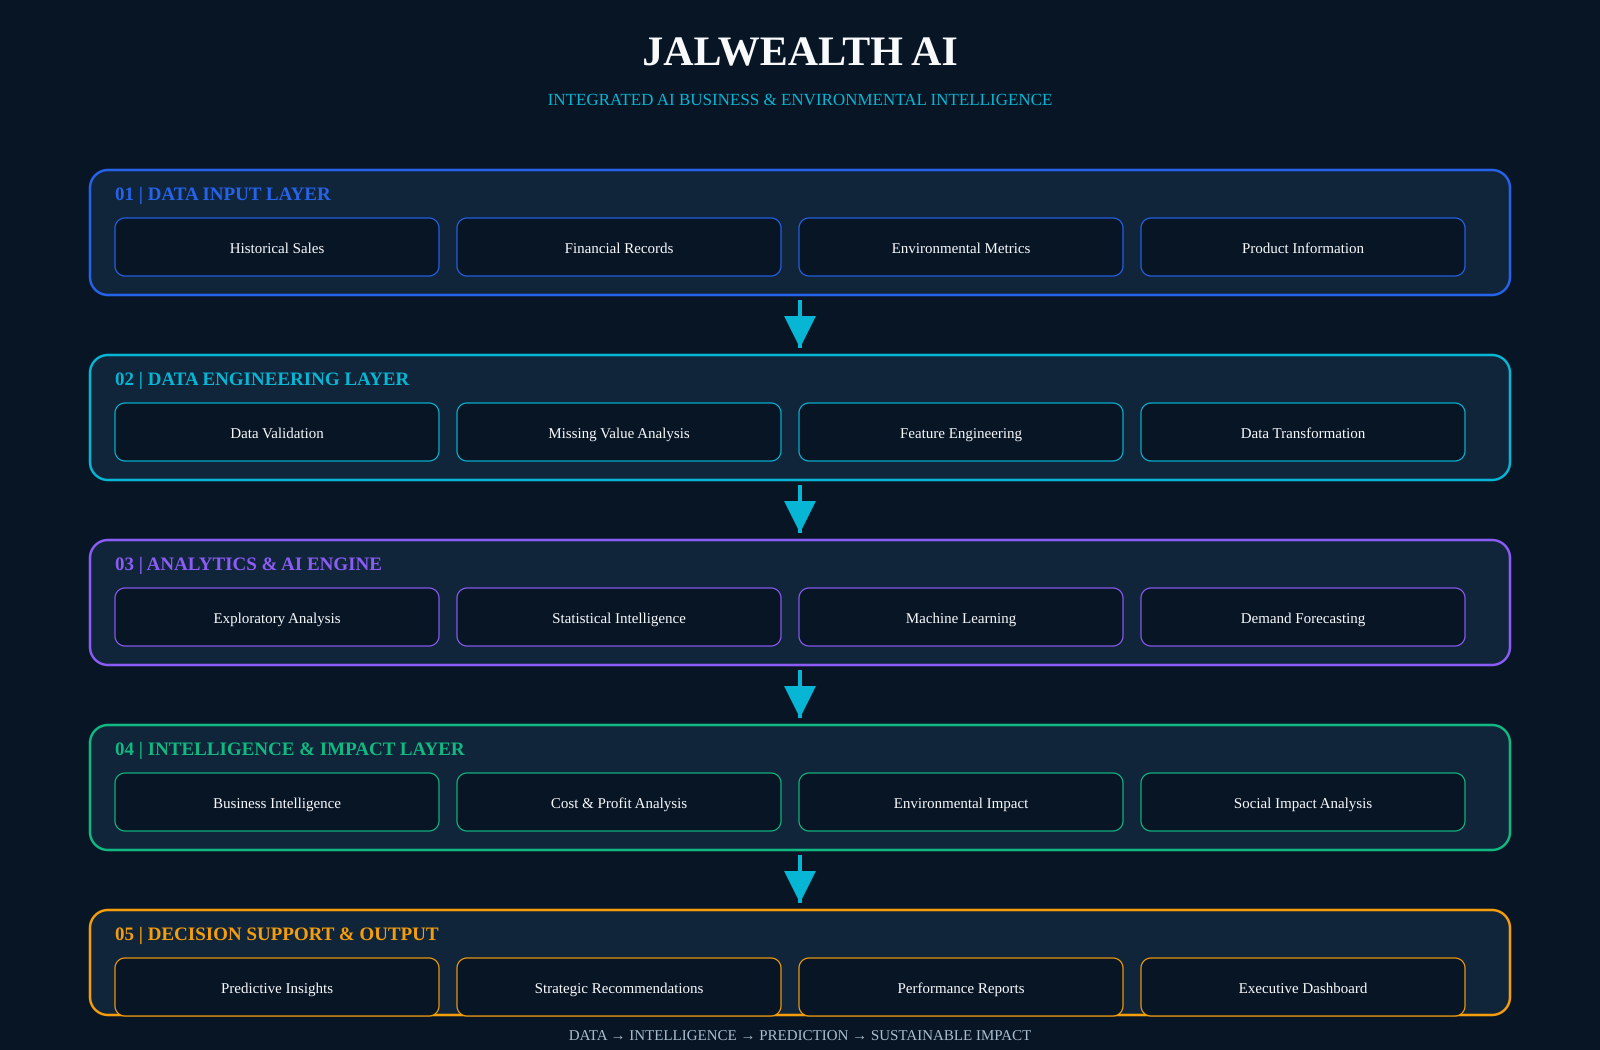

Architecture successfully generated!
SVG Location: C:\Users\User\JALWEALTH_AI_Outputs\Architecture\JALWEALTH_AI_System_Architecture.svg


In [6]:
import svgwrite 
from IPython.display import SVG, display 
 
svg_path = ARCHITECTURE_DIR / "JALWEALTH_AI_System_Architecture.svg" 
 
# Canvas 
WIDTH = 1600 
HEIGHT = 1050 
 
dwg = svgwrite.Drawing( 
    str(svg_path), 
    size=(f"{WIDTH}px", f"{HEIGHT}px"), 
    viewBox=f"0 0 {WIDTH} {HEIGHT}" 
) 
 
# Professional color palette 
COLORS = { 
    "background": "#081525", 
    "panel": "#10243A", 
    "blue": "#2563EB", 
    "cyan": "#06B6D4", 
    "green": "#10B981", 
    "purple": "#8B5CF6", 
    "orange": "#F59E0B", 
    "white": "#F8FAFC", 
    "muted": "#A9BED0", 
    "line": "#54738F" 
} 
 
# Background 
dwg.add( 
    dwg.rect( 
        insert=(0, 0), 
        size=(WIDTH, HEIGHT), 
        fill=COLORS["background"] 
    ) 
) 
 
# Main heading 
dwg.add( 
    dwg.text( 
        "JALWEALTH AI", 
        insert=(WIDTH / 2, 65), 
        text_anchor="middle", 
        font_size="42px", 
        font_weight="bold", 
        fill=COLORS["white"] 
    ) 
) 
 
dwg.add( 
    dwg.text( 
        "INTEGRATED AI BUSINESS & ENVIRONMENTAL INTELLIGENCE", 
        insert=(WIDTH / 2, 105), 
        text_anchor="middle", 
        font_size="17px", 
        fill=COLORS["cyan"] 
    ) 
) 
 
# Architecture modules 
modules = [ 
    { 
        "x": 90, "y": 170, "w": 1420, "h": 125, 
        "title": "01 | DATA INPUT LAYER", 
        "items": [ 
            "Historical Sales", 
            "Financial Records", 
            "Environmental Metrics", 
            "Product Information" 
        ], 
        "color": COLORS["blue"] 
    }, 
    { 
        "x": 90, "y": 355, "w": 1420, "h": 125, 
        "title": "02 | DATA ENGINEERING LAYER", 
        "items": [ 
            "Data Validation", 
            "Missing Value Analysis", 
            "Feature Engineering", 
            "Data Transformation" 
        ], 
        "color": COLORS["cyan"] 
    }, 
    { 
        "x": 90, "y": 540, "w": 1420, "h": 125, 
        "title": "03 | ANALYTICS & AI ENGINE", 
        "items": [ 
            "Exploratory Analysis", 
            "Statistical Intelligence", 
            "Machine Learning", 
            "Demand Forecasting" 
        ], 
        "color": COLORS["purple"] 
    }, 
    { 
        "x": 90, "y": 725, "w": 1420, "h": 125, 
        "title": "04 | INTELLIGENCE & IMPACT LAYER", 
        "items": [ 
            "Business Intelligence", 
            "Cost & Profit Analysis", 
            "Environmental Impact", 
            "Social Impact Analysis" 
        ], 
        "color": COLORS["green"] 
    }, 
    { 
        "x": 90, "y": 910, "w": 1420, "h": 105, 
        "title": "05 | DECISION SUPPORT & OUTPUT", 
        "items": [ 
            "Predictive Insights", 
            "Strategic Recommendations", 
            "Performance Reports", 
            "Executive Dashboard" 
        ], 
        "color": COLORS["orange"] 
    } 
] 
 
# Draw modules 
for module in modules: 
 
    x, y = module["x"], module["y"] 
    w, h = module["w"], module["h"] 
    color = module["color"] 
 
    # Outer module 
    dwg.add( 
        dwg.rect( 
            insert=(x, y), 
            size=(w, h), 
            rx=18, 
            ry=18, 
            fill=COLORS["panel"], 
            stroke=color, 
            stroke_width=2.5 
        ) 
    ) 
 
    # Module heading 
    dwg.add( 
        dwg.text( 
            module["title"], 
            insert=(x + 25, y + 30), 
            font_size="19px", 
            font_weight="bold", 
            fill=color 
        ) 
    ) 
 
    # Four submodules 
    gap = 18 
    box_width = (w - 70 - (3 * gap)) / 4 
 
    for i, item in enumerate(module["items"]): 
 
        bx = x + 25 + i * (box_width + gap) 
        by = y + 48 
 
        dwg.add( 
            dwg.rect( 
                insert=(bx, by), 
                size=(box_width, 58), 
                rx=10, 
                ry=10, 
                fill=COLORS["background"], 
                stroke=color, 
                stroke_width=1.2 
            ) 
        ) 
 
        dwg.add( 
            dwg.text( 
                item, 
                insert=(bx + box_width / 2, by + 35), 
                text_anchor="middle", 
                font_size="15px", 
                fill=COLORS["white"] 
            ) 
        ) 
 

marker_end=dwg.marker( 
                insert=(8, 4), 
                size=(10, 8), 
                orient="auto")
marker_end.add(
    dwg.path(
        d="M0,0 L8,4 L0,8 Z", 
        fill=COLORS["cyan"])) 

dwg.defs.add(marker_end)

# Connecting arrows 
for y in [300, 485, 670, 855]: 
 
    dwg.add( 
        dwg.line( 
            start=(800, y), 
            end=(800, y + 48), 
            stroke=COLORS["cyan"], 
            stroke_width=4, 
            marker_end=marker_end.get_funciri()
        )
    )

                     
# Footer 
dwg.add( 
    dwg.text( 
        "DATA  →  INTELLIGENCE  →  PREDICTION  →  SUSTAINABLE IMPACT", 
insert=(WIDTH / 2, 1040), 
text_anchor="middle", 
font_size="15px", 
fill=COLORS["muted"] 
) 
) 
# Save SVG 
dwg.save() 
# Display architecture in notebook 
display(SVG(filename=str(svg_path))) 
print("Architecture successfully generated!") 
print("SVG Location:", svg_path) 

# DATA QUALITY AUDIT & DATA INTELLIGENCE 

## 1. Objective 
Before developing predictive models, it is essential to understand the structure, reliability, 
consistency, and completeness of the available data. 
JALWEALTH AI performs a systematic data quality assessment across all available workbook 
sheets. 
    
## 2. Audit Dimensions
- Structural Integrity: Rows, columns, and data types.
- Completeness: Missing and null values.
- Uniqueness: Duplicate records and duplicate identifiers.
- Consistency: Data types and category variations.
- Validity: Invalid numerical values and impossible observations.
- Analytical Readiness: Suitability of features for downstream analysis. 
    
## 3. Why This Matters 
Poor-quality data can lead to misleading business insights, unreliable forecasts, and incorrect 
machine learning predictions. 
 
Therefore, data validation is treated as a mandatory stage before feature engineering and 
model development. 
 
## 4. Expected Outcome 
 
A consolidated data quality report identifying potential problems, their severity, and the 
recommended treatment strategy. 

In [7]:
 # LOAD ALL WORKBOOK SHEETS 

In [8]:
workbook_data = {} 
 
for sheet_name in excel_file.sheet_names: 
 
    df = pd.read_excel( 
        FILE_PATH, 
        sheet_name=sheet_name 
    ) 
 
    workbook_data[sheet_name] = df.copy() 
 
print("=" * 75) 
print("JALWEALTH AI | COMPLETE WORKBOOK DATA INVENTORY") 
print("=" * 75) 
 
for sheet_name, df in workbook_data.items(): 
 
    print(f"\nSHEET: {sheet_name}") 
    print("-" * 60) 
 
    print(f"Rows       : {df.shape[0]:,}") 
    print(f"Columns    : {df.shape[1]:,}") 
    print(f"Memory     : {df.memory_usage(deep=True).sum() / 1024:.2f} KB") 
 
    print("\nColumn Names:") 
    print(df.columns.tolist()) 
 
    print("\nData Types:") 
    print(df.dtypes.astype(str).to_dict()) 
 
print("\nWorkbook inventory completed.") 

JALWEALTH AI | COMPLETE WORKBOOK DATA INVENTORY

SHEET: Executive Dashboard
------------------------------------------------------------
Rows       : 62
Columns    : 13
Memory     : 31.48 KB

Column Names:
['JALWEALTH AI — INTEGRATED BUSINESS, COST, ENVIRONMENTAL & PREDICTIVE ANALYTICS', 'Unnamed: 1', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4', 'Unnamed: 5', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8', 'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12']

Data Types:
{'JALWEALTH AI — INTEGRATED BUSINESS, COST, ENVIRONMENTAL & PREDICTIVE ANALYTICS': 'object', 'Unnamed: 1': 'object', 'Unnamed: 2': 'object', 'Unnamed: 3': 'object', 'Unnamed: 4': 'object', 'Unnamed: 5': 'object', 'Unnamed: 6': 'object', 'Unnamed: 7': 'object', 'Unnamed: 8': 'object', 'Unnamed: 9': 'object', 'Unnamed: 10': 'object', 'Unnamed: 11': 'object', 'Unnamed: 12': 'object'}

SHEET: JALWEALTH Sales Data
------------------------------------------------------------
Rows       : 9,976
Columns    : 32
Memory     : 9113.

 # AUTOMATED DATA QUALITY ASSESSMENT ENGINE 

In [9]:
quality_results = [] 
 
for sheet_name, df in workbook_data.items(): 
 
    total_cells = df.size 
 
    missing_cells = df.isna().sum().sum() 
 
    duplicate_rows = df.duplicated().sum() 
 
    duplicate_columns = df.columns.duplicated().sum() 
 
    missing_percentage = ( 
        (missing_cells / total_cells) * 100 
        if total_cells > 0 else 0 
    ) 
 
    memory_mb = ( 
        df.memory_usage(deep=True).sum() / (1024 ** 2) 
    ) 
 
    quality_results.append({ 
 
        "Sheet": sheet_name, 
        "Rows": len(df), 
        "Columns": len(df.columns), 
        "Total_Cells": total_cells, 
        "Missing_Cells": missing_cells, 
        "Missing_%": round(missing_percentage, 2), 
        "Duplicate_Rows": duplicate_rows, 
        "Duplicate_Columns": duplicate_columns, 
        "Memory_MB": round(memory_mb, 3) 
 
    }) 
 
quality_report = pd.DataFrame(quality_results) 
 
print("=" * 80) 
print("JALWEALTH AI | DATA QUALITY AUDIT REPORT") 
print("=" * 80) 
 
display( 
    quality_report.style 
    .background_gradient( 
        subset=["Missing_%", "Duplicate_Rows"], 
        cmap="YlOrRd" 
    ) 
    .format({ 
        "Missing_%": "{:.2f}%", 
        "Memory_MB": "{:.3f}" 
    }) 
) 
 
print("\nAUDIT SUMMARY") 
 
print( 
    "Total Records:", 
    quality_report["Rows"].sum() 
) 
 
print( 
    "Total Missing Cells:", 
    quality_report["Missing_Cells"].sum() 
) 
 
print( 
    "Total Duplicate Rows:", 
    quality_report["Duplicate_Rows"].sum() 
) 
 
print("\nData quality assessment completed.") 

JALWEALTH AI | DATA QUALITY AUDIT REPORT


,Sheet,Rows,Columns,Total_Cells,Missing_Cells,Missing_%,Duplicate_Rows,Duplicate_Columns,Memory_MB
0,Executive Dashboard,62,13,806,365,45.29%,3,0,0.031
1,JALWEALTH Sales Data,9976,32,319232,49880,15.62%,0,0,8.984
2,Cost & Break-Even Analysis,22,16,352,46,13.07%,0,0,0.013
3,Environmental Impact,29,10,290,28,9.66%,0,0,0.011
4,Predictive Forecast 2026,184,9,1656,25,1.51%,0,0,0.075
5,Product Guide,15,5,75,0,0.00%,0,0,0.005



AUDIT SUMMARY
Total Records: 10288
Total Missing Cells: 50344
Total Duplicate Rows: 3

Data quality assessment completed.


# MISSING VALUE INTELLIGENCE 


SHEET: Executive Dashboard
-----------------------------------------------------------------


,Missing_Count,Missing_Percentage,Data_Type
Unnamed: 7,46,74.19,object
Unnamed: 9,46,74.19,object
Unnamed: 11,46,74.19,object
Unnamed: 6,45,72.58,object
Unnamed: 10,45,72.58,object
Unnamed: 12,45,72.58,object
Unnamed: 8,45,72.58,object
Unnamed: 1,9,14.52,object
Unnamed: 3,9,14.52,object
Unnamed: 5,9,14.52,object



SHEET: JALWEALTH Sales Data
-----------------------------------------------------------------


,Missing_Count,Missing_Percentage,Data_Type
Total Cost (INR),9976,100.0,float64
Variable Cost (INR),9976,100.0,float64
Contribution Margin (INR),9976,100.0,float64
Contribution Margin (%),9976,100.0,float64
Break-Even Sales (INR),9976,100.0,float64



SHEET: Cost & Break-Even Analysis
-----------------------------------------------------------------


,Missing_Count,Missing_Percentage,Data_Type
Unnamed: 1,3,13.64,object
Unnamed: 2,3,13.64,object
Unnamed: 3,3,13.64,object
Unnamed: 4,3,13.64,object
Unnamed: 6,3,13.64,object
Unnamed: 5,3,13.64,object
Unnamed: 7,3,13.64,object
Unnamed: 8,3,13.64,object
Unnamed: 12,3,13.64,object
Unnamed: 9,3,13.64,object



SHEET: Environmental Impact
-----------------------------------------------------------------


,Missing_Count,Missing_Percentage,Data_Type
Unnamed: 1,3,10.34,object
Unnamed: 2,3,10.34,object
Unnamed: 6,3,10.34,object
Unnamed: 3,3,10.34,object
Unnamed: 4,3,10.34,object
Unnamed: 5,3,10.34,object
Unnamed: 8,3,10.34,object
Unnamed: 7,3,10.34,object
Unnamed: 9,3,10.34,object
ENVIRONMENTAL & SOCIAL IMPACT TRACKER (WATER HYACINTH REMOVAL & ARTISAN LIVELIHOODS),1,3.45,object



SHEET: Predictive Forecast 2026
-----------------------------------------------------------------


,Missing_Count,Missing_Percentage,Data_Type
Unnamed: 1,3,1.63,object
Unnamed: 5,3,1.63,object
Unnamed: 2,3,1.63,object
Unnamed: 3,3,1.63,object
Unnamed: 4,3,1.63,object
Unnamed: 7,3,1.63,object
Unnamed: 6,3,1.63,object
Unnamed: 8,3,1.63,object
PREDICTIVE ANALYTICS — 2026 MONTHLY PRODUCT DEMAND & SALES FORECAST,1,0.54,object



SHEET: Product Guide
-----------------------------------------------------------------
No missing values detected.


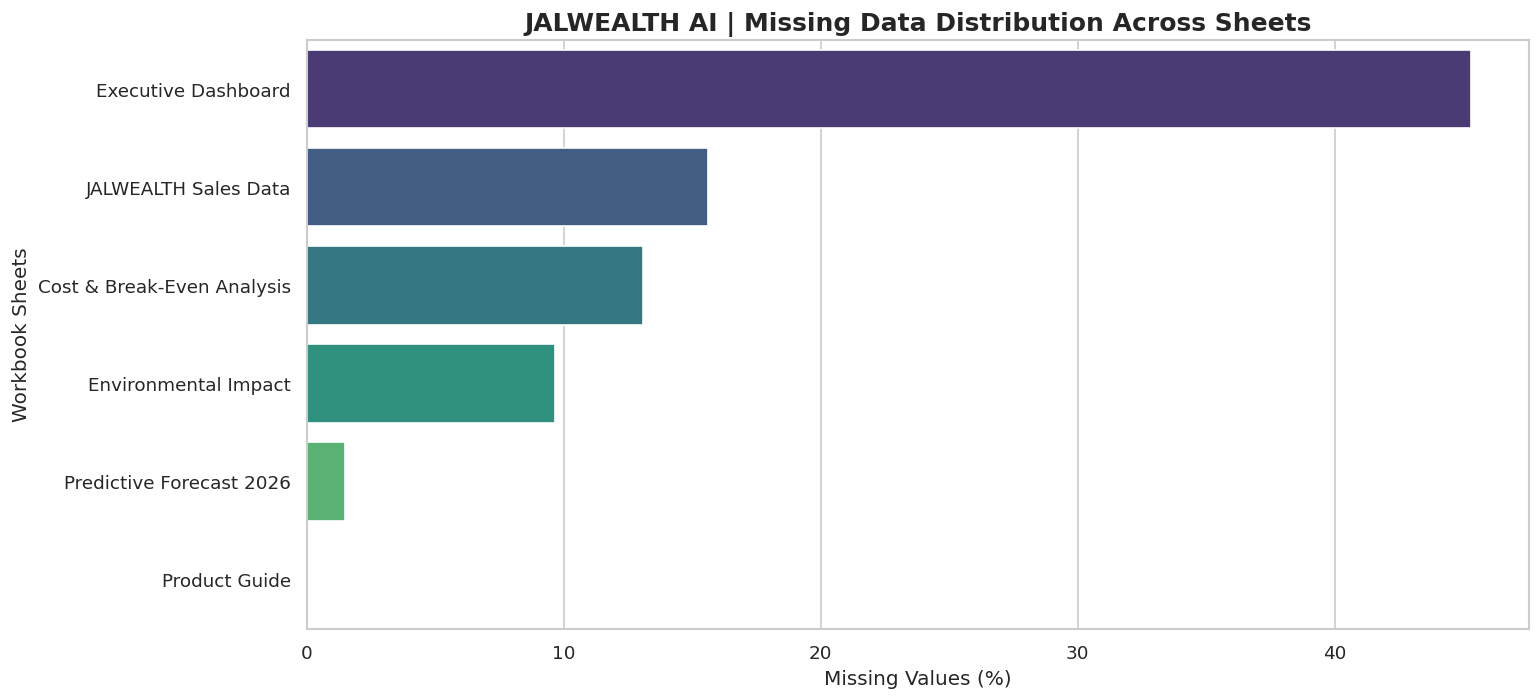

In [10]:
missing_reports = {} 
 
for sheet_name, df in workbook_data.items(): 
 
    missing_count = df.isnull().sum() 
 
    missing_percentage = ( 
        (missing_count / len(df)) * 100 
        if len(df) > 0 
        else missing_count * 0 
    ) 
 
    report = pd.DataFrame({ 
 
        "Missing_Count": missing_count, 
        "Missing_Percentage": missing_percentage.round(2), 
        "Data_Type": df.dtypes.astype(str) 
 
    }) 
 
    report = report[ 
        report["Missing_Count"] > 0 
    ].sort_values( 
        by="Missing_Percentage", 
        ascending=False 
    ) 
 
    missing_reports[sheet_name] = report 
 
    print(f"\nSHEET: {sheet_name}") 
    print("-" * 65) 
 
    if report.empty: 
        print("No missing values detected.") 
    else: 
        display(report) 
 
# Overall missing value visualization 
missing_summary = quality_report[ 
    ["Sheet", "Missing_%"] 
].copy() 
 
plt.figure(figsize=(13, 6)) 
 
sns.barplot( 
    data=missing_summary, 
    x="Missing_%", 
    y="Sheet", 
    hue="Sheet", 
    palette="viridis", 
    legend=False 
) 
 
plt.title( 
    "JALWEALTH AI | Missing Data Distribution Across Sheets", 
    fontsize=15, 
    fontweight="bold" 
) 
 
plt.xlabel("Missing Values (%)") 
plt.ylabel("Workbook Sheets") 
plt.tight_layout() 
 
plt.savefig( 
    CHART_DIR / "missing_data_distribution.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show()

# DUPLICATE & UNIQUENESS ANALYSIS 

In [11]:
duplicate_analysis = [] 
 
for sheet_name, df in workbook_data.items(): 
 
    duplicate_count = df.duplicated().sum() 
 
    unique_rows = len(df) - duplicate_count 
 
    duplicate_percentage = ( 
        duplicate_count / len(df) * 100 
        if len(df) > 0 else 0 
    ) 
 
    duplicate_analysis.append({ 
 
        "Sheet": sheet_name, 
        "Total_Rows": len(df), 
        "Unique_Rows": unique_rows, 
        "Duplicate_Rows": duplicate_count, 
        "Duplicate_Percentage": round( 
            duplicate_percentage, 2 
        ) 
 
    }) 
 
duplicate_report = pd.DataFrame( 
    duplicate_analysis 
) 
 
print("DUPLICATE RECORD ANALYSIS") 
 
display( 
    duplicate_report.style.background_gradient( 
        subset=["Duplicate_Percentage"], 
        cmap="Oranges" 
    ) 
) 
 
# Detailed duplicate inspection for sales data 
sales_duplicates = sales_df[ 
    sales_df.duplicated(keep=False) 
].sort_values( 
    by=list(sales_df.columns) 
) 
 
print("\nSALES DATA DUPLICATE RECORDS") 
 
if sales_duplicates.empty: 
    print("No exact duplicate records found.") 
else: 
    display(sales_duplicates.head(10)) 
 
print("\nImportant:") 
print( 
    "Duplicate records are flagged for investigation. " 
    "They will not be deleted automatically." 
) 
 

DUPLICATE RECORD ANALYSIS


,Sheet,Total_Rows,Unique_Rows,Duplicate_Rows,Duplicate_Percentage
0,Executive Dashboard,62,59,3,4.840000
1,JALWEALTH Sales Data,9976,9976,0,0.000000
2,Cost & Break-Even Analysis,22,22,0,0.000000
3,Environmental Impact,29,29,0,0.000000
4,Predictive Forecast 2026,184,184,0,0.000000
5,Product Guide,15,15,0,0.000000



SALES DATA DUPLICATE RECORDS
No exact duplicate records found.

Important:
Duplicate records are flagged for investigation. They will not be deleted automatically.


# DATA TYPE & NUMERICAL VALIDITY AUDIT

In [12]:
dtype_results = [] 
 
for sheet_name, df in workbook_data.items(): 
 
    for column in df.columns: 
 
        series = df[column] 
 
        dtype_results.append({ 
 
            "Sheet": sheet_name, 
            "Column": column, 
            "Data_Type": str(series.dtype), 
            "Unique_Values": series.nunique(dropna=True), 
            "Null_Values": series.isna().sum(), 
            "Numeric_Column": pd.api.types.is_numeric_dtype(series) 
 
        }) 
 
dtype_report = pd.DataFrame(dtype_results) 
 
print("COMPLETE COLUMN-LEVEL DATA PROFILE") 
 
display(dtype_report) 
 
# Identify numeric columns with negative observations 
negative_value_report = [] 
 
for sheet_name, df in workbook_data.items(): 
 
    numeric_columns = df.select_dtypes( 
        include=np.number 
    ).columns 
 
    for column in numeric_columns: 
 
        negative_count = (df[column] < 0).sum() 
 
        if negative_count > 0: 
 
            negative_value_report.append({ 
 
                "Sheet": sheet_name, 
                "Column": column, 
                "Negative_Values": negative_count 
 
            }) 
 
negative_report = pd.DataFrame( 
    negative_value_report, 
    columns=["Sheet", "Column", "Negative_Values"] 
) 
 
print("\nNEGATIVE NUMERICAL VALUE AUDIT") 
 
if negative_report.empty: 
    print("No negative numerical values detected.") 
else: 
    display(negative_report) 
 
print( 
    "\nNote: Negative values are flagged, not automatically " 
    "treated as errors. Their validity depends on the business meaning." 
)

COMPLETE COLUMN-LEVEL DATA PROFILE


,Sheet,Column,Data_Type,Unique_Values,Null_Values,Numeric_Column
0,Executive Dashboard,"JALWEALTH AI — INTEGRATED BUSINESS, COST, ENVI...",object,46,4,False
1,Executive Dashboard,Unnamed: 1,object,19,9,False
2,Executive Dashboard,Unnamed: 2,object,54,8,False
3,Executive Dashboard,Unnamed: 3,object,53,9,False
4,Executive Dashboard,Unnamed: 4,object,53,8,False
...,...,...,...,...,...,...
80,Product Guide,Product Category,object,3,0,False
81,Product Guide,Water-Hyacinth Product,object,15,0,False
82,Product Guide,Indicative Min Price (INR),int64,10,0,True
83,Product Guide,Indicative Max Price (INR),int64,13,0,True



NEGATIVE NUMERICAL VALUE AUDIT
No negative numerical values detected.

Note: Negative values are flagged, not automatically treated as errors. Their validity depends on the business meaning.


# DATA QUALITY EXECUTIVE INSIGHTS 

In [13]:
total_records = quality_report["Rows"].sum() 
 
total_missing = quality_report["Missing_Cells"].sum() 
 
total_duplicates = quality_report["Duplicate_Rows"].sum() 
 
total_cells = quality_report["Total_Cells"].sum() 
 
overall_missing_rate = ( 
    total_missing / total_cells * 100 
    if total_cells > 0 else 0 
) 
 
overall_duplicate_rate = ( 
    total_duplicates / total_records * 100 
    if total_records > 0 else 0 
) 
 
print("=" * 75) 
print("JALWEALTH AI | EXECUTIVE DATA QUALITY INSIGHTS") 
print("=" * 75) 
 
print(f"\n1. Total Records          : {total_records:,}") 
print(f"2. Total Missing Cells    : {total_missing:,}") 
print(f"3. Overall Missing Rate   : {overall_missing_rate:.2f}%") 
print(f"4. Duplicate Records      : {total_duplicates:,}") 
print(f"5. Duplicate Rate         : {overall_duplicate_rate:.2f}%") 
 
print("\nDATA QUALITY OBSERVATIONS") 
print("-" * 65) 
 
if overall_missing_rate == 0: 
    print("✓ No missing cells detected across the workbook.") 
elif overall_missing_rate <= 5: 
    print("! Low overall missing-data rate detected.") 
else: 
    print("! Significant missing-data rate requires investigation.") 
 
if total_duplicates == 0: 
    print("✓ No exact duplicate rows detected.") 
else: 
    print("! Duplicate rows detected and flagged for review.") 
 
sheets_with_missing = quality_report[ 
    quality_report["Missing_Cells"] > 0 
]["Sheet"].tolist() 
 
if sheets_with_missing: 
    print("\nSheets requiring missing-value investigation:") 
    for sheet in sheets_with_missing: 
        print(" -", sheet) 
 
print("\nRECOMMENDED NEXT ACTIONS") 
print("-" * 65) 
 
print("1. Investigate missing values and their business meaning.") 
print("2. Validate numerical ranges and categorical consistency.") 
print("3. Review potential duplicate transactions.") 
print("4. Preserve original data before applying transformations.") 
print("5. Prepare validated datasets for exploratory analysis.") 
print("\n" + "=" * 75) 
print("DATA QUALITY AUDIT COMPLETED") 
print("=" * 75) 

JALWEALTH AI | EXECUTIVE DATA QUALITY INSIGHTS

1. Total Records          : 10,288
2. Total Missing Cells    : 50,344
3. Overall Missing Rate   : 15.61%
4. Duplicate Records      : 3
5. Duplicate Rate         : 0.03%

DATA QUALITY OBSERVATIONS
-----------------------------------------------------------------
! Significant missing-data rate requires investigation.
! Duplicate rows detected and flagged for review.

Sheets requiring missing-value investigation:
 - Executive Dashboard
 - JALWEALTH Sales Data
 - Cost & Break-Even Analysis
 - Environmental Impact
 - Predictive Forecast 2026

RECOMMENDED NEXT ACTIONS
-----------------------------------------------------------------
1. Investigate missing values and their business meaning.
2. Validate numerical ranges and categorical consistency.
3. Review potential duplicate transactions.
4. Preserve original data before applying transformations.
5. Prepare validated datasets for exploratory analysis.

DATA QUALITY AUDIT COMPLETED


 # EXPLORATORY DATA ANALYSIS (EDA) 

## 1. Introduction 
Exploratory Data Analysis is the process of examining historical data to discover patterns, 
relationships, distributions, and business opportunities. 
In JALWEALTH AI, EDA connects business performance with environmental sustainability. 

## 2. Business Questions 
### Revenue Intelligence
- How does revenue change over time? 
- Which products generate the highest revenue?
- Which customer segments contribute most to sales? 

### Financial Intelligence
- Which product categories generate higher profits? 
- What is the distribution of operating costs? 
- How does profit vary across geographical regions? 

### Environmental Intelligence
- How much water hyacinth biomass is collected? 
- How much waste is diverted?
- What is the relationship between production and environmental impact? 

## 3. Analytical Approach 
We will use: 
- Descriptive Statistics
- Time-Series Analysis
- Grouped Business Analysis 
- Distribution Analysis
- Correlation Analysis
- Comparative Visualization 
 
## 4. Expected Outcome 
 
Convert 2024–2025 historical transaction records into measurable business and environmental 
insights. 
 
**Analytical Principle:** Every conclusion must be supported by observed data and clearly 
distinguished from assumptions or forecasts. 

In [14]:
# ANALYTICAL DATA PREPARATION 

In [15]:
eda_df = workbook_data["JALWEALTH Sales Data"].copy() 
 
# Convert date columns 
eda_df["Order Date"] = pd.to_datetime( 
    eda_df["Order Date"], 
    errors="coerce" 
) 
 
# Convert numerical fields 
numeric_columns = [ 
    "Revenue (INR)", 
    "Units Sold", 
    "Profit (INR)", 
    "Discount Rate", 
    "Raw Material Cost (INR)", 
    "Labour Cost (INR)", 
    "Processing Cost (INR)", 
    "Packaging Cost (INR)", 
    "Transportation Cost (INR)", 
    "Marketing Cost (INR)", 
    "Water hyacinth collected (kg)", 
    "Water hyacinth processed (kg)", 
    "Waste diverted (kg)", 
    "Finished products manufactured", 
    "Artisan employment days" 
] 
 
for column in numeric_columns: 
    eda_df[column] = pd.to_numeric( 
        eda_df[column], 
        errors="coerce" 
    ) 
 
# Time-based analytical features 
eda_df["Year"] = eda_df["Order Date"].dt.year 
 
eda_df["Month"] = eda_df["Order Date"].dt.month 
 
eda_df["Month_Name"] = eda_df["Order Date"].dt.month_name() 
 
eda_df["Quarter"] = ( 
    "Q" + eda_df["Order Date"].dt.quarter.astype("Int64").astype(str) 
) 
 
eda_df["Year_Month"] = ( 
    eda_df["Order Date"].dt.to_period("M").astype(str) 
) 
 
# Reconstruct total cost from six available cost components. 
cost_components = [ 
    "Raw Material Cost (INR)", 
    "Labour Cost (INR)", 
    "Processing Cost (INR)", 
    "Packaging Cost (INR)", 
    "Transportation Cost (INR)", 
    "Marketing Cost (INR)" 
] 
 
eda_df["Reconstructed Total Cost (INR)"] = ( 
    eda_df[cost_components].sum( 
        axis=1, 
        min_count=len(cost_components) 
    ) 
) 
 
# Reconcile reconstructed cost against revenue and profit 
eda_df["Cost Reconciliation Difference (INR)"] = ( 
    eda_df["Revenue (INR)"] 
    - eda_df["Profit (INR)"] 
    - eda_df["Reconstructed Total Cost (INR)"] 
) 
 
# Profit margin calculated from available fields 
eda_df["Profit Margin (%)"] = np.where( 
    eda_df["Revenue (INR)"] > 0, 
    eda_df["Profit (INR)"] / 
    eda_df["Revenue (INR)"] * 100, 
    np.nan 
) 
 
print("=" * 70) 
print("JALWEALTH AI | ANALYTICAL DATASET PREPARATION") 
print("=" * 70) 
 
print("Historical Records:", len(eda_df)) 
print("Date Range:", eda_df["Order Date"].min(), 
      "to", eda_df["Order Date"].max()) 
 
print("Total Analytical Features:", len(eda_df.columns)) 
 
print("\nCost Reconciliation:") 
print( 
    "Maximum absolute difference:", 
    eda_df["Cost Reconciliation Difference (INR)"] 
    .abs().max() 
) 
 
display(eda_df.head()) 
 
print("\nAnalytical dataset is ready.")

JALWEALTH AI | ANALYTICAL DATASET PREPARATION
Historical Records: 9976
Date Range: 2024-01-01 00:00:00 to 2025-12-31 00:00:00
Total Analytical Features: 40

Cost Reconciliation:
Maximum absolute difference: 2.9103830456733704e-11


,Order ID,Order Date,Year-Month,Delivery Method,Customer Segment,Country,City / District,Indian State,Sample PIN Code,Indian Region,...,Finished products manufactured,Artisan employment days,Year,Month,Month_Name,Quarter,Year_Month,Reconstructed Total Cost (INR),Cost Reconciliation Difference (INR),Profit Margin (%)
0,JW-2024-00001,2024-01-01,2024-01,Standard Delivery,Corporate Buyers,India,Chennai,Tamil Nadu,809570,South,...,8,3.15,2024,1,January,Q1,2024-01,3253.52,4.547474e-13,28.202457
1,JW-2024-00002,2024-01-01,2024-01,Express Delivery,Online Marketplaces,India,Imphal,Manipur,688508,Northeast,...,7,8.38,2024,1,January,Q1,2024-01,6480.41,-9.094947e-13,25.244440
2,JW-2024-00003,2024-01-01,2024-01,Local Pickup,Wholesalers,India,Thanjavur,Tamil Nadu,267414,South,...,19,3.82,2024,1,January,Q1,2024-01,4362.52,0.000000e+00,28.693691
3,JW-2024-00004,2024-01-01,2024-01,Bulk Transport,Individual Customers,India,Shimla,Himachal Pradesh,460663,North,...,5,2.04,2024,1,January,Q1,2024-01,1403.08,0.000000e+00,14.127987
4,JW-2024-00005,2024-01-01,2024-01,Bulk Transport,Corporate Buyers,India,Gorakhpur,Uttar Pradesh,759176,North,...,14,6.53,2024,1,January,Q1,2024-01,3625.72,0.000000e+00,18.449843



Analytical dataset is ready.


In [16]:
# BUSINESS PERFORMANCE KPI DASHBOARD 

JALWEALTH AI | EXECUTIVE KPI DASHBOARD


,Business KPI,Value
0,Total Revenue,"115,366,798.46"
1,Total Profit,"26,692,927.75"
2,Total Cost,"88,673,870.71"
3,Total Orders,"9,976.00"
4,Units Sold,"128,539.00"
5,Profit Margin (%),23.14
6,Average Order Value,"11,564.43"
7,Biomass Collected (kg),"355,404.77"
8,Biomass Processed (kg),"318,127.87"
9,Waste Diverted (kg),"337,640.54"


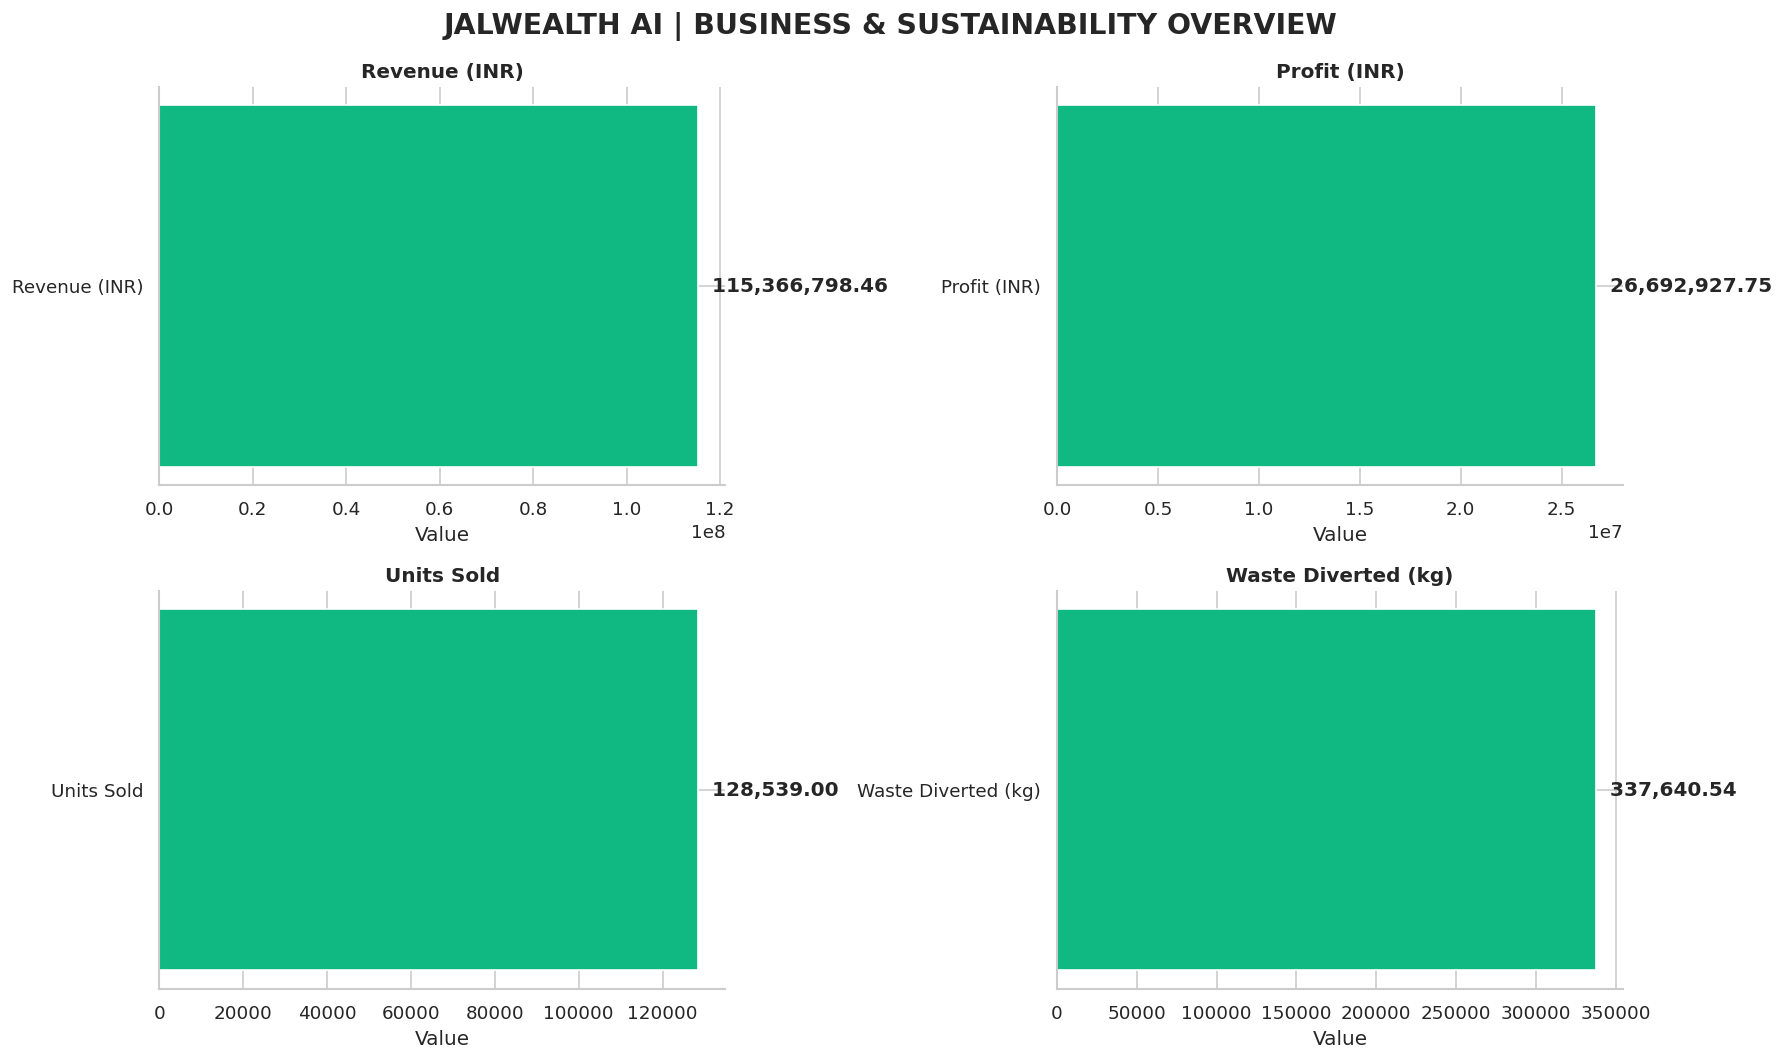

In [17]:
total_revenue = eda_df["Revenue (INR)"].sum() 
 
total_profit = eda_df["Profit (INR)"].sum() 
 
total_orders = eda_df["Order ID"].nunique() 
 
total_units = eda_df["Units Sold"].sum() 
 
total_cost = eda_df[ 
    "Reconstructed Total Cost (INR)" 
].sum() 
 
total_biomass = eda_df[ 
    "Water hyacinth collected (kg)" 
].sum() 
 
total_processed = eda_df[ 
    "Water hyacinth processed (kg)" 
].sum() 
 
total_waste_diverted = eda_df[ 
    "Waste diverted (kg)" 
].sum() 
 
total_artisan_days = eda_df[ 
    "Artisan employment days" 
].sum() 
 
overall_profit_margin = ( 
    total_profit / total_revenue * 100 
    if total_revenue else np.nan 
) 
 
average_order_value = ( 
    total_revenue / total_orders 
    if total_orders else np.nan 
) 
 
kpi_data = { 
    "Total Revenue": total_revenue, 
    "Total Profit": total_profit, 
    "Total Cost": total_cost, 
    "Total Orders": total_orders, 
    "Units Sold": total_units, 
    "Profit Margin (%)": overall_profit_margin, 
    "Average Order Value": average_order_value, 
    "Biomass Collected (kg)": total_biomass, 
    "Biomass Processed (kg)": total_processed, 
    "Waste Diverted (kg)": total_waste_diverted, 
    "Artisan Employment Days": total_artisan_days 
} 
 
kpi_df = pd.DataFrame( 
    list(kpi_data.items()), 
    columns=["Business KPI", "Value"] 
) 
 
print("=" * 70) 
print("JALWEALTH AI | EXECUTIVE KPI DASHBOARD") 
print("=" * 70) 
 
display( 
    kpi_df.style 
    .format({"Value": "{:,.2f}"}) 
    .background_gradient( 
        subset=["Value"], 
        cmap="YlGn" 
    ) 
) 
 
# Visual KPI dashboard 
fig, axes = plt.subplots(2, 2, figsize=(15, 9)) 
 
kpi_charts = [ 
    ("Revenue (INR)", total_revenue, axes[0, 0]), 
    ("Profit (INR)", total_profit, axes[0, 1]), 
    ("Units Sold", total_units, axes[1, 0]), 
    ("Waste Diverted (kg)", total_waste_diverted, axes[1, 1]) 
] 
 
for title, value, ax in kpi_charts: 
 
    ax.barh( 
        [title], 
        [value], 
        color="#10B981" 
    ) 
 
    ax.set_title(title, fontweight="bold") 
    ax.set_xlabel("Value") 
 
    ax.text( 
        value, 
        0, 
        f"  {value:,.2f}", 
        va="center", 
        fontweight="bold" 
    ) 
 
    ax.spines["top"].set_visible(False) 
    ax.spines["right"].set_visible(False) 
 
plt.suptitle( 
    "JALWEALTH AI | BUSINESS & SUSTAINABILITY OVERVIEW", 
    fontsize=17, 
    fontweight="bold" 
) 
 
plt.tight_layout() 
 
plt.savefig( 
    CHART_DIR / "executive_kpi_dashboard.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show()

In [18]:
 # PRODUCT PERFORMANCE ANALYSIS 

PRODUCT PERFORMANCE INTELLIGENCE


,Product Category,Water-Hyacinth Product,Total_Revenue,Total_Profit,Total_Units,Total_Orders,Profit_Margin_%,Revenue_Contribution_%
7,Handicrafts & Décor,Water Hyacinth Handcrafted Furniture,32540535.28,7477300.06,8397,656,22.98,28.21
2,Fashion & Accessories,Water Hyacinth Saree,13778728.76,3215101.18,8857,687,23.33,11.94
11,Home & Lifestyle,Water Hyacinth Laundry Basket,8330109.18,1962929.06,8220,617,23.56,7.22
0,Fashion & Accessories,Water Hyacinth Handbag,7012693.96,1610128.53,8225,646,22.96,6.08
10,Home & Lifestyle,Water Hyacinth Lampshade,6674021.42,1565782.82,8346,641,23.46,5.79
6,Handicrafts & Décor,Water Hyacinth Gift Hamper,6451426.22,1508166.55,8982,695,23.38,5.59
12,Home & Lifestyle,Water Hyacinth Mat,6185605.31,1424418.70,8829,695,23.03,5.36
3,Fashion & Accessories,Water Hyacinth Sling Bag,5702643.76,1318413.47,9285,702,23.12,4.94
9,Handicrafts & Décor,Water Hyacinth Wall Décor,5522941.80,1272366.84,8333,673,23.04,4.79
13,Home & Lifestyle,Water Hyacinth Storage Basket,4894887.04,1130836.31,8808,703,23.10,4.24


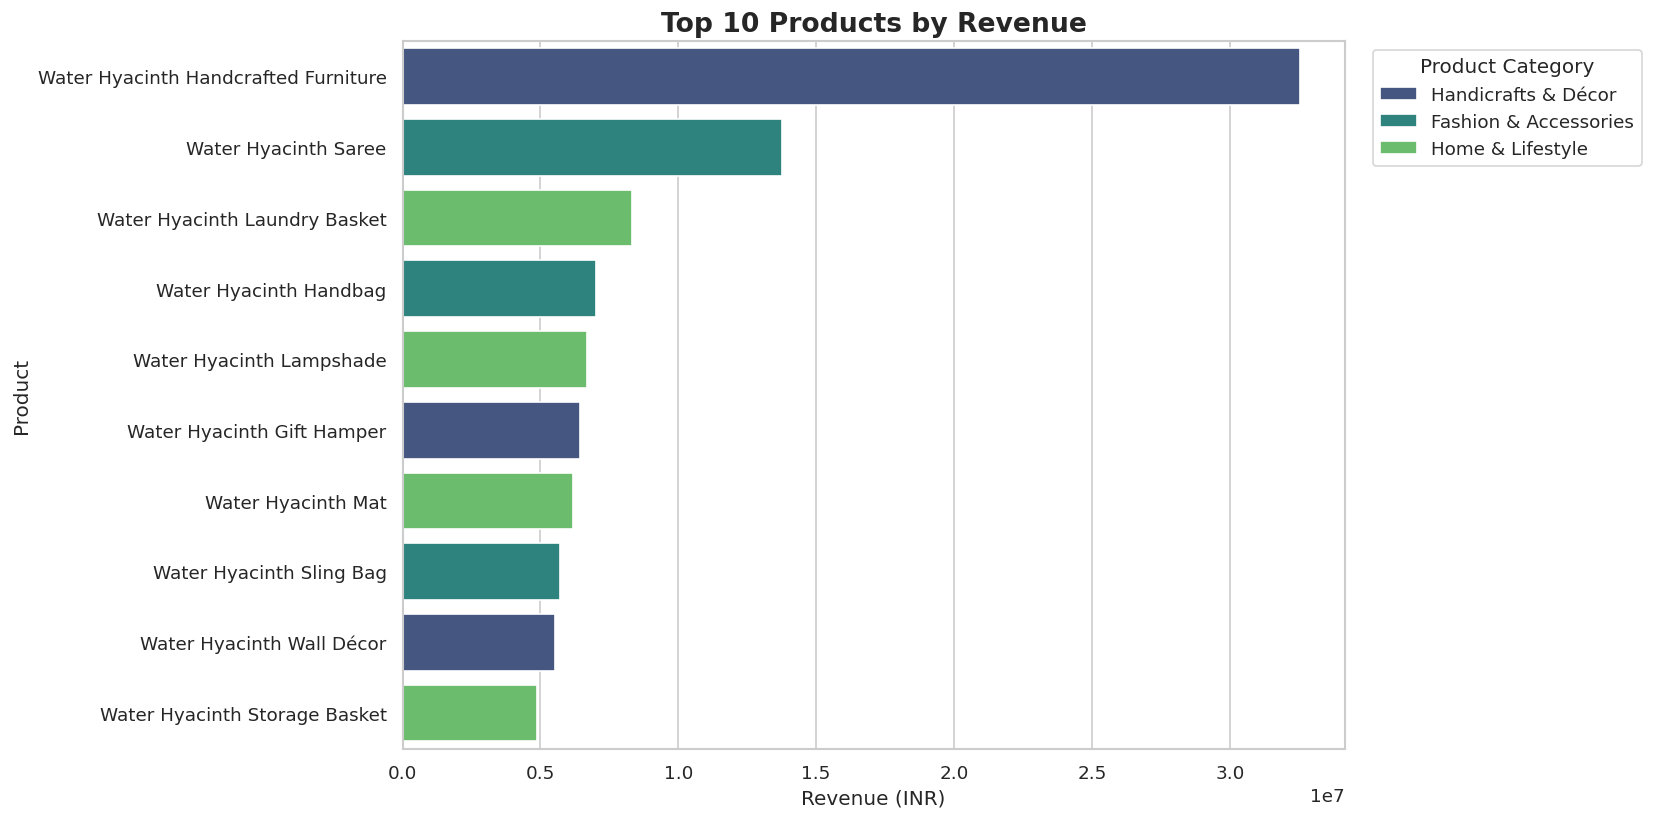

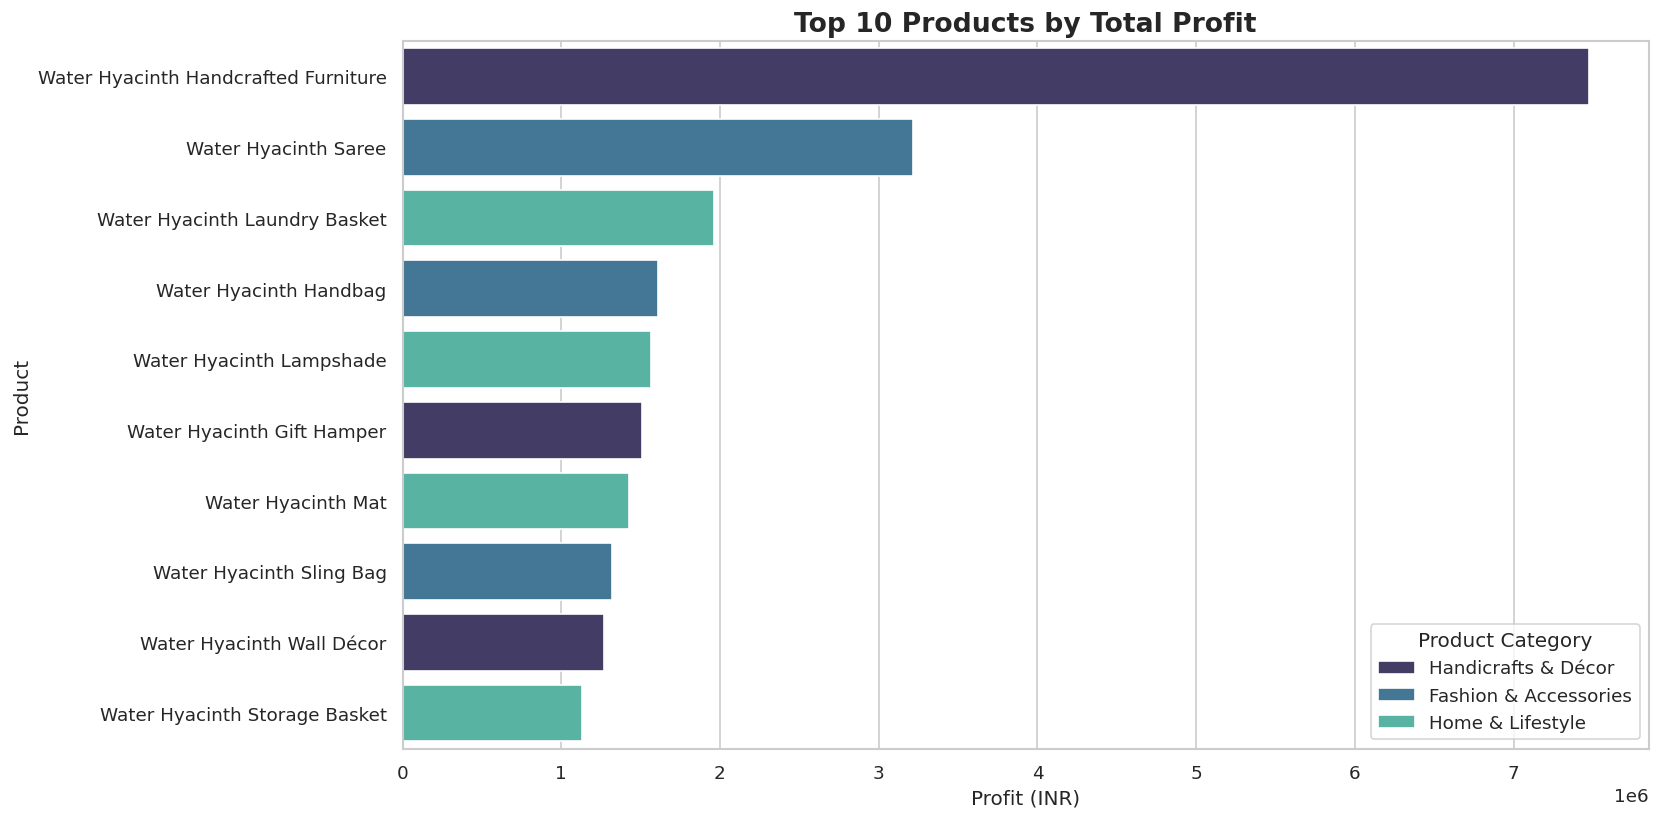


TOP REVENUE PRODUCT


,Product Category,Water-Hyacinth Product,Total_Revenue,Total_Profit,Total_Units,Total_Orders,Profit_Margin_%,Revenue_Contribution_%
7,Handicrafts & Décor,Water Hyacinth Handcrafted Furniture,32540535.28,7477300.06,8397,656,22.978418,28.206153



TOP PROFIT PRODUCT


,Product Category,Water-Hyacinth Product,Total_Revenue,Total_Profit,Total_Units,Total_Orders,Profit_Margin_%,Revenue_Contribution_%
7,Handicrafts & Décor,Water Hyacinth Handcrafted Furniture,32540535.28,7477300.06,8397,656,22.978418,28.206153


In [19]:
product_performance = ( 
eda_df.groupby( 
["Product Category", "Water-Hyacinth Product"] 
) 
.agg( 
        Total_Revenue=("Revenue (INR)", "sum"), 
        Total_Profit=("Profit (INR)", "sum"), 
        Total_Units=("Units Sold", "sum"), 
        Total_Orders=("Order ID", "nunique") 
    ) 
    .reset_index() 
) 
 
product_performance["Profit_Margin_%"] = ( 
    product_performance["Total_Profit"] / 
    product_performance["Total_Revenue"] * 100 
) 
 
product_performance["Revenue_Contribution_%"] = ( 
    product_performance["Total_Revenue"] / 
    product_performance["Total_Revenue"].sum() * 100 
) 
 
product_performance = product_performance.sort_values( 
    "Total_Revenue", 
    ascending=False 
) 
 
print("=" * 70) 
print("PRODUCT PERFORMANCE INTELLIGENCE") 
print("=" * 70) 
 
display(product_performance.round(2)) 
 
# Top 10 revenue-generating products 
top_products = product_performance.head(10) 
 
plt.figure(figsize=(14, 7)) 
 
sns.barplot( 
    data=top_products, 
    x="Total_Revenue", 
    y="Water-Hyacinth Product", 
    hue="Product Category", 
    dodge=False, 
    palette="viridis" 
) 
 
plt.title( 
    "Top 10 Products by Revenue", 
    fontsize=16, 
    fontweight="bold" 
) 
 
plt.xlabel("Revenue (INR)") 
plt.ylabel("Product") 
 
plt.legend( 
    title="Product Category", 
    bbox_to_anchor=(1.02, 1), 
    loc="upper left" 
) 
 
plt.tight_layout() 
 
plt.savefig( 
    CHART_DIR / "top_10_product_revenue.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show() 
 
# Profit comparison 
top_profit_products = product_performance.nlargest( 
    10, 
    "Total_Profit" 
) 
 
plt.figure(figsize=(14, 7)) 
 
sns.barplot( 
    data=top_profit_products, 
    x="Total_Profit", 
    y="Water-Hyacinth Product", 
    hue="Product Category", 
    dodge=False, 
    palette="mako" 
) 
 
plt.title( 
    "Top 10 Products by Total Profit", 
    fontsize=16, 
fontweight="bold" 
) 
plt.xlabel("Profit (INR)") 
plt.ylabel("Product") 
plt.tight_layout() 
plt.savefig( 
CHART_DIR / "top_10_product_profit.png", 
dpi=300, 
bbox_inches="tight" 
) 
plt.show() 
# Best performing products 
print("\nTOP REVENUE PRODUCT") 
display( 
product_performance.head(1) 
) 
print("\nTOP PROFIT PRODUCT") 
display( 
product_performance.nlargest(1, "Total_Profit") 
) 

In [20]:
 # MONTHLY REVENUE & PROFIT PERFORMANCE ANALYSIS

JALWEALTH AI | MONTHLY BUSINESS PERFORMANCE


,Month_Date,Revenue,Profit,Orders,Units_Sold,Year_Month,Revenue_Growth_Percent,Profit_Growth_Percent,Revenue_Per_Order,Profit_Margin_Percent
0,2024-01-01 00:00:00,"₹4,457,876.34","₹1,024,004.04",364,4963,2024-01,nan%,nan%,"₹12,246.91",22.97%
1,2024-02-01 00:00:00,"₹4,821,023.77","₹1,113,483.61",399,5125,2024-02,8.15%,8.74%,"₹12,082.77",23.10%
2,2024-03-01 00:00:00,"₹4,394,813.63","₹1,032,036.54",384,4942,2024-03,-8.84%,-7.31%,"₹11,444.83",23.48%
3,2024-04-01 00:00:00,"₹4,063,260.07","₹956,179.90",376,4762,2024-04,-7.54%,-7.35%,"₹10,806.54",23.53%
4,2024-05-01 00:00:00,"₹4,099,512.58","₹963,109.30",388,4926,2024-05,0.89%,0.72%,"₹10,565.75",23.49%
5,2024-06-01 00:00:00,"₹4,189,328.73","₹957,389.67",361,4738,2024-06,2.19%,-0.59%,"₹11,604.79",22.85%
6,2024-07-01 00:00:00,"₹5,086,780.01","₹1,180,551.73",455,5624,2024-07,21.42%,23.31%,"₹11,179.74",23.21%
7,2024-08-01 00:00:00,"₹5,401,933.26","₹1,209,321.54",445,5873,2024-08,6.20%,2.44%,"₹12,139.18",22.39%
8,2024-09-01 00:00:00,"₹4,878,055.54","₹1,112,852.90",442,5605,2024-09,-9.70%,-7.98%,"₹11,036.32",22.81%
9,2024-10-01 00:00:00,"₹5,516,654.51","₹1,281,783.33",485,6386,2024-10,13.09%,15.18%,"₹11,374.55",23.23%


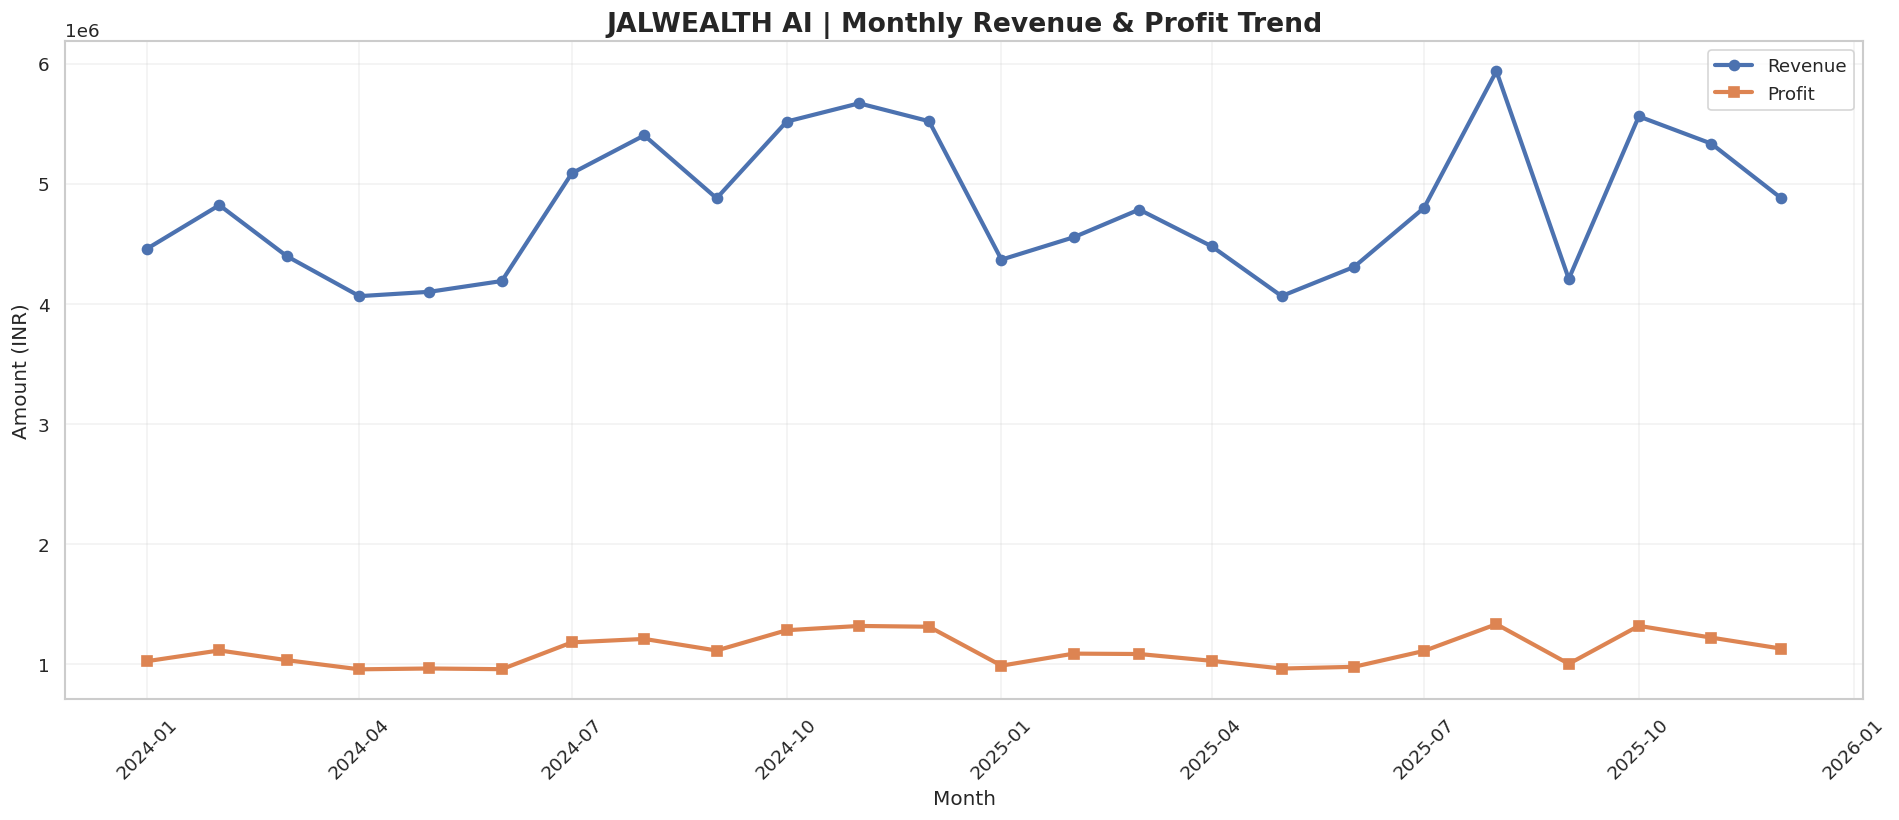


Monthly performance analysis completed.
Number of monthly observations: 24


In [21]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
 
# Validate source DataFrame 
if "eda_df" not in globals(): 
    raise NameError("eda_df is not defined. Run Cell 14 first.") 
 
required_columns = [ 
    "Order Date", 
    "Revenue (INR)", 
    "Profit (INR)", 
    "Order ID", 
    "Units Sold" 
] 
 
missing_columns = [ 
    col for col in required_columns 
    if col not in eda_df.columns 
] 
 
if missing_columns: 
    raise KeyError( 
        f"Missing required columns: {missing_columns}" 
    ) 
 
# Create a clean working copy 
monthly_source = eda_df.copy() 
 
monthly_source["Order Date"] = pd.to_datetime( 
    monthly_source["Order Date"], 
    errors="coerce" 
) 
 
for col in ["Revenue (INR)", "Profit (INR)", "Units Sold"]: 
    monthly_source[col] = pd.to_numeric( 
        monthly_source[col], 
        errors="coerce" 
    ) 
 
monthly_source = monthly_source.dropna( 
    subset=["Order Date"] 
) 
 
# Aggregate transaction data by calendar month 
monthly_performance = ( 
    monthly_source 
    .set_index("Order Date") 
    .resample("MS") 
    .agg( 
        Revenue=("Revenue (INR)", "sum"), 
        Profit=("Profit (INR)", "sum"), 
        Orders=("Order ID", "nunique"), 
        Units_Sold=("Units Sold", "sum") 
    ) 
    .reset_index() 
    .rename(columns={"Order Date": "Month_Date"}) 
) 
 
monthly_performance["Year_Month"] = ( 
    monthly_performance["Month_Date"].dt.strftime("%Y-%m") 
) 
 
# Calculate month-over-month changes 
monthly_performance["Revenue_Growth_Percent"] = ( 
    monthly_performance["Revenue"].pct_change() * 100 
) 
 
monthly_performance["Profit_Growth_Percent"] = ( 
    monthly_performance["Profit"].pct_change() * 100 
) 
 
# Calculate revenue and profit per order 
monthly_performance["Revenue_Per_Order"] = np.where( 
    monthly_performance["Orders"] > 0, 
    monthly_performance["Revenue"] / 
    monthly_performance["Orders"], 
    np.nan 
) 
 
monthly_performance["Profit_Margin_Percent"] = np.where( 
    monthly_performance["Revenue"] != 0, 
    monthly_performance["Profit"] / 
    monthly_performance["Revenue"] * 100, 
    np.nan 
) 
 
# Display monthly performance 
print("=" * 80) 
print("JALWEALTH AI | MONTHLY BUSINESS PERFORMANCE") 
print("=" * 80) 
 
display( 
    monthly_performance.style.format({ 
        "Revenue": "₹{:,.2f}", 
        "Profit": "₹{:,.2f}", 
        "Revenue_Per_Order": "₹{:,.2f}", 
        "Revenue_Growth_Percent": "{:.2f}%", 
        "Profit_Growth_Percent": "{:.2f}%", 
        "Profit_Margin_Percent": "{:.2f}%" 
    }) 
) 
 
# Visualize monthly revenue and profit 
fig, ax = plt.subplots(figsize=(16, 7)) 
 
ax.plot( 
    monthly_performance["Month_Date"], 
    monthly_performance["Revenue"], 
    marker="o", 
    linewidth=2.5, 
    label="Revenue" 
) 
 
ax.plot( 
    monthly_performance["Month_Date"], 
    monthly_performance["Profit"], 
    marker="s", 
    linewidth=2.5, 
    label="Profit" 
) 
 
ax.set_title( 
    "JALWEALTH AI | Monthly Revenue & Profit Trend", 
    fontsize=16, 
    fontweight="bold" 
) 
ax.set_xlabel("Month") 
ax.set_ylabel("Amount (INR)") 
ax.legend() 
ax.grid(alpha=0.25) 
plt.xticks(rotation=45) 
plt.tight_layout() 

# Save chart 
CHART_DIR.mkdir(parents=True, exist_ok=True) 
plt.savefig( 
CHART_DIR / "monthly_revenue_profit_trend.png", 
dpi=300, 
bbox_inches="tight" 
) 
plt.show() 
print("\nMonthly performance analysis completed.") 
print("Number of monthly observations:", len(monthly_performance))

 # FEATURE ENGINEERING

## 1. Introduction 
Feature Engineering is the process of transforming raw variables into meaningful analytical 
features that improve data interpretation and predictive modeling. 
JALWEALTH AI uses financial, operational, temporal, and environmental variables to construct 
an integrated feature engineering framework. 
## 2. Feature Engineering Categories 

### A. Financial Features
- Average Revenue per Unit
- Profit per Unit 
- Cost per Unit 
- Profit Margin 
- Individual Cost Contribution

### B. Operational Features 
- Production Efficiency 
- Units Manufactured per Order 
- Transportation Cost Intensity 
- Labour Cost Intensity 

### C. Environmental Features
- Biomass Processing Ratio
- Waste Diversion Ratio
- Biomass Utilization Efficiency 
- Revenue per Kilogram of Biomass
- Artisan Employment Intensity 

### D. Temporal Features
- Year
- Month
- Quarter 
- Day of Week
- Weekend Indicator
- Seasonal Month

## 3. Statistical Intelligence 
We will investigate: 
- Distribution characteristics 
- Correlation relationships 
- Statistical significance
- Outlier observations 
- Operational efficiency patterns 
    
## 4. Machine Learning Readiness 
Descriptive features and predictive features will be maintained separately. 
Features derived directly from a prediction target will not be used as independent predictors for 
that target. 
This separation is essential to prevent data leakage.
    
## 5. Expected Outcome 
A structured feature store containing engineered variables, statistical evidence, and validated 
analytical indicators. 

In [22]:
# FINANCIAL FEATURE ENGINEERING 

In [23]:
feature_df = eda_df.copy() 

# 1. Revenue efficiency 
feature_df["Revenue_Per_Unit"] = ( 
feature_df["Revenue (INR)"] / 
feature_df["Units Sold"].replace(0, np.nan) 
) 

# 2. Profit efficiency 
feature_df["Profit_Per_Unit"] = ( 
feature_df["Profit (INR)"] / 
feature_df["Units Sold"].replace(0, np.nan) 
) 

# 3. Cost efficiency 
feature_df["Cost_Per_Unit"] = ( 
feature_df["Reconstructed Total Cost (INR)"] / 
feature_df["Units Sold"].replace(0, np.nan) 
) 

# 4. Aggregate profitability 
feature_df["Gross_Profit_Margin_Percent"] = ( 
    feature_df["Profit (INR)"] / 
    feature_df["Revenue (INR)"].replace(0, np.nan) 
) * 100 
 
# 5. Cost component contribution 
for column in cost_components: 
 
    feature_name = ( 
        column.replace(" (INR)", "") 
        .replace(" ", "_") 
    ) 
 
    feature_df[f"{feature_name}_Share_Percent"] = ( 
        feature_df[column] / 
        feature_df["Reconstructed Total Cost (INR)"].replace( 
            0, np.nan 
        ) 
    ) * 100 
 
# 6. Discount impact indicator 
feature_df["Discount_Amount_Estimate"] = ( 
    feature_df["Revenue (INR)"] * 
    feature_df["Discount Rate"] 
) 
 
# 7. Revenue per order 
feature_df["Revenue_Per_Order"] = ( 
    feature_df["Revenue (INR)"] / 
    feature_df["Order ID"].map( 
        feature_df["Order ID"].value_counts() 
    ) 
) 
 
print("=" * 75) 
print("JALWEALTH AI | FINANCIAL FEATURE ENGINEERING") 
print("=" * 75) 
 
financial_features = [ 
    "Revenue_Per_Unit", 
    "Profit_Per_Unit", 
    "Cost_Per_Unit", 
    "Gross_Profit_Margin_Percent", 
    "Discount_Amount_Estimate" 
] 
 
display( 
    feature_df[financial_features].describe().round(2) 
) 
 
print("\nFinancial features created:", len(financial_features)) 

JALWEALTH AI | FINANCIAL FEATURE ENGINEERING


,Revenue_Per_Unit,Profit_Per_Unit,Cost_Per_Unit,Gross_Profit_Margin_Percent,Discount_Amount_Estimate
count,9976.00,9976.00,9976.00,9976.00,9976.00
mean,898.36,207.83,690.52,23.12,744.47
std,931.96,231.15,720.40,6.34,1335.66
min,129.20,16.28,91.80,12.00,0.00
25%,428.65,90.88,328.07,17.63,77.09
50%,634.65,141.25,486.59,23.22,342.30
75%,943.28,225.82,725.49,28.56,880.33
max,6483.00,2137.75,5296.87,34.00,18558.90



Financial features created: 5


In [24]:
 # ENVIRONMENTAL & OPERATIONAL FEATURE ENGINEERING

In [25]:
# Environmental resource efficiency 
feature_df["Biomass_Processing_Ratio_Percent"] = ( 
    feature_df["Water hyacinth processed (kg)"] / 
    feature_df["Water hyacinth collected (kg)"].replace( 
        0, np.nan 
    ) 
) * 100 
 
feature_df["Waste_Diversion_Ratio_Percent"] = ( 
    feature_df["Waste diverted (kg)"] / 
    feature_df["Water hyacinth collected (kg)"].replace( 
        0, np.nan 
    ) 
) * 100 
 
# Biomass utilization efficiency 
feature_df["Product_Output_Per_Kg_Biomass"] = ( 
    feature_df["Finished products manufactured"] / 
    feature_df["Water hyacinth processed (kg)"].replace( 
        0, np.nan 
    ) 
) 
 
# Biomass input intensity 
feature_df["Biomass_Collected_Per_Product"] = ( 
    feature_df["Water hyacinth collected (kg)"] / 
    feature_df["Finished products manufactured"].replace( 
        0, np.nan 
    ) 
) 
 
# Revenue generated per kg of processed biomass 
feature_df["Revenue_Per_Kg_Processed"] = ( 
    feature_df["Revenue (INR)"] / 
    feature_df["Water hyacinth processed (kg)"].replace( 
        0, np.nan 
    ) 
) 
 
# Employment intensity 
feature_df["Employment_Days_Per_100_Products"] = ( 
    feature_df["Artisan employment days"] / 
    feature_df["Finished products manufactured"].replace( 
        0, np.nan 
    ) 
) * 100 
 
# Processing cost intensity 
feature_df["Processing_Cost_Per_Unit"] = ( 
    feature_df["Processing Cost (INR)"] / 
    feature_df["Units Sold"].replace(0, np.nan) 
) 
 
# Transportation cost intensity 
feature_df["Transportation_Cost_Per_Unit"] = ( 
    feature_df["Transportation Cost (INR)"] / 
    feature_df["Units Sold"].replace(0, np.nan) 
) 
 
environmental_features = [ 
    "Biomass_Processing_Ratio_Percent", 
    "Waste_Diversion_Ratio_Percent", 
    "Product_Output_Per_Kg_Biomass", 
    "Biomass_Collected_Per_Product", 
    "Revenue_Per_Kg_Processed", 
    "Employment_Days_Per_100_Products", 
    "Processing_Cost_Per_Unit", 
    "Transportation_Cost_Per_Unit" 
] 
 
print("=" * 75) 
print("ENVIRONMENTAL & OPERATIONAL FEATURE ENGINEERING") 
print("=" * 75) 
 
display( 
    feature_df[environmental_features] 
    .describe() 
    .round(3) 
) 
 
print("\nEnvironmental and operational features created.")

ENVIRONMENTAL & OPERATIONAL FEATURE ENGINEERING


,Biomass_Processing_Ratio_Percent,Waste_Diversion_Ratio_Percent,Product_Output_Per_Kg_Biomass,Biomass_Collected_Per_Product,Revenue_Per_Kg_Processed,Employment_Days_Per_100_Products,Processing_Cost_Per_Unit,Transportation_Cost_Per_Unit
count,9976.000,9976.000,9976.000,9976.000,9976.000,9976.000,9976.000,9976.000
mean,89.513,94.970,0.825,2.686,447.370,62.154,118.370,56.209
std,2.040,1.734,0.834,2.932,291.209,55.398,124.226,68.468
min,85.294,90.909,0.076,0.160,95.355,17.000,14.765,3.365
25%,87.725,93.466,0.407,1.443,270.576,35.379,55.937,21.070
50%,89.533,94.967,0.572,1.964,378.838,46.167,83.437,36.592
75%,91.304,96.454,0.773,2.751,529.253,58.500,124.346,62.745
max,94.118,98.551,6.897,14.158,2176.271,262.440,995.811,698.755



Environmental and operational features created.


In [26]:
# TEMPORAL & SEASONAL FEATURE ENGINEERING 

In [27]:
feature_df["Order Date"] = pd.to_datetime( 
    feature_df["Order Date"], 
    errors="coerce" 
) 
 
# Calendar features 
feature_df["Calendar_Year"] = ( 
    feature_df["Order Date"].dt.year 
) 
 
feature_df["Calendar_Month"] = ( 
    feature_df["Order Date"].dt.month 
) 
 
feature_df["Calendar_Quarter"] = ( 
    feature_df["Order Date"].dt.quarter 
) 
 
feature_df["Day_Of_Week"] = ( 
    feature_df["Order Date"].dt.dayofweek 
) 
 
feature_df["Day_Of_Month"] = ( 
    feature_df["Order Date"].dt.day 
) 
 
feature_df["Is_Weekend"] = ( 
    feature_df["Day_Of_Week"] >= 5 
).astype(int) 
 
feature_df["Is_Quarter_End_Month"] = ( 
    feature_df["Calendar_Month"].isin([3, 6, 9, 12]) 
).astype(int) 
 
# Cyclical encoding for month 
feature_df["Month_Sin"] = np.sin( 
    2 * np.pi * feature_df["Calendar_Month"] / 12 
) 
 
feature_df["Month_Cos"] = np.cos( 
    2 * np.pi * feature_df["Calendar_Month"] / 12 
) 
 
# Season classification (India-oriented meteorological grouping) 
def classify_season(month): 
 
    if month in [3, 4, 5]: 
        return "Summer" 
 
    elif month in [6, 7, 8, 9]: 
        return "Monsoon" 
 
    elif month in [10, 11]: 
        return "Post-Monsoon" 
 
    else: 
        return "Winter" 
 
feature_df["Season"] = ( 
    feature_df["Calendar_Month"].apply(classify_season) 
) 
 
print("TEMPORAL FEATURE ENGINEERING COMPLETED") 
 
temporal_features = [ 
    "Calendar_Year", 
    "Calendar_Month", 
    "Calendar_Quarter", 
    "Day_Of_Week", 
    "Is_Weekend", 
    "Is_Quarter_End_Month", 
    "Month_Sin", 
    "Month_Cos", 
    "Season" 
] 
 
display( 
    feature_df[ 
        ["Order Date"] + temporal_features 
    ].head(10) 
) 
 
print("\nSeasonal Distribution") 
 
display( 
    feature_df["Season"] 
    .value_counts() 
    .rename_axis("Season") 
    .reset_index(name="Transaction_Count") 
)

TEMPORAL FEATURE ENGINEERING COMPLETED


,Order Date,Calendar_Year,Calendar_Month,Calendar_Quarter,Day_Of_Week,Is_Weekend,Is_Quarter_End_Month,Month_Sin,Month_Cos,Season
0,2024-01-01,2024,1,1,0,0,0,0.5,0.866025,Winter
1,2024-01-01,2024,1,1,0,0,0,0.5,0.866025,Winter
2,2024-01-01,2024,1,1,0,0,0,0.5,0.866025,Winter
3,2024-01-01,2024,1,1,0,0,0,0.5,0.866025,Winter
4,2024-01-01,2024,1,1,0,0,0,0.5,0.866025,Winter
5,2024-01-01,2024,1,1,0,0,0,0.5,0.866025,Winter
6,2024-01-01,2024,1,1,0,0,0,0.5,0.866025,Winter
7,2024-01-01,2024,1,1,0,0,0,0.5,0.866025,Winter
8,2024-01-01,2024,1,1,0,0,0,0.5,0.866025,Winter
9,2024-01-01,2024,1,1,0,0,0,0.5,0.866025,Winter



Seasonal Distribution


,Season,Transaction_Count
0,Monsoon,3333
1,Winter,2434
2,Summer,2283
3,Post-Monsoon,1926


In [28]:
 # ENGINEERED FEATURE CORRELATION ANALYSIS 

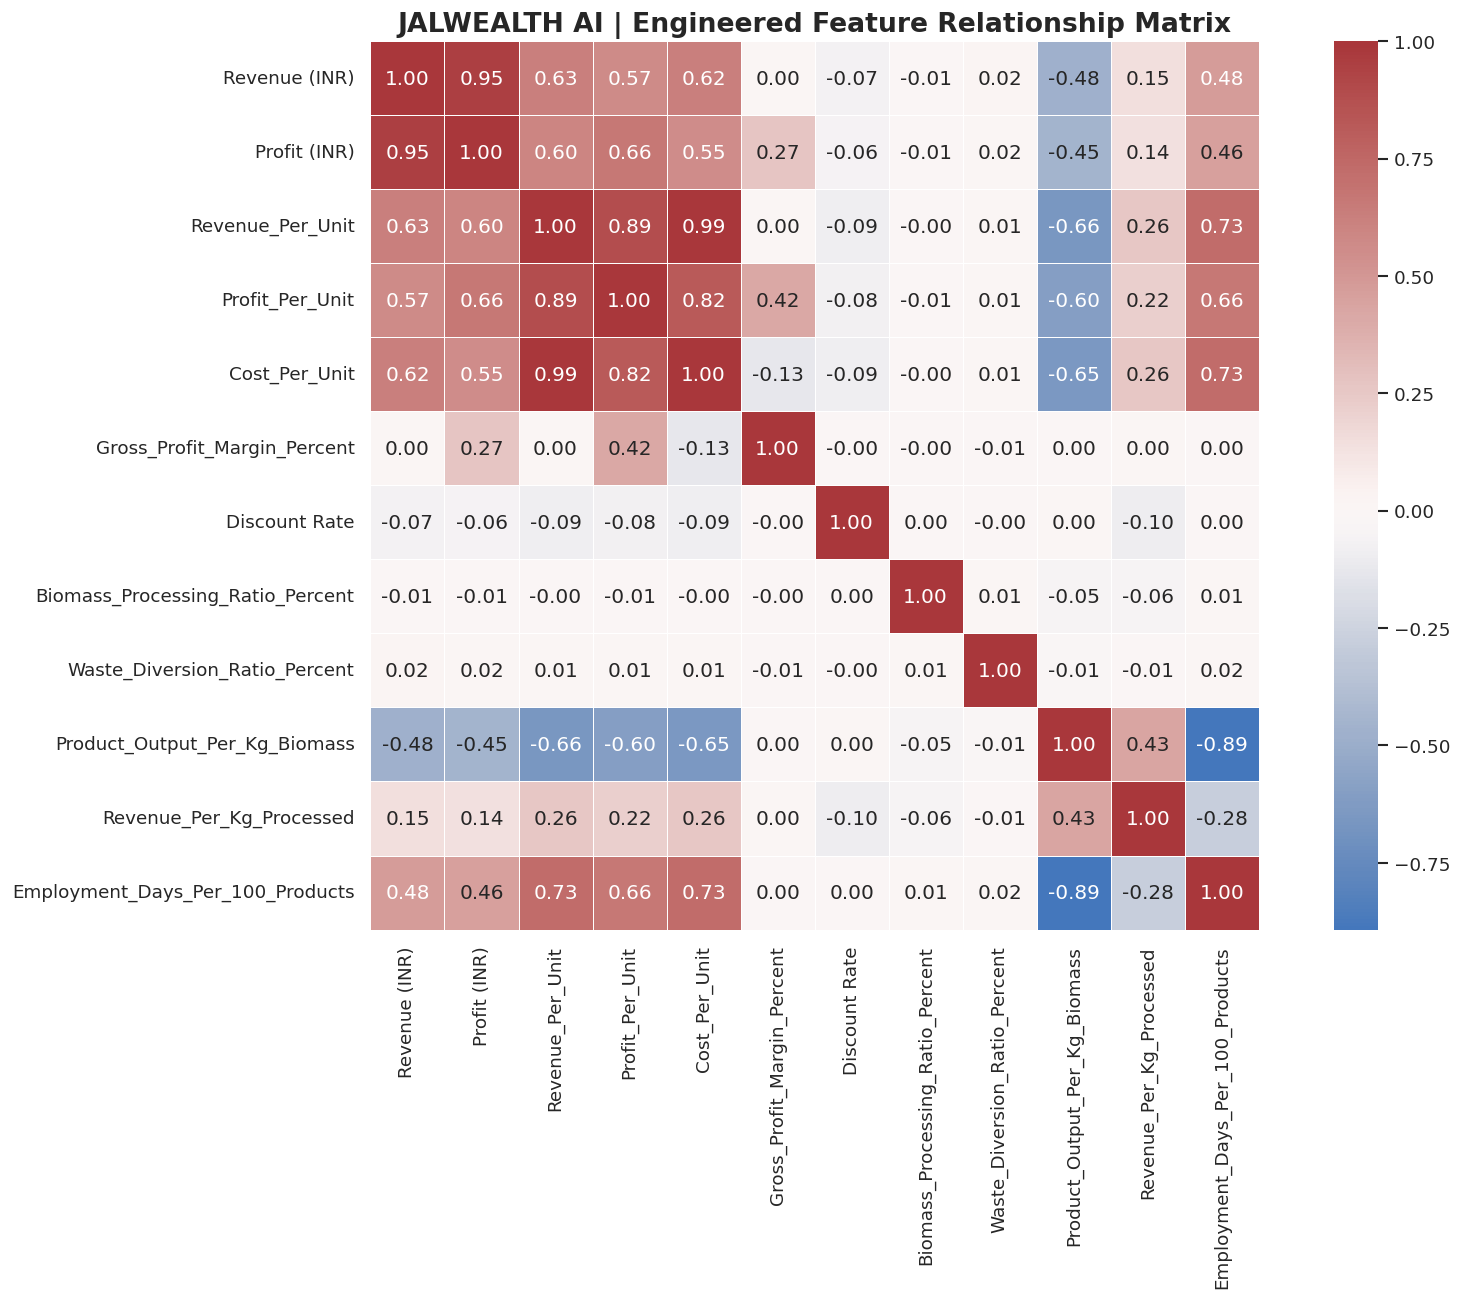


FEATURES MOST ASSOCIATED WITH PROFIT


,Spearman_Correlation_With_Profit
Revenue (INR),0.954702
Profit_Per_Unit,0.664842
Revenue_Per_Unit,0.597581
Cost_Per_Unit,0.553697
Employment_Days_Per_100_Products,0.457461
Product_Output_Per_Kg_Biomass,-0.454960
Gross_Profit_Margin_Percent,0.272288
Revenue_Per_Kg_Processed,0.135271
Discount Rate,-0.058926
Waste_Diversion_Ratio_Percent,0.015598



Interpretation: Spearman correlation measures monotonic association. It does not prove causation.


In [29]:
selected_features = [ 
    "Revenue (INR)", 
    "Profit (INR)", 
    "Revenue_Per_Unit", 
    "Profit_Per_Unit", 
    "Cost_Per_Unit", 
    "Gross_Profit_Margin_Percent", 
    "Discount Rate", 
    "Biomass_Processing_Ratio_Percent", 
    "Waste_Diversion_Ratio_Percent", 
    "Product_Output_Per_Kg_Biomass", 
    "Revenue_Per_Kg_Processed", 
    "Employment_Days_Per_100_Products" 
] 
 
feature_corr = feature_df[ 
    selected_features 
].corr(method="spearman") 
 
plt.figure(figsize=(15, 11)) 
 
sns.heatmap( 
    feature_corr, 
    annot=True, 
    fmt=".2f", 
    cmap="vlag", 
    center=0, 
    linewidths=0.6, 
    square=True 
) 
 
plt.title( 
    "JALWEALTH AI | Engineered Feature Relationship Matrix", 
    fontsize=16, 
    fontweight="bold" 
) 
 
plt.tight_layout() 
 
plt.savefig( 
    CHART_DIR / "engineered_feature_correlation.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show() 
 
# Rank feature relationships with reported profit 
profit_relationship = ( 
    feature_corr["Profit (INR)"] 
    .drop("Profit (INR)") 
    .sort_values( 
        key=lambda values: values.abs(), 
        ascending=False 
    ) 
) 
 
print("\nFEATURES MOST ASSOCIATED WITH PROFIT") 
 
display( 
    profit_relationship.to_frame( 
        "Spearman_Correlation_With_Profit" 
    ) 
) 
 
print( 
    "\nInterpretation: Spearman correlation measures " 
    "monotonic association. It does not prove causation." 
)

In [30]:
 # STATISTICAL HYPOTHESIS TESTING 

In [31]:
from scipy.stats import kruskal, spearmanr, mannwhitneyu 
 
ALPHA = 0.05 
 
# Prepare seasonal revenue groups 
season_groups = [ 
    group["Revenue (INR)"].dropna().values 
    for _, group in feature_df.groupby("Season") 
] 
 
season_names = [ 
    name 
    for name, group in feature_df.groupby("Season") 
    if group["Revenue (INR)"].notna().any() 
] 
 
# Kruskal-Wallis test 
season_statistic, season_pvalue = kruskal( 
    *season_groups 
) 
 
print("=" * 75) 
print("JALWEALTH AI | STATISTICAL HYPOTHESIS TESTING") 
print("=" * 75) 
 
print("\nTEST 1: SEASONAL REVENUE DIFFERENCE") 
print("-" * 60) 
 
print("Test: Kruskal-Wallis H-test") 
print("H0: Revenue distributions are equal across seasons.") 
print("H1: At least one seasonal distribution differs.") 
 
print(f"\nH Statistic: {season_statistic:.4f}") 
print(f"P-Value: {season_pvalue:.6f}") 
print(f"Significance Level: {ALPHA}") 
 
if season_pvalue < ALPHA: 
    print("\nResult: Reject H0.") 
    print("Statistically significant seasonal differences detected.") 
else: 
    print("\nResult: Fail to reject H0.") 
    print("Insufficient evidence of seasonal differences.") 
 
# Test association between discount and profit 
discount_values = feature_df[ 
    ["Discount Rate", "Profit (INR)"] 
].dropna() 
 
rho, pvalue = spearmanr( 
    discount_values["Discount Rate"], 
    discount_values["Profit (INR)"] 
) 
 
print("\nTEST 2: DISCOUNT AND PROFIT ASSOCIATION") 
print("-" * 60) 
 
print(f"Spearman Correlation: {rho:.4f}") 
print(f"P-Value: {pvalue:.6f}") 
 
if pvalue < ALPHA: 
    print("Statistically significant monotonic association detected.") 
else: 
    print("No statistically significant association detected.") 
 
print( 
    "\nNote: Statistical significance does not establish " 
    "a causal relationship." 
)

JALWEALTH AI | STATISTICAL HYPOTHESIS TESTING

TEST 1: SEASONAL REVENUE DIFFERENCE
------------------------------------------------------------
Test: Kruskal-Wallis H-test
H0: Revenue distributions are equal across seasons.
H1: At least one seasonal distribution differs.

H Statistic: 3.2125
P-Value: 0.360004
Significance Level: 0.05

Result: Fail to reject H0.
Insufficient evidence of seasonal differences.

TEST 2: DISCOUNT AND PROFIT ASSOCIATION
------------------------------------------------------------
Spearman Correlation: -0.0589
P-Value: 0.000000
Statistically significant monotonic association detected.

Note: Statistical significance does not establish a causal relationship.


In [32]:
 # IQR-BASED OUTLIER DETECTION 

OUTLIER DETECTION REPORT


,Feature,Q1,Q3,IQR,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Revenue (INR),3606.112,13441.868,9835.755,-11147.520,28195.500,670,6.716
1,Profit (INR),767.948,3101.995,2334.047,-2733.124,6603.066,727,7.287
2,Units Sold,7.000,19.000,12.000,-11.000,37.000,0,0.000
3,Reconstructed Total Cost (INR),2744.758,10341.313,7596.555,-8650.075,21736.145,679,6.806
4,Water hyacinth collected (kg),9.715,41.272,31.558,-37.621,88.609,581,5.824
5,Water hyacinth processed (kg),8.668,36.942,28.275,-33.745,79.355,580,5.814
6,Waste diverted (kg),9.128,39.210,30.082,-35.996,84.334,578,5.794



Records with at least one outlier flag: 957
Percentage of flagged records: 9.59 %


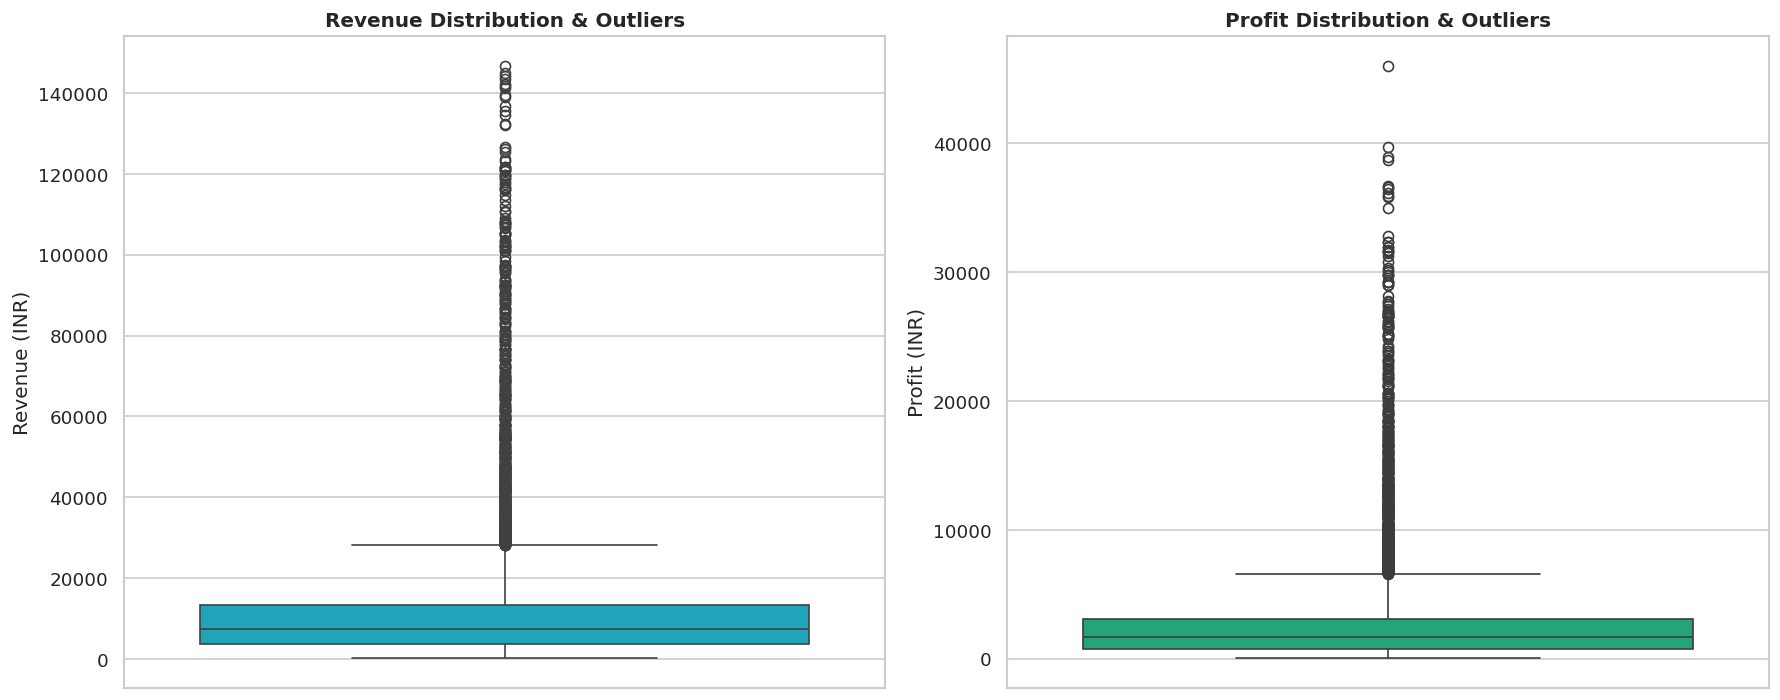


Outliers are flagged for investigation, not automatically removed.


In [33]:
outlier_columns = [ 
    "Revenue (INR)", 
    "Profit (INR)", 
    "Units Sold", 
    "Reconstructed Total Cost (INR)", 
    "Water hyacinth collected (kg)", 
    "Water hyacinth processed (kg)", 
    "Waste diverted (kg)" 
] 
 
outlier_results = [] 
 
outlier_flags = pd.DataFrame( 
    index=feature_df.index 
) 
 
for column in outlier_columns: 
 
    values = feature_df[column].dropna() 
 
    Q1 = values.quantile(0.25) 
    Q3 = values.quantile(0.75) 
 
    IQR = Q3 - Q1 
 
    lower_bound = Q1 - 1.5 * IQR 
    upper_bound = Q3 + 1.5 * IQR 
 
    flags = ( 
        (feature_df[column] < lower_bound) | 
        (feature_df[column] > upper_bound) 
    ) 
 
    outlier_flags[column] = flags.fillna(False) 
 
    outlier_results.append({ 
 
        "Feature": column, 
        "Q1": Q1, 
        "Q3": Q3, 
        "IQR": IQR, 
        "Lower_Bound": lower_bound, 
        "Upper_Bound": upper_bound, 
        "Outlier_Count": int(flags.sum()), 
        "Outlier_Percentage": ( 
            flags.sum() / len(feature_df) * 100 
        ) 
 
    }) 
 
outlier_report = pd.DataFrame(outlier_results) 
 
print("=" * 75) 
print("OUTLIER DETECTION REPORT") 
print("=" * 75) 
 
display(outlier_report.round(3)) 
 
# Total records with at least one flagged feature 
any_outlier = outlier_flags.any(axis=1) 
 
print( 
    "\nRecords with at least one outlier flag:", 
    any_outlier.sum() 
) 
 
print( 
    "Percentage of flagged records:", 
    round(any_outlier.mean() * 100, 2), "%" 
) 
 
# Visualize revenue and profit distributions 
fig, axes = plt.subplots(1, 2, figsize=(15, 6)) 
 
sns.boxplot( 
    y=feature_df["Revenue (INR)"], 
    ax=axes[0], 
    color="#06B6D4" 
) 
 
axes[0].set_title( 
    "Revenue Distribution & Outliers", 
    fontweight="bold" 
) 
 
sns.boxplot( 
    y=feature_df["Profit (INR)"], 
    ax=axes[1], 
    color="#10B981" 
) 
 
axes[1].set_title( 
    "Profit Distribution & Outliers", 
    fontweight="bold" 
) 
 
plt.tight_layout() 
 
plt.savefig( 
    CHART_DIR / "outlier_detection_analysis.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show() 
 
print( 
    "\nOutliers are flagged for investigation, " 
    "not automatically removed." 
)

In [34]:
# FEATURE INVENTORY & VALIDATION 

In [35]:
original_columns = set(eda_df.columns) 
 
engineered_columns = [ 
    column for column in feature_df.columns 
    if column not in original_columns 
] 
 
feature_inventory = pd.DataFrame({ 
 
    "Feature": engineered_columns, 
 
    "Data_Type": [ 
        str(feature_df[column].dtype) 
        for column in engineered_columns 
    ], 
 
    "Missing_Count": [ 
        feature_df[column].isna().sum() 
        for column in engineered_columns 
    ], 
 
    "Unique_Values": [ 
        feature_df[column].nunique(dropna=True) 
        for column in engineered_columns 
    ], 
 
    "Missing_Percentage": [ 
        feature_df[column].isna().mean() * 100 
        for column in engineered_columns 
    ] 
 
}) 
 
print("=" * 75) 
print("JALWEALTH AI | ENGINEERED FEATURE INVENTORY") 
print("=" * 75) 
 
print("Original Features:", len(original_columns)) 
print("New Engineered Features:", len(engineered_columns)) 
print("Total Features:", len(feature_df.columns)) 
 
display(feature_inventory.round(2)) 
 
# Environmental logical validation 
environmental_checks = { 
 
    "Processed biomass <= Collected biomass": ( 
        feature_df["Water hyacinth processed (kg)"] <= 
        feature_df["Water hyacinth collected (kg)"] 
    ).all(), 
 
    "Waste diverted <= Collected biomass": ( 
        feature_df["Waste diverted (kg)"] <= 
        feature_df["Water hyacinth collected (kg)"] 
    ).all(), 
 
    "Processing ratio within 0-100%": ( 
        feature_df[ 
            "Biomass_Processing_Ratio_Percent" 
        ].between(0, 100).all() 
    ), 
 
    "Waste diversion ratio within 0-100%": ( 
        feature_df[ 
            "Waste_Diversion_Ratio_Percent" 
        ].between(0, 100).all() 
    ), 
 
    "Revenue is non-negative": ( 
        feature_df["Revenue (INR)"] >= 0 
    ).all(), 
 
    "Units sold are positive": ( 
        feature_df["Units Sold"] > 0 
    ).all() 
 
} 
 
validation_df = pd.DataFrame( 
    list(environmental_checks.items()), 
    columns=["Validation_Check", "Passed"] 
) 
 
display(validation_df) 
 
if validation_df["Passed"].all(): 
    print("\nAll selected logical validation checks passed.") 
else: 
    print("\nWarning: Some validation checks failed. Investigate.")

JALWEALTH AI | ENGINEERED FEATURE INVENTORY
Original Features: 40
New Engineered Features: 30
Total Features: 70


,Feature,Data_Type,Missing_Count,Unique_Values,Missing_Percentage
0,Revenue_Per_Unit,float64,0,6332,0.0
1,Profit_Per_Unit,float64,0,9925,0.0
2,Cost_Per_Unit,float64,0,9966,0.0
3,Gross_Profit_Margin_Percent,float64,0,9976,0.0
4,Raw_Material_Cost_Share_Percent,float64,0,9976,0.0
5,Labour_Cost_Share_Percent,float64,0,9976,0.0
6,Processing_Cost_Share_Percent,float64,0,9976,0.0
7,Packaging_Cost_Share_Percent,float64,0,9976,0.0
8,Transportation_Cost_Share_Percent,float64,0,9976,0.0
9,Marketing_Cost_Share_Percent,float64,0,9976,0.0


,Validation_Check,Passed
0,Processed biomass <= Collected biomass,True
1,Waste diverted <= Collected biomass,True
2,Processing ratio within 0-100%,True
3,Waste diversion ratio within 0-100%,True
4,Revenue is non-negative,True
5,Units sold are positive,True



All selected logical validation checks passed.


In [36]:
 # MACHINE LEARNING & PREDICTIVE INTELLIGENCE 

## 1. Project Objective 
 
Develop a predictive intelligence framework capable of learning from historical business 
performance and estimating future revenue trends. 
 
## 2. Primary Prediction Task 
    
**Target Variable:
    ** Monthly Revenue (INR) 
**Problem Type:
    ** Supervised Machine Learning – Regression 

## 3. Candidate Models 
1. Historical Mean Baseline 
2. Linear Regression 
3. Ridge Regression 
4. Random Forest Regressor 
5. Gradient Boosting Regressor 
6. Extra Trees Regressor 
    
## 4. Validation Strategy 
    - Chronological Train-Test Split 
    - Time Series Cross-Validation
    - Baseline Comparison 
    - Residual Analysis
    - Prediction Error Analysis 
    
## 5. Evaluation Metrics
    - MAE: Mean Absolute Error 
    - RMSE: Root Mean Squared Error 
    - R²: Coefficient of Determination 
    - MAPE: Mean Absolute Percentage Error 

## 6. Model Selection Principle 
The final model will be selected using chronological validation performance, interpretability, and 
generalization. 
No model will be declared successful solely because of its training performance.
    
## 7. Important Limitation 
The available historical dataset contains only 24 monthly observations. Model results will 
therefore be considered exploratory, and long-term forecasting reliability will require additional 
historical data.

In [37]:
# LEAKAGE-SAFE MONTHLY REVENUE FORECAST FEATURE STORE 

In [38]:
if "monthly_performance" not in globals(): 
    raise NameError("Run corrected Cell 22 before Cell 33.") 
monthly_model_base = monthly_performance[ 
["Month_Date", "Revenue"] 
].copy() 
monthly_model_base = monthly_model_base.rename( 
columns={"Revenue": "Target_Revenue"} 
) 
monthly_model_base = ( 
monthly_model_base 
.sort_values("Month_Date") 
    .reset_index(drop=True) 
) 
 
# Create time-based predictors 
monthly_model_base["Month_Number"] = ( 
    monthly_model_base["Month_Date"].dt.month 
) 
 
monthly_model_base["Trend_Index"] = np.arange( 
    1, 
    len(monthly_model_base) + 1 
) 
 
monthly_model_base["Month_Sin"] = np.sin( 
    2 * np.pi * 
    monthly_model_base["Month_Number"] / 12 
) 
 
monthly_model_base["Month_Cos"] = np.cos( 
    2 * np.pi * 
    monthly_model_base["Month_Number"] / 12 
) 
 
# Historical revenue lag features 
for lag in [1, 2, 3, 6]: 
 
    monthly_model_base[f"Revenue_Lag_{lag}"] = ( 
        monthly_model_base["Target_Revenue"].shift(lag) 
    ) 
 
# Rolling averages use only previously observed months 
monthly_model_base["Revenue_Rolling_Mean_3"] = ( 
    monthly_model_base["Target_Revenue"] 
    .shift(1) 
    .rolling(window=3) 
    .mean() 
) 
 
monthly_model_base["Revenue_Rolling_Mean_6"] = ( 
    monthly_model_base["Target_Revenue"] 
    .shift(1) 
    .rolling(window=6) 
    .mean() 
) 
 
# Define exact model feature names 
FORECAST_FEATURES = [ 
    "Month_Number", 
    "Trend_Index", 
    "Month_Sin", 
    "Month_Cos", 
    "Revenue_Lag_1", 
    "Revenue_Lag_2", 
    "Revenue_Lag_3", 
    "Revenue_Lag_6", 
    "Revenue_Rolling_Mean_3", 
    "Revenue_Rolling_Mean_6" 
] 
 
# Build model-ready feature store 
forecast_feature_store = monthly_model_base.dropna( 
    subset=FORECAST_FEATURES + ["Target_Revenue"] 
).copy() 
 
forecast_feature_store = ( 
    forecast_feature_store 
    .reset_index(drop=True) 
) 
 
# Define full feature and target datasets 
X_forecast = forecast_feature_store[ 
    FORECAST_FEATURES 
].copy() 
 
y_forecast = forecast_feature_store[ 
    "Target_Revenue" 
].copy() 
 
print("=" * 80) 
print("JALWEALTH AI | MONTHLY FORECAST FEATURE STORE") 
print("=" * 80) 
 
print("Historical monthly observations:", len(monthly_model_base)) 
print("Usable model observations:", len(forecast_feature_store)) 
print("Number of features:", len(FORECAST_FEATURES)) 
 
print("\nForecast features:") 
for feature in FORECAST_FEATURES: 
    print("-", feature) 
 
print("\nFeature store preview:") 
display(forecast_feature_store.head()) 
 
print("\nFeature store shape:", forecast_feature_store.shape) 
 
assert forecast_feature_store[FORECAST_FEATURES].notna().all().all() 
assert forecast_feature_store["Target_Revenue"].notna().all() 
 
print("\nFeature store validation: PASSED")

JALWEALTH AI | MONTHLY FORECAST FEATURE STORE
Historical monthly observations: 24
Usable model observations: 18
Number of features: 10

Forecast features:
- Month_Number
- Trend_Index
- Month_Sin
- Month_Cos
- Revenue_Lag_1
- Revenue_Lag_2
- Revenue_Lag_3
- Revenue_Lag_6
- Revenue_Rolling_Mean_3
- Revenue_Rolling_Mean_6

Feature store preview:


,Month_Date,Target_Revenue,Month_Number,Trend_Index,Month_Sin,Month_Cos,Revenue_Lag_1,Revenue_Lag_2,Revenue_Lag_3,Revenue_Lag_6,Revenue_Rolling_Mean_3,Revenue_Rolling_Mean_6
0,2024-07-01,5086780.01,7,7,-0.500000,-8.660254e-01,4189328.73,4099512.58,4063260.07,4457876.34,4.117367e+06,4.337636e+06
1,2024-08-01,5401933.26,8,8,-0.866025,-5.000000e-01,5086780.01,4189328.73,4099512.58,4821023.77,4.458540e+06,4.442453e+06
2,2024-09-01,4878055.54,9,9,-1.000000,-1.836970e-16,5401933.26,5086780.01,4189328.73,4394813.63,4.892681e+06,4.539271e+06
3,2024-10-01,5516654.51,10,10,-0.866025,5.000000e-01,4878055.54,5401933.26,5086780.01,4063260.07,5.122256e+06,4.619812e+06
4,2024-11-01,5668824.87,11,11,-0.500000,8.660254e-01,5516654.51,4878055.54,5401933.26,4099512.58,5.265548e+06,4.862044e+06



Feature store shape: (18, 12)

Feature store validation: PASSED


# BASELINE MODEL DEVELOPMENT 

In [39]:
from sklearn.metrics import ( 
    mean_absolute_error, 
    mean_squared_error, 
    r2_score 
) 
 
# Validate the feature store 
required_objects = [ 
    "forecast_feature_store", 
    "FORECAST_FEATURES" 
] 
 
for object_name in required_objects: 
    if object_name not in globals():
        raise NameError(f"{object_name} is missing. Run corrected Cell 44." 
        ) 
 
ml_df = ( 
    forecast_feature_store 
    .copy() 
    .sort_values("Month_Date") 
    .reset_index(drop=True) 
) 
FEATURE_COLUMNS = list(FORECAST_FEATURES) 
TARGET_COLUMN = "Target_Revenue" 
X = ml_df[FEATURE_COLUMNS].copy() 
y = ml_df[TARGET_COLUMN].copy() 
# Validate minimum dataset size 
if len(ml_df) < 10:
    raise ValueError( 
"Insufficient monthly observations for this validation setup." 
) 
# Chronological 80:20 split 
split_index = int(len(ml_df) * 0.80) 
if split_index < 6 or len(ml_df) - split_index < 2: 
    raise ValueError( 
"Not enough observations for the selected train-test split." 
) 
X_train = X.iloc[:split_index].copy() 
X_test = X.iloc[split_index:].copy() 
y_train = y.iloc[:split_index].copy() 
y_test = y.iloc[split_index:].copy() 
train_dates = ml_df["Month_Date"].iloc[:split_index].copy() 
test_dates = ml_df["Month_Date"].iloc[split_index:].copy() 
# Data integrity checks 
assert len(X_train) == len(y_train) 
assert len(X_test) == len(y_test) 
assert train_dates.max() < test_dates.min() 
assert X_train.notna().all().all() 
assert X_test.notna().all().all() 
print("=" * 80) 
print("JALWEALTH AI | MACHINE LEARNING DATA PREPARATION") 
print("=" * 80) 
print("Total usable observations:", len(ml_df)) 
print("Training observations:", len(X_train)) 
print("Testing observations:", len(X_test)) 
print("Feature count:", len(FEATURE_COLUMNS)) 
print("\nTraining period:") 
print(train_dates.min(), "to", train_dates.max()) 
print("\nTesting period:") 
print(test_dates.min(), "to", test_dates.max()) 
print("\nTraining feature shape:", X_train.shape) 
print("Testing feature shape:", X_test.shape) 
display(ml_df.head()) 
print("\nChronological split validation: PASSED") 
print("Missing value validation: PASSED")

JALWEALTH AI | MACHINE LEARNING DATA PREPARATION
Total usable observations: 18
Training observations: 14
Testing observations: 4
Feature count: 10

Training period:
2024-07-01 00:00:00 to 2025-08-01 00:00:00

Testing period:
2025-09-01 00:00:00 to 2025-12-01 00:00:00

Training feature shape: (14, 10)
Testing feature shape: (4, 10)


,Month_Date,Target_Revenue,Month_Number,Trend_Index,Month_Sin,Month_Cos,Revenue_Lag_1,Revenue_Lag_2,Revenue_Lag_3,Revenue_Lag_6,Revenue_Rolling_Mean_3,Revenue_Rolling_Mean_6
0,2024-07-01,5086780.01,7,7,-0.500000,-8.660254e-01,4189328.73,4099512.58,4063260.07,4457876.34,4.117367e+06,4.337636e+06
1,2024-08-01,5401933.26,8,8,-0.866025,-5.000000e-01,5086780.01,4189328.73,4099512.58,4821023.77,4.458540e+06,4.442453e+06
2,2024-09-01,4878055.54,9,9,-1.000000,-1.836970e-16,5401933.26,5086780.01,4189328.73,4394813.63,4.892681e+06,4.539271e+06
3,2024-10-01,5516654.51,10,10,-0.866025,5.000000e-01,4878055.54,5401933.26,5086780.01,4063260.07,5.122256e+06,4.619812e+06
4,2024-11-01,5668824.87,11,11,-0.500000,8.660254e-01,5516654.51,4878055.54,5401933.26,4099512.58,5.265548e+06,4.862044e+06



Chronological split validation: PASSED
Missing value validation: PASSED


In [40]:
from sklearn.dummy import DummyRegressor 
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Baseline 1: Historical training mean 
mean_baseline = DummyRegressor( 
    strategy="mean" 
) 
 
mean_baseline.fit( 
    X_train, 
    y_train 
) 
 
mean_predictions = mean_baseline.predict(X_test) 
 
# Baseline 2: Previous month's actual revenue 
# Rolling one-step-ahead evaluation: 
# Each prediction uses the immediately preceding observed month. 
 
naive_predictions = ( 
    ml_df["Target_Revenue"] 
    .iloc[split_index - 1: -1] 
    .to_numpy() 
) 
 
# Verify prediction dimensions 
assert len(naive_predictions) == len(y_test) 
 
# Baseline metrics 
baseline_results = [] 
 
for model_name, predictions in [ 
    ("Historical Mean Baseline", mean_predictions), 
    ("Previous Month Naive Baseline", naive_predictions) 
]: 
 
    mae = mean_absolute_error( 
        y_test, 
        predictions 
    ) 
 
    rmse = np.sqrt( 
        mean_squared_error( 
            y_test, 
            predictions 
        ) 
    ) 
 
    baseline_results.append({ 
 
        "Model": model_name, 
        "MAE": mae, 
        "RMSE": rmse 
 
    }) 
 
baseline_df = pd.DataFrame(baseline_results) 
 
print("=" * 75) 
print("JALWEALTH AI | BASELINE MODEL PERFORMANCE") 
print("=" * 75) 
 
display( 
    baseline_df.style.format({ 
        "MAE": "₹{:,.2f}", 
        "RMSE": "₹{:,.2f}" 
    }) 
) 
 
print( 
    "\nBaseline evaluation completed. " 
    "Advanced models must be compared against these results." 
)

JALWEALTH AI | BASELINE MODEL PERFORMANCE


,Model,MAE,RMSE
0,Historical Mean Baseline,"₹452,010.78","₹518,430.40"
1,Previous Month Naive Baseline,"₹941,104.83","₹1,127,187.74"



Baseline evaluation completed. Advanced models must be compared against these results.


# ADVANCED MACHINE LEARNING MODEL ARCHITECTURE 

In [41]:
from sklearn.linear_model import LinearRegression, Ridge 
from sklearn.ensemble import ( 
    RandomForestRegressor, 
    GradientBoostingRegressor, 
    ExtraTreesRegressor 
) 
from sklearn.preprocessing import StandardScaler 
from sklearn.pipeline import Pipeline 
 
# Model configuration 
model_configurations = { 
 
    "Linear Regression": Pipeline([ 
        ("scaler", StandardScaler()), 
        ("model", LinearRegression()) 
    ]), 
 
    "Ridge Regression": Pipeline([ 
        ("scaler", StandardScaler()), 
        ("model", Ridge(alpha=10.0)) 
    ]), 
 
    "Random Forest": Pipeline([ 
        ("scaler", "passthrough"), 
        ("model", RandomForestRegressor( 
            n_estimators=200, 
            max_depth=3, 
            min_samples_leaf=2, 
            random_state=RANDOM_STATE 
        )) 
    ]), 
 
    "Gradient Boosting": Pipeline([ 
        ("scaler", "passthrough"), 
        ("model", GradientBoostingRegressor( 
            n_estimators=50, 
            learning_rate=0.03, 
            max_depth=1, 
            loss="huber", 
            random_state=RANDOM_STATE 
        )) 
    ]), 
 
    "Extra Trees": Pipeline([ 
        ("scaler", "passthrough"), 
        ("model", ExtraTreesRegressor( 
            n_estimators=200, 
            max_depth=3, 
            min_samples_leaf=2, 
            random_state=RANDOM_STATE 
        )) 
    ]) 
} 
 
print("=" * 75) 
print("JALWEALTH AI | MACHINE LEARNING MODEL REGISTRY") 
print("=" * 75) 
 
for index, (name, pipeline) in enumerate( 
    model_configurations.items(), 
    start=1 
): 
 
    print(f"{index}. {name}") 
    print("   Pipeline:", pipeline) 
 
print("\nTotal Advanced Models:", len(model_configurations)) 
print("All model pipelines registered successfully.")

JALWEALTH AI | MACHINE LEARNING MODEL REGISTRY
1. Linear Regression
   Pipeline: Pipeline(steps=[('scaler', StandardScaler()), ('model', LinearRegression())])
2. Ridge Regression
   Pipeline: Pipeline(steps=[('scaler', StandardScaler()), ('model', Ridge(alpha=10.0))])
3. Random Forest
   Pipeline: Pipeline(steps=[('scaler', 'passthrough'),
                ('model',
                 RandomForestRegressor(max_depth=3, min_samples_leaf=2,
                                       n_estimators=200, random_state=42))])
4. Gradient Boosting
   Pipeline: Pipeline(steps=[('scaler', 'passthrough'),
                ('model',
                 GradientBoostingRegressor(learning_rate=0.03, loss='huber',
                                           max_depth=1, n_estimators=50,
                                           random_state=42))])
5. Extra Trees
   Pipeline: Pipeline(steps=[('scaler', 'passthrough'),
                ('model',
                 ExtraTreesRegressor(max_depth=3, min_samples_leaf=2,


In [42]:
 # MODEL TRAINING & HOLDOUT EVALUATION 

In [43]:
def calculate_regression_metrics(actual, predicted): 
 
    actual = np.asarray(actual) 
    predicted = np.asarray(predicted) 
 
    mae = mean_absolute_error(actual, predicted) 
 
    rmse = np.sqrt( 
        mean_squared_error(actual, predicted) 
    ) 
 
    r2 = r2_score(actual, predicted) 
 
    non_zero = actual != 0 
 
    mape = ( 
        np.mean( 
            np.abs( 
                (actual[non_zero] - predicted[non_zero]) 
                / actual[non_zero] 
            ) 
        ) * 100 
        if non_zero.any() 
        else np.nan 
    ) 
 
    return { 
        "MAE": mae, 
        "RMSE": rmse, 
        "R2": r2, 
        "MAPE_Percent": mape 
    } 
 
 
trained_models = {} 
model_predictions = {} 
evaluation_results = [] 
 
for model_name, pipeline in model_configurations.items(): 
 
    # Train model 
    pipeline.fit( 
        X_train, 
        y_train 
    ) 
 
    # Generate predictions 
    predictions = pipeline.predict(X_test) 
 
    trained_models[model_name] = pipeline 
    model_predictions[model_name] = predictions 
 
    # Evaluate 
    metrics = calculate_regression_metrics( 
        y_test, 
        predictions 
    ) 
 
    evaluation_results.append({ 
        "Model": model_name, 
        **metrics 
    }) 
 
# Add baseline models 
for model_name, predictions in [ 
    ("Historical Mean Baseline", mean_predictions), 
    ("Previous Month Naive Baseline", naive_predictions) 
]: 
 
    metrics = calculate_regression_metrics( 
        y_test, 
        predictions 
    ) 
 
    evaluation_results.append({ 
        "Model": model_name, 
        **metrics 
    }) 
 
model_evaluation_df = pd.DataFrame( 
    evaluation_results 
) 
 
model_evaluation_df = model_evaluation_df.sort_values( 
    "MAE" 
).reset_index(drop=True) 
 
print("=" * 80) 
print("JALWEALTH AI | HOLDOUT MODEL PERFORMANCE") 
print("=" * 80) 
 
display( 
    model_evaluation_df.style.format({ 
        "MAE": "₹{:,.2f}", 
        "RMSE": "₹{:,.2f}", 
        "R2": "{:.4f}", 
        "MAPE_Percent": "{:.2f}%" 
    }) 
) 
 
model_evaluation_df.to_csv( 
    REPORT_DIR / "ML_Holdout_Model_Comparison.csv", 
    index=False 
) 
 
print("\nModel training and holdout evaluation completed.")

JALWEALTH AI | HOLDOUT MODEL PERFORMANCE


,Model,MAE,RMSE,R2,MAPE_Percent
0,Gradient Boosting,"₹439,120.00","₹585,613.58",-0.2838,9.71%
1,Historical Mean Baseline,"₹452,010.78","₹518,430.40",-0.0061,9.33%
2,Extra Trees,"₹506,056.84","₹627,876.88",-0.4758,11.06%
3,Random Forest,"₹533,808.35","₹684,780.71",-0.7554,11.75%
4,Ridge Regression,"₹545,425.99","₹631,294.19",-0.4919,11.71%
5,Linear Regression,"₹920,992.73","₹1,004,773.55",-2.7792,19.14%
6,Previous Month Naive Baseline,"₹941,104.83","₹1,127,187.74",-3.7562,19.76%



Model training and holdout evaluation completed.


In [44]:
# EXPANDING WINDOW TIME SERIES CROSS-VALIDATION 

In [45]:
from sklearn.model_selection import TimeSeriesSplit 
from sklearn.base import clone 
 
tscv = TimeSeriesSplit( 
    n_splits=3, 
    test_size=2 
) 
 
cv_results = [] 
 
for model_name, pipeline in model_configurations.items(): 
 
    fold_mae = [] 
    fold_rmse = [] 
 
    for fold, (train_idx, val_idx) in enumerate( 
        tscv.split(X_train), 
        start=1 
    ): 
 
        X_fold_train = X_train.iloc[train_idx] 
        X_fold_val = X_train.iloc[val_idx] 
 
        y_fold_train = y_train.iloc[train_idx] 
        y_fold_val = y_train.iloc[val_idx] 
 
        # Fresh model for every fold 
        fold_model = clone(pipeline) 
 
        fold_model.fit( 
            X_fold_train, 
            y_fold_train 
        ) 
 
        fold_predictions = fold_model.predict( 
            X_fold_val 
        ) 
 
        fold_mae.append( 
            mean_absolute_error( 
                y_fold_val, 
                fold_predictions 
            ) 
        ) 
 
        fold_rmse.append( 
            np.sqrt( 
                mean_squared_error( 
                    y_fold_val, 
                    fold_predictions 
                ) 
            ) 
        ) 
 
    cv_results.append({ 
 
        "Model": model_name, 
        "Mean_CV_MAE": np.mean(fold_mae), 
        "Std_CV_MAE": np.std(fold_mae), 
        "Mean_CV_RMSE": np.mean(fold_rmse), 
        "Fold_Count": len(fold_mae) 
 
    }) 
 
cv_results_df = pd.DataFrame( 
    cv_results 
).sort_values( 
    "Mean_CV_MAE" 
).reset_index(drop=True) 
 
print("=" * 80) 
print("JALWEALTH AI | TIME SERIES CROSS-VALIDATION") 
print("=" * 80) 
 
display( 
    cv_results_df.style.format({ 
        "Mean_CV_MAE": "₹{:,.2f}", 
        "Std_CV_MAE": "₹{:,.2f}", 
        "Mean_CV_RMSE": "₹{:,.2f}" 
    }) 
) 
 
cv_results_df.to_csv( 
    REPORT_DIR / "ML_TimeSeries_CrossValidation.csv", 
    index=False 
) 
 
print("\nChronological cross-validation completed.")

JALWEALTH AI | TIME SERIES CROSS-VALIDATION


,Model,Mean_CV_MAE,Std_CV_MAE,Mean_CV_RMSE,Fold_Count
0,Ridge Regression,"₹382,908.45","₹191,986.89","₹466,654.89",3
1,Gradient Boosting,"₹437,460.78","₹140,603.36","₹486,196.40",3
2,Extra Trees,"₹441,691.81","₹211,616.68","₹502,951.91",3
3,Random Forest,"₹452,836.15","₹145,622.50","₹512,889.59",3
4,Linear Regression,"₹2,894,328.99","₹1,985,732.41","₹2,971,583.92",3



Chronological cross-validation completed.


In [46]:
# ADVANCED MODEL COMPARISON VISUALIZATION 

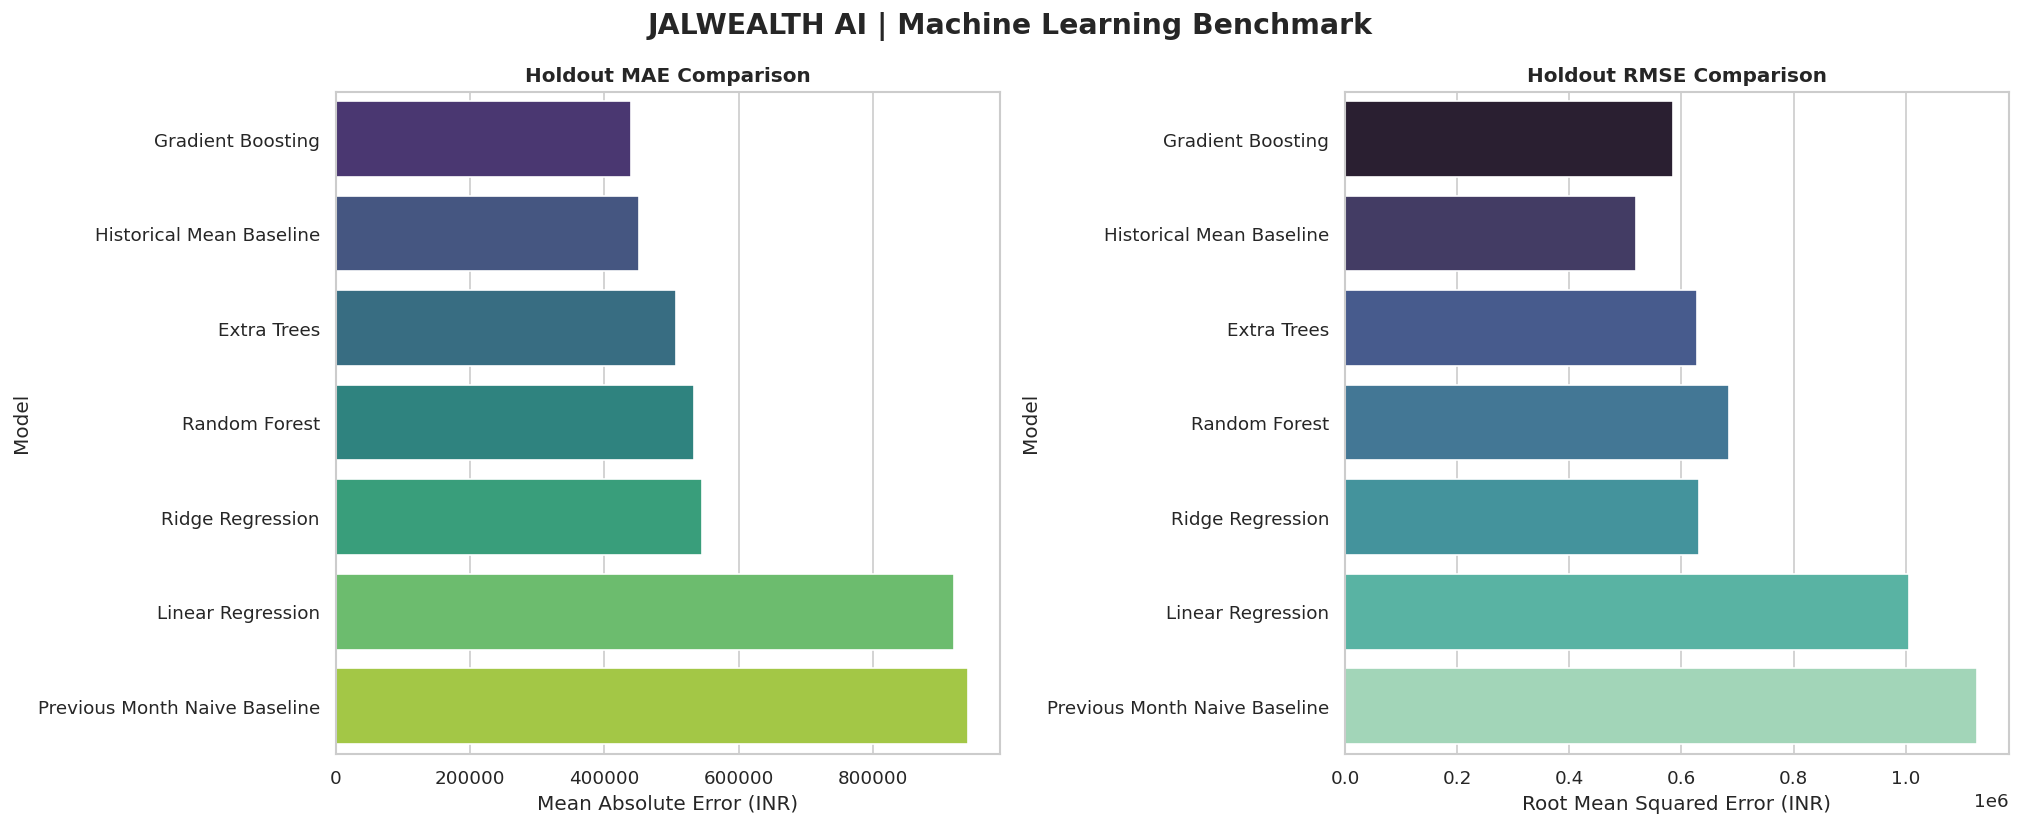

Model comparison visualization completed.


In [47]:
comparison_df = model_evaluation_df.sort_values("MAE").copy() 
 
fig, axes = plt.subplots( 
    1, 2, 
    figsize=(17, 7) 
) 
 
sns.barplot( 
    data=comparison_df, 
    x="MAE", 
    y="Model", 
    hue="Model", 
    palette="viridis", 
    legend=False, 
    ax=axes[0] 
) 
 
axes[0].set_title( 
    "Holdout MAE Comparison", 
    fontweight="bold" 
) 
 
axes[0].set_xlabel("Mean Absolute Error (INR)") 
 
sns.barplot( 
    data=comparison_df, 
    x="RMSE", 
    y="Model", 
    hue="Model", 
    palette="mako", 
    legend=False, 
    ax=axes[1] 
) 
 
axes[1].set_title( 
    "Holdout RMSE Comparison", 
    fontweight="bold" 
) 
 
axes[1].set_xlabel("Root Mean Squared Error (INR)") 
 
plt.suptitle( 
    "JALWEALTH AI | Machine Learning Benchmark", 
    fontsize=17, 
    fontweight="bold" 
) 
 
plt.tight_layout() 
 
plt.savefig( 
    CHART_DIR / "ml_model_comparison.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show() 
 
print("Model comparison visualization completed.") 

In [48]:
# BASELINE VS ADVANCED ML CROSS-VALIDATION 

In [49]:
baseline_cv_results = [] 
 
for baseline_name in [ 
    "Historical Mean Baseline", 
    "Previous Month Naive Baseline" 
]: 
 
    fold_scores = [] 
 
    for train_idx, val_idx in tscv.split(X_train): 
 
        fold_actual = y_train.iloc[val_idx] 
 
        if baseline_name == "Historical Mean Baseline": 
 
            # Predict using the training-fold average 
            fold_predictions = np.repeat( 
                y_train.iloc[train_idx].mean(), 
                len(val_idx) 
            ) 
 
        else: 
 
            # Predict using the previous observed month 
            fold_predictions = y_train.iloc[ 
                val_idx - 1 
            ].to_numpy() 
 
        fold_mae = mean_absolute_error( 
            fold_actual, 
            fold_predictions 
        ) 
 
        fold_scores.append(fold_mae) 
 
    baseline_cv_results.append({ 
 
        "Model": baseline_name, 
        "Mean_CV_MAE": np.mean(fold_scores), 
        "Std_CV_MAE": np.std(fold_scores), 
        "Model_Type": "Baseline" 
 
    }) 
 
 
# Advanced model cross-validation results 
advanced_cv_comparison = cv_results_df.copy() 
 
advanced_cv_comparison["Model_Type"] = "Advanced ML" 
 
 
# Combine all model results 
complete_cv_comparison = pd.concat( 
    [ 
        advanced_cv_comparison, 
        pd.DataFrame(baseline_cv_results) 
    ], 
    ignore_index=True 
) 
 
 
# Rank models by lowest cross-validation MAE 
complete_cv_comparison = ( 
    complete_cv_comparison 
    .sort_values("Mean_CV_MAE") 
    .reset_index(drop=True) 
) 
 
 
# Display results 
print("=" * 80) 
print("JALWEALTH AI | BASELINE VS ADVANCED ML") 
print("=" * 80) 
 
display( 
    complete_cv_comparison.style.format({ 
        "Mean_CV_MAE": "₹{:,.2f}", 
        "Std_CV_MAE": "₹{:,.2f}" 
    }) 
) 
 
 
# Export comparison report 
complete_cv_comparison.to_csv( 
    REPORT_DIR / "Complete_CV_Model_Benchmark.csv", 
    index=False 
) 
 
 
# Identify best baseline 
best_baseline = ( 
    complete_cv_comparison[ 
        complete_cv_comparison["Model_Type"] == "Baseline" 
    ] 
    .sort_values("Mean_CV_MAE") 
    .iloc[0] 
) 
 
# Identify best advanced model 
best_advanced = ( 
    complete_cv_comparison[ 
        complete_cv_comparison["Model_Type"] == "Advanced ML" 
    ] 
    .sort_values("Mean_CV_MAE") 
    .iloc[0] 
) 
 
 
print("\nBEST BASELINE MODEL:") 
print(best_baseline["Model"]) 
print(f"CV MAE: ₹{best_baseline['Mean_CV_MAE']:,.2f}") 
 
print("\nBEST ADVANCED MODEL:") 
print(best_advanced["Model"]) 
print(f"CV MAE: ₹{best_advanced['Mean_CV_MAE']:,.2f}") 
 
 
if best_advanced["Mean_CV_MAE"] < best_baseline["Mean_CV_MAE"]: 
 
    print("\nRESULT: Advanced ML outperformed the best baseline.") 
 
else: 
 
    print("\nRESULT: Advanced ML did not outperform the best baseline.") 
 
print("\nBenchmark report saved successfully.")

JALWEALTH AI | BASELINE VS ADVANCED ML


,Model,Mean_CV_MAE,Std_CV_MAE,Mean_CV_RMSE,Fold_Count,Model_Type
0,Ridge Regression,"₹382,908.45","₹191,986.89",466654.887919,3.000000,Advanced ML
1,Gradient Boosting,"₹437,460.78","₹140,603.36",486196.403388,3.000000,Advanced ML
2,Extra Trees,"₹441,691.81","₹211,616.68",502951.910681,3.000000,Advanced ML
3,Random Forest,"₹452,836.15","₹145,622.50",512889.588520,3.000000,Advanced ML
4,Previous Month Naive Baseline,"₹470,632.01","₹245,034.21",nan,nan,Baseline
5,Historical Mean Baseline,"₹634,186.49","₹149,283.23",nan,nan,Baseline
6,Linear Regression,"₹2,894,328.99","₹1,985,732.41",2971583.921373,3.000000,Advanced ML



BEST BASELINE MODEL:
Previous Month Naive Baseline
CV MAE: ₹470,632.01

BEST ADVANCED MODEL:
Ridge Regression
CV MAE: ₹382,908.45

RESULT: Advanced ML outperformed the best baseline.

Benchmark report saved successfully.


In [50]:
 # FINAL MODEL SELECTION & PERFORMANCE REPORT

In [51]:
# 1. Select the best advanced ML model 
best_advanced = ( 
    complete_cv_comparison[ 
        complete_cv_comparison["Model_Type"] == "Advanced ML" 
    ] 
    .sort_values("Mean_CV_MAE") 
    .iloc[0] 
) 
 
best_advanced_name = best_advanced["Model"] 
best_advanced_cv_mae = best_advanced["Mean_CV_MAE"] 
 
 
# 2. Select the best baseline model 
best_baseline = ( 
    complete_cv_comparison[ 
        complete_cv_comparison["Model_Type"] == "Baseline" 
    ] 
    .sort_values("Mean_CV_MAE") 
    .iloc[0] 
) 
 
best_baseline_name = best_baseline["Model"] 
best_baseline_cv_mae = best_baseline["Mean_CV_MAE"] 
 
 
# 3. Retrieve selected advanced model's holdout performance 
selected_holdout = model_evaluation_df[ 
    model_evaluation_df["Model"] == best_advanced_name 
].iloc[0] 
 
 
# 4. Compare advanced model against baseline 
improvement = ( 
    (best_baseline_cv_mae - best_advanced_cv_mae) 
    / best_baseline_cv_mae 
) * 100 if best_baseline_cv_mae != 0 else np.nan 
 
 
# 5. Display final selection report 
print("=" * 80) 
print("JALWEALTH AI | FINAL MODEL SELECTION REPORT") 
print("=" * 80) 
 
print("\nBEST ADVANCED ML MODEL") 
print("-" * 40) 
print("Selected Model:", best_advanced_name) 
print(f"Cross-Validation MAE: ₹{best_advanced_cv_mae:,.2f}") 
 
print("\nHOLDOUT TEST PERFORMANCE") 
print("-" * 40) 
print(f"MAE:  ₹{selected_holdout['MAE']:,.2f}") 
print(f"RMSE: ₹{selected_holdout['RMSE']:,.2f}") 
print(f"R²:   {selected_holdout['R2']:.4f}") 
print(f"MAPE: {selected_holdout['MAPE_Percent']:.2f}%") 
 
print("\nBASELINE COMPARISON") 
print("-" * 40) 
print("Best Baseline:", best_baseline_name) 
print(f"Baseline CV MAE: ₹{best_baseline_cv_mae:,.2f}") 
 
if best_advanced_cv_mae < best_baseline_cv_mae: 
 
    print( 
        f"\nAdvanced model reduced CV MAE by " 
        f"{improvement:.2f}% compared with the best baseline." 
    ) 
 
else: 
 
    print( 
        f"\nAdvanced model CV MAE is " 
        f"{abs(improvement):.2f}% higher than the best baseline." 
    ) 
 
 
# 6. Save selected model name and report 
final_model_selection = pd.DataFrame([{ 
 
    "Selected_Advanced_Model": best_advanced_name, 
    "Advanced_CV_MAE": best_advanced_cv_mae, 
    "Best_Baseline_Model": best_baseline_name, 
    "Baseline_CV_MAE": best_baseline_cv_mae, 
    "Improvement_Percent": improvement, 
    "Holdout_MAE": selected_holdout["MAE"], 
    "Holdout_RMSE": selected_holdout["RMSE"], 
    "Holdout_R2": selected_holdout["R2"], 
    "Holdout_MAPE_Percent": selected_holdout["MAPE_Percent"] 
 
}]) 
 
final_model_selection.to_csv( 
    REPORT_DIR / "Final_Model_Selection_Report.csv", 
    index=False 
) 
# Store selected model for subsequent cells 
final_model = trained_models[best_advanced_name] 
print("\n" + "=" * 80) 
print("FINAL MODEL:", best_advanced_name) 
print("Model selection report exported successfully.") 
print("=" * 80) 

JALWEALTH AI | FINAL MODEL SELECTION REPORT

BEST ADVANCED ML MODEL
----------------------------------------
Selected Model: Ridge Regression
Cross-Validation MAE: ₹382,908.45

HOLDOUT TEST PERFORMANCE
----------------------------------------
MAE:  ₹545,425.99
RMSE: ₹631,294.19
R²:   -0.4919
MAPE: 11.71%

BASELINE COMPARISON
----------------------------------------
Best Baseline: Previous Month Naive Baseline
Baseline CV MAE: ₹470,632.01

Advanced model reduced CV MAE by 18.64% compared with the best baseline.

FINAL MODEL: Ridge Regression
Model selection report exported successfully.


In [52]:
# ACTUAL VS PREDICTED REVENUE & RESIDUAL ANALYSIS 

JALWEALTH AI | ACTUAL VS PREDICTED REVENUE
Selected Model: Ridge Regression


,Month,Actual_Revenue,Predicted_Revenue,Residual,Absolute_Error,Percentage_Error
0,2025-09-01 00:00:00,"₹4,206,898.08","₹5,282,333.18","₹-1,075,435.10","₹1,075,435.10",25.56%
1,2025-10-01 00:00:00,"₹5,559,989.30","₹5,159,416.62","₹400,572.68","₹400,572.68",7.20%
2,2025-11-01 00:00:00,"₹5,333,688.08","₹5,567,989.18","₹-234,301.10","₹234,301.10",4.39%
3,2025-12-01 00:00:00,"₹4,878,736.18","₹5,350,131.26","₹-471,395.08","₹471,395.08",9.66%


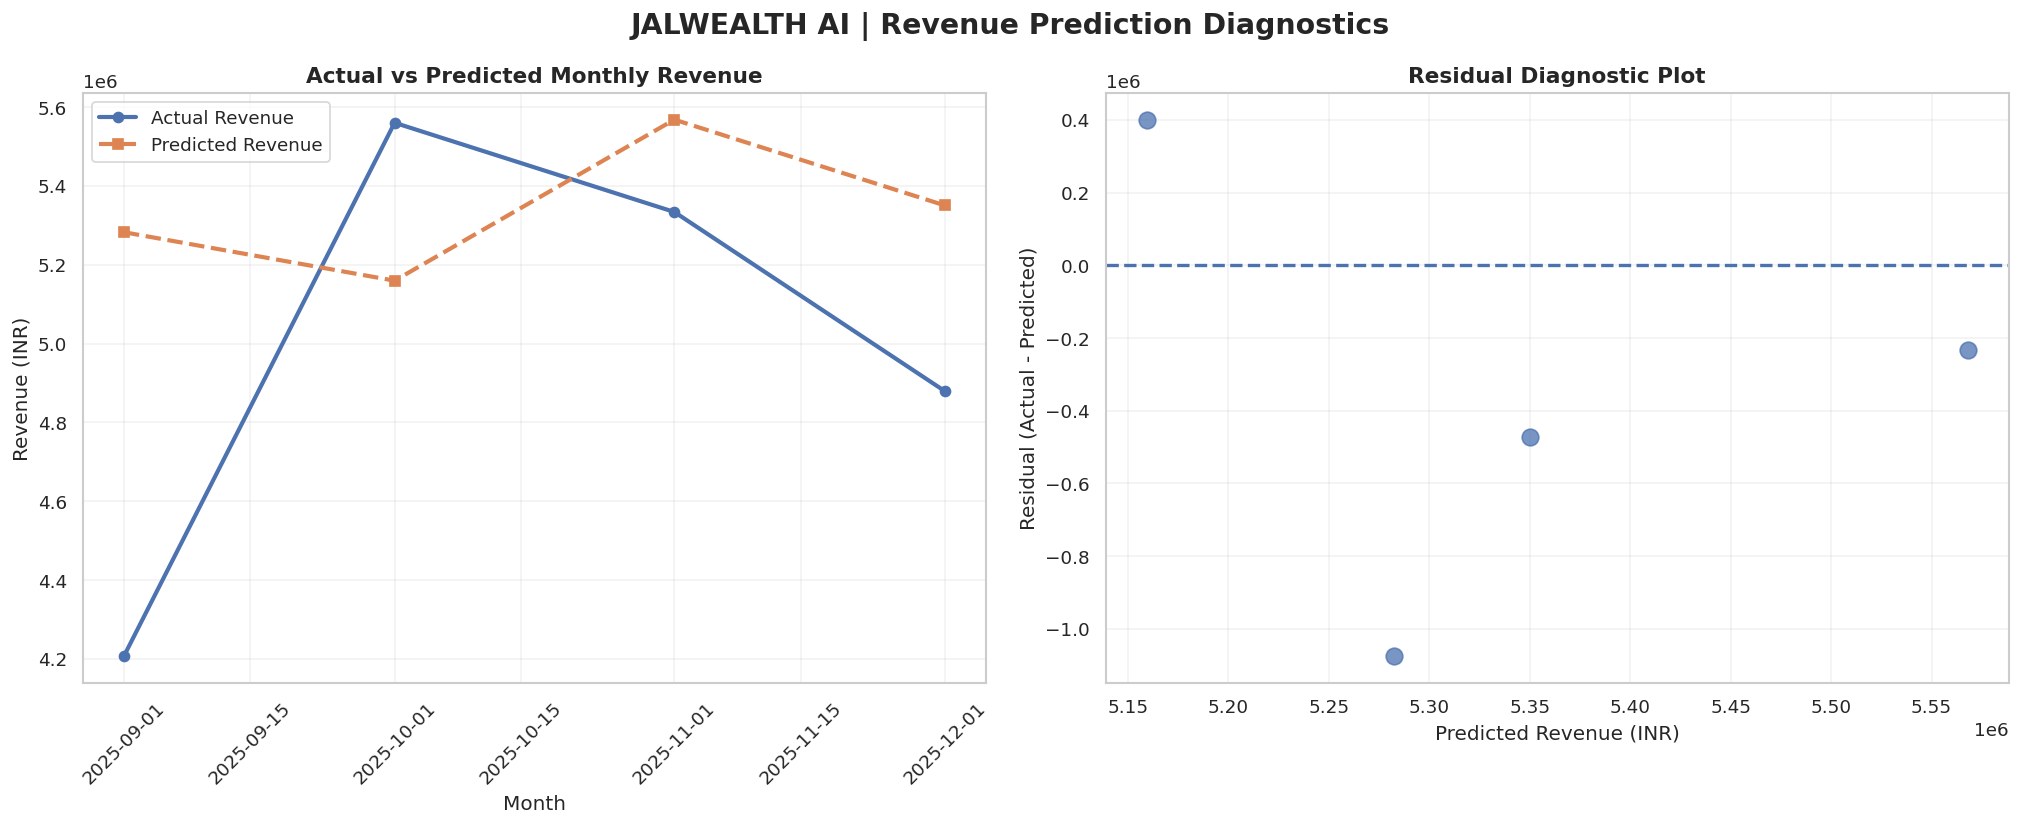


PREDICTION SUMMARY
--------------------------------------------------
Selected Model: Ridge Regression
Mean Absolute Error: ₹545,425.99
Average Absolute Prediction Error: ₹545,425.99

Prediction results exported successfully.
Visualization saved successfully.


In [53]:
# 1. Generate predictions using the selected model 
best_model = final_model 
best_predictions = best_model.predict(X_test) 
# 2. Create prediction comparison DataFrame 
prediction_results = pd.DataFrame({ 
"Month": test_dates.to_numpy(), 
"Actual_Revenue": y_test.to_numpy(), 
"Predicted_Revenue": best_predictions 
}) 
# Calculate residuals and errors 
prediction_results["Residual"] = ( 
prediction_results["Actual_Revenue"] - prediction_results["Predicted_Revenue"] 
) 
 
prediction_results["Absolute_Error"] = ( 
    prediction_results["Residual"].abs() 
) 
 
prediction_results["Percentage_Error"] = np.where( 
    prediction_results["Actual_Revenue"] != 0, 
 
    ( 
        prediction_results["Absolute_Error"] 
        / prediction_results["Actual_Revenue"] 
    ) * 100, 
 
    np.nan 
) 
 
 
# 3. Display prediction results 
print("=" * 80) 
print("JALWEALTH AI | ACTUAL VS PREDICTED REVENUE") 
print("=" * 80) 
 
print("Selected Model:", best_advanced_name) 
 
display( 
    prediction_results.style.format({ 
        "Actual_Revenue": "₹{:,.2f}", 
        "Predicted_Revenue": "₹{:,.2f}", 
        "Residual": "₹{:,.2f}", 
        "Absolute_Error": "₹{:,.2f}", 
        "Percentage_Error": "{:.2f}%" 
    }) 
) 
 
 
# 4. Create diagnostic visualizations 
fig, axes = plt.subplots( 
    1, 2, 
    figsize=(17, 7) 
) 
 
# Actual vs predicted revenue over time 
axes[0].plot( 
    prediction_results["Month"], 
    prediction_results["Actual_Revenue"], 
    marker="o", 
    linewidth=2.5, 
    label="Actual Revenue" 
) 
 
axes[0].plot( 
    prediction_results["Month"], 
    prediction_results["Predicted_Revenue"], 
    marker="s", 
    linestyle="--", 
    linewidth=2.5, 
    label="Predicted Revenue" 
) 
 
axes[0].set_title( 
    "Actual vs Predicted Monthly Revenue", 
    fontsize=13, 
    fontweight="bold" 
) 
 
axes[0].set_xlabel("Month") 
axes[0].set_ylabel("Revenue (INR)") 
axes[0].tick_params(axis="x", rotation=45) 
axes[0].legend() 
axes[0].grid(alpha=0.25) 
 
 
# Residual analysis 
axes[1].scatter( 
    prediction_results["Predicted_Revenue"], 
    prediction_results["Residual"], 
    s=100, 
    alpha=0.75 
) 
 
axes[1].axhline( 
    y=0, 
    linestyle="--", 
    linewidth=2 
) 
 
axes[1].set_title( 
    "Residual Diagnostic Plot", 
    fontsize=13, 
    fontweight="bold" 
) 
 
axes[1].set_xlabel("Predicted Revenue (INR)") 
axes[1].set_ylabel("Residual (Actual - Predicted)") 
axes[1].grid(alpha=0.25) 
 
 
plt.suptitle( 
    "JALWEALTH AI | Revenue Prediction Diagnostics", 
    fontsize=17, 
    fontweight="bold" 
) 
 
plt.tight_layout() 
 
# Save visualization 
plt.savefig( 
    CHART_DIR / "actual_vs_predicted_diagnostics.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show() 
 
 
# 5. Calculate final prediction summary 
mean_absolute_error_value = mean_absolute_error( 
    y_test, 
    best_predictions 
) 
 
print("\nPREDICTION SUMMARY") 
print("-" * 50) 
 
print(f"Selected Model: {best_advanced_name}") 
 
print( 
    f"Mean Absolute Error: " 
    f"₹{mean_absolute_error_value:,.2f}" 
) 
 
print( 
f"Average Absolute Prediction Error: " 
f"₹{prediction_results['Absolute_Error'].mean():,.2f}" 
) 
# 6. Export prediction results 
prediction_results.to_csv( 
REPORT_DIR / "Revenue_Prediction_Results.csv", 
index=False 
) 
print("\nPrediction results exported successfully.") 
print("Visualization saved successfully.")

# MACHINE LEARNING — EXECUTIVE SUMMARY

## 1. Objective 
The objective of this phase was to develop a supervised machine learning framework for 
forecasting monthly business revenue using historical sales patterns. 
## 2. Implemented Methodology
    - Historical revenue aggregation 
    - Time-based feature engineering 
    - Lag-based predictive features 
    - Chronological train-test splitting 
    -Baseline model development
    - Advanced regression model training
    - Expanding-window cross-validation
    - Model comparison and selection
    - Actual versus predicted analysis
    - Residual diagnostics 
## 3. Model Evaluation 
Models were evaluated using: 
| Metric | Purpose | 
|---|---| 
| MAE | Measures average absolute prediction error | 
| RMSE | Penalizes larger prediction errors | 
| R² | Measures explained variance | 
| MAPE | Measures average percentage error | 
## 4. Model Selection Strategy 
The advanced model with the lowest chronological cross-validation MAE was selected as the 
candidate model. 
Its performance was compared against historical mean and previous-month baseline strategies. 
## 5. Business Relevance 
Revenue forecasting can support: - Business planning - Production planning - Inventory management - Revenue monitoring - Financial decision-making - Identification of changing business trends 
## 6. Model Limitations 
The available dataset contains only 24 monthly observations. 
After lag-based feature engineering, the effective sample size becomes smaller. 
Consequently: - Performance estimates have considerable uncertainty. - The selected model may not generalize to future periods. - Additional historical data is required. - Predictions should be treated as exploratory estimates, not guaranteed business outcomes. 
## 7. Phase Conclusion 
The initial machine learning pipeline has been established. 
The next phase introduces explainable AI techniques to understand model behavior, feature 
contributions, and predictive limitations. 
Cell 47 – XAI Introduction 
Cell type: Markdown 
#  EXPLAINABLE ARTIFICIAL INTELLIGENCE (XAI) 
## 1. Why Explainable AI? 
A predictive model should not only generate predictions; it should also help stakeholders 
understand how those predictions are produced. 
Explainable AI provides techniques for interpreting model behavior. 
## 2. XAI Objectives 
1. Identify influential predictive features. 
2. Understand feature contributions. 
3. Examine prediction behavior. 
4. Improve model transparency. 
5. Support evidence-based business decisions. 
## 3. Explainability Techniques - Model-based feature importance - Permutation importance - SHAP (SHapley Additive exPlanations) - Individual prediction explanations 
## 4. Important Distinction 
Feature importance and SHAP values describe model behavior. They do not establish that a 
feature causes revenue to increase or decrease. 
## 5. Expected Outcome 
An interpretable predictive intelligence layer that connects model outputs with understandable 
business insights.

In [54]:
import importlib.util 
import warnings 
import shap 
warnings.filterwarnings("ignore") 
print("=" * 75) 
print("JALWEALTH AI | EXPLAINABLE AI ENVIRONMENT") 
print("=" * 75) 
# Check SHAP installation 
shap_available = ( 
importlib.util.find_spec("shap") is not None 
) 
if not shap_available: 
    print("SHAP is not installed.") 
    print("Install it using: %pip install shap") 

else:
    print("SHAP version:", shap.__version__) 
    
# Validate selected model 
assert "final_model" in globals(), ( 
"Run Cell 62 before executing this cell." 
) 
assert "X_train" in globals() 
assert "X_test" in globals() 
assert len(X_train) > 0 
assert len(X_test) > 0 
print("\nSelected Model:", best_advanced_name) 
print("Training observations:", len(X_train)) 
print("Testing observations:", len(X_test)) 
print("Predictive features:", len(FEATURE_COLUMNS)) 
print("\nXAI environment validation completed.")

JALWEALTH AI | EXPLAINABLE AI ENVIRONMENT
SHAP version: 0.49.1

Selected Model: Ridge Regression
Training observations: 14
Testing observations: 4
Predictive features: 10

XAI environment validation completed.


In [55]:
 # MODEL-BASED FEATURE IMPORTANCE 

JALWEALTH AI | FEATURE IMPORTANCE ANALYSIS
Selected Model: Ridge Regression
Importance Method: Absolute Linear Coefficient


,Feature,Importance,Importance_Percent
0,Revenue_Lag_6,139368.047753,23.95%
1,Month_Number,110116.417877,18.92%
2,Month_Cos,89203.569578,15.33%
3,Month_Sin,85289.316384,14.66%
4,Revenue_Lag_2,54713.611926,9.40%
5,Revenue_Lag_1,51374.929025,8.83%
6,Revenue_Rolling_Mean_6,32799.968759,5.64%
7,Revenue_Lag_3,9349.144745,1.61%
8,Revenue_Rolling_Mean_3,6834.637339,1.17%
9,Trend_Index,2927.942423,0.50%


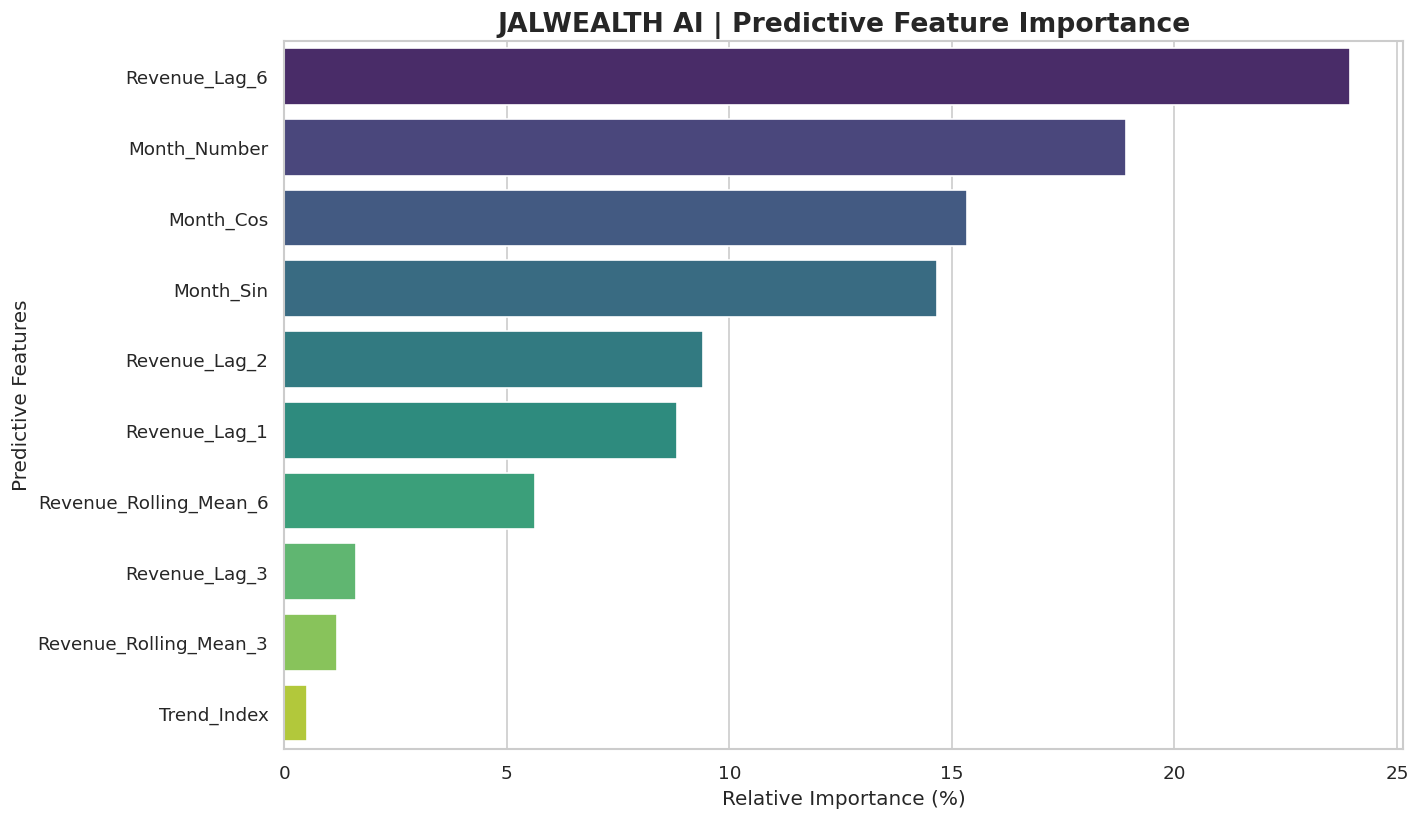


Feature importance report exported successfully.


In [56]:
# Extract the actual estimator from the pipeline 
selected_estimator = final_model.named_steps["model"] 
feature_importance = None 
importance_method = None 

# Method 1: Tree-based feature importance 
if hasattr(selected_estimator, "feature_importances_"):
    importance_values = selected_estimator.feature_importances_importance_method = "Tree-Based Feature Importance"

# Method 2: Linear model coefficients 
elif hasattr(selected_estimator, "coef_"): 
    importance_values = np.abs(np.asarray(selected_estimator.coef_).ravel()) 
    importance_method = "Absolute Linear Coefficient" 
else: 
 
    raise ValueError( 
        "Selected model does not support built-in feature importance.") 
 
 
# Create importance DataFrame 
feature_importance = pd.DataFrame({ 
 
    "Feature": FEATURE_COLUMNS, 
    "Importance": importance_values 
 
}) 
 
feature_importance = feature_importance.sort_values("Importance", ascending=False).reset_index(drop=True) 
 
 
# Normalize importance for comparison 
importance_total = feature_importance["Importance"].sum() 
 
if importance_total > 0: 
 
    feature_importance["Importance_Percent"] = ( 
        feature_importance["Importance"] 
        / importance_total 
    ) * 100 
 
else: 
 
    feature_importance["Importance_Percent"] = 0 
 
 
# Display results 
print("=" * 80) 
print("JALWEALTH AI | FEATURE IMPORTANCE ANALYSIS") 
print("=" * 80) 
 
print("Selected Model:", best_advanced_name) 
print("Importance Method:", importance_method) 
 
display( 
    feature_importance.style.format({ 
        "Importance": "{:.6f}", 
        "Importance_Percent": "{:.2f}%" 
    }) 
) 
 
 
# Visualization 
plt.figure(figsize=(12, 7)) 
 
sns.barplot( 
    data=feature_importance, 
    x="Importance_Percent", 
    y="Feature", 
    hue="Feature", 
    palette="viridis", 
    legend=False 
) 
 
plt.title( 
    "JALWEALTH AI | Predictive Feature Importance", 
    fontsize=16, 
    fontweight="bold" 
) 
 
plt.xlabel("Relative Importance (%)") 
plt.ylabel("Predictive Features") 
 
plt.tight_layout() 
 
plt.savefig( 
    CHART_DIR / "feature_importance.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show() 
 
 
# Export feature importance 
feature_importance.to_csv( 
    REPORT_DIR / "Feature_Importance_Report.csv", 
    index=False 
) 
 
print("\nFeature importance report exported successfully.")

In [57]:
# PERMUTATION FEATURE IMPORTANCE 

JALWEALTH AI | PERMUTATION FEATURE IMPORTANCE

PERMUTATION IMPORTANCE RESULTS


,Feature,Importance_Mean,Importance_Std,Interpretation
0,Month_Sin,13571.691936,23820.537967,Performance decreased after shuffling
1,Revenue_Rolling_Mean_6,7657.136136,7453.990093,Performance decreased after shuffling
2,Revenue_Rolling_Mean_3,510.885515,687.658378,Performance decreased after shuffling
3,Trend_Index,-121.055520,412.300246,No positive importance demonstrated
4,Revenue_Lag_3,-788.350256,4945.822781,No positive importance demonstrated
5,Month_Cos,-1762.240261,25064.727230,No positive importance demonstrated
6,Revenue_Lag_6,-2278.028418,32126.301007,No positive importance demonstrated
7,Month_Number,-5698.494995,19408.374596,No positive importance demonstrated
8,Revenue_Lag_2,-35722.418224,31689.480182,No positive importance demonstrated
9,Revenue_Lag_1,-50104.362223,34613.184207,No positive importance demonstrated


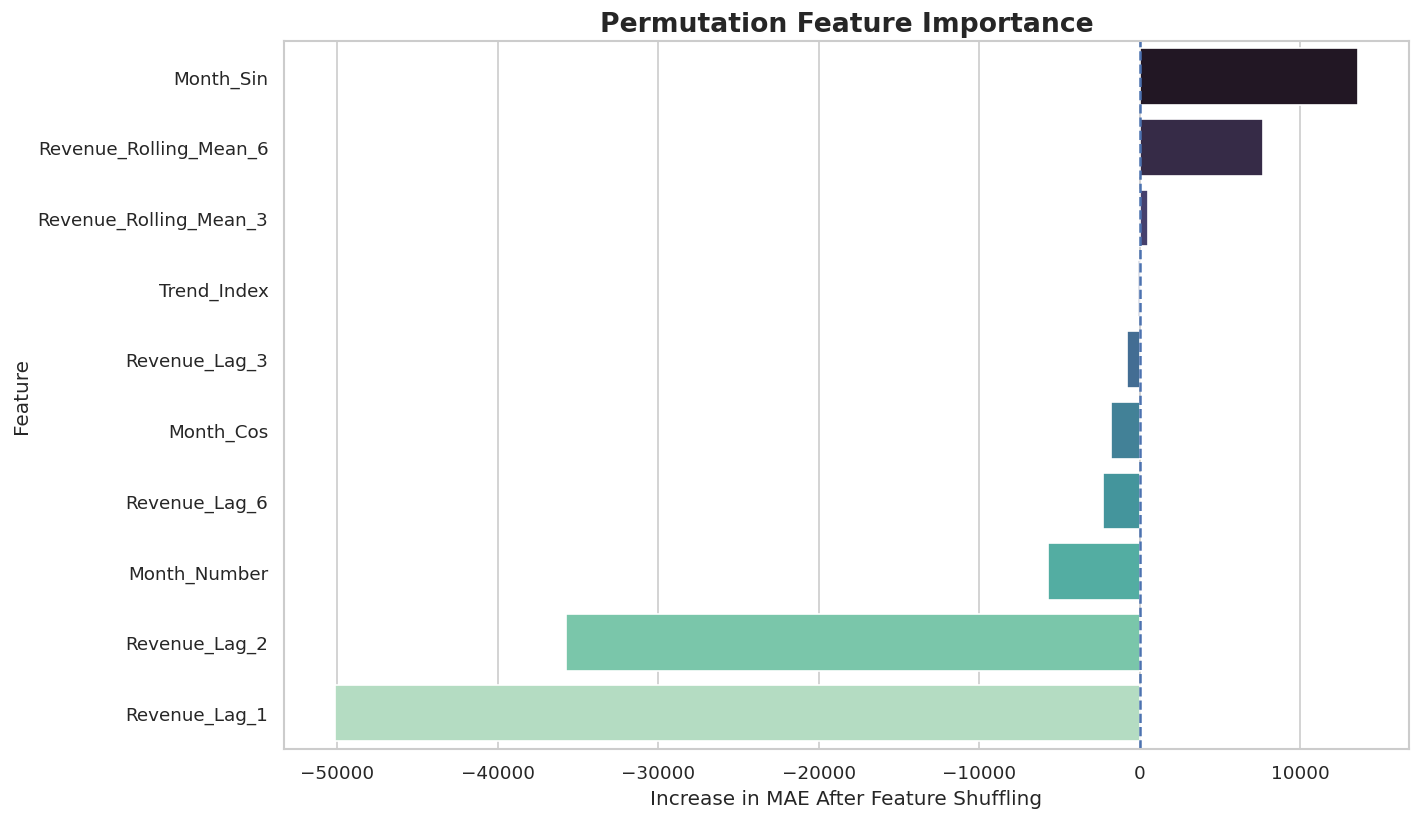


Permutation importance analysis completed.
Report exported successfully.


In [58]:
from sklearn.inspection import permutation_importance 
 
print("=" * 80) 
print("JALWEALTH AI | PERMUTATION FEATURE IMPORTANCE") 
print("=" * 80) 
 
# Calculate permutation importance on the holdout dataset 
permutation_result = permutation_importance( 
    estimator=final_model, 
    X=X_test, 
    y=y_test, 
    scoring="neg_mean_absolute_error", 
    n_repeats=30, 
    random_state=RANDOM_STATE, 
    n_jobs=-1 
) 
 
# Create importance DataFrame 
permutation_df = pd.DataFrame({ 
 
    "Feature": FEATURE_COLUMNS, 
 
    "Importance_Mean": permutation_result.importances_mean, 
 
    "Importance_Std": permutation_result.importances_std 
 
}) 
 
# Sort by mean importance 
permutation_df = permutation_df.sort_values( 
    "Importance_Mean", 
    ascending=False 
).reset_index(drop=True) 
 
# Convert negative values into an interpretation label 
permutation_df["Interpretation"] = np.where( 
    permutation_df["Importance_Mean"] > 0, 
    "Performance decreased after shuffling", 
    "No positive importance demonstrated" 
) 
 
print("\nPERMUTATION IMPORTANCE RESULTS") 
 
display( 
    permutation_df.style.format({ 
        "Importance_Mean": "{:.6f}", 
        "Importance_Std": "{:.6f}" 
    }) 
) 
 
# Visualization 
plt.figure(figsize=(12, 7)) 
 
sns.barplot( 
    data=permutation_df, 
    x="Importance_Mean", 
    y="Feature", 
    hue="Feature", 
    palette="mako", 
    legend=False 
) 
 
plt.axvline( 
    0, 
    linestyle="--", 
    linewidth=1.5 
) 
 
plt.title( 
    "Permutation Feature Importance", 
    fontsize=16, 
    fontweight="bold" 
) 
plt.xlabel("Increase in MAE After Feature Shuffling") 
plt.ylabel("Feature") 
plt.tight_layout() 
plt.savefig( 
CHART_DIR / "permutation_feature_importance.png", 
dpi=300, 
bbox_inches="tight" 
) 
plt.show() 
# Export results 
permutation_df.to_csv( 
REPORT_DIR / "Permutation_Feature_Importance.csv", 
index=False 
) 
print("\nPermutation importance analysis completed.") 
print("Report exported successfully.") 

In [59]:
# SHAP EXPLAINABILITY ANALYSIS 

In [60]:
import shap 
print("=" * 80) 
print("JALWEALTH AI | SHAP EXPLAINABILITY ENGINE") 
print("=" * 80) 
# Use the fitted preprocessing and estimator separately 
selected_estimator = final_model.named_steps["model"] 
 
# Transform data if the selected pipeline contains a scaler 
scaler = final_model.named_steps["scaler"] 
 
if scaler == "passthrough": 
    X_train_transformed = X_train.copy() 
    X_test_transformed = X_test.copy() 
else: 
    X_train_transformed = pd.DataFrame( 
        scaler.transform(X_train), 
        columns=FEATURE_COLUMNS, 
        index=X_train.index 
    ) 
 
    X_test_transformed = pd.DataFrame( 
        scaler.transform(X_test), 
        columns=FEATURE_COLUMNS, 
        index=X_test.index 
    ) 
 
# Use a small background dataset because the history is limited 
background = X_train_transformed.copy() 
 
# Select SHAP explainer according to model type 
if hasattr(selected_estimator, "feature_importances_"): 
 
    shap_explainer = shap.TreeExplainer( 
        selected_estimator, 
        data=background, 
        feature_perturbation="interventional" 
    ) 
 
    shap_values = shap_explainer( 
        X_test_transformed 
    ) 
 
else: 
 
    shap_explainer = shap.Explainer( 
        selected_estimator.predict, 
        background 
    ) 
 
    shap_values = shap_explainer( 
X_test_transformed 
) 
print("\nSHAP explainer created successfully.") 
print("Selected model:", best_advanced_name) 
print("Background observations:", len(background)) 
print("Explained observations:", len(X_test_transformed)) 
print("Number of features:", len(FEATURE_COLUMNS)) 
print("\nSHAP values calculated successfully.")

JALWEALTH AI | SHAP EXPLAINABILITY ENGINE


ExactExplainer explainer: 5it [00:17,  4.49s/it]                                                                       


SHAP explainer created successfully.
Selected model: Ridge Regression
Background observations: 14
Explained observations: 4
Number of features: 10

SHAP values calculated successfully.


In [61]:
# SHAP GLOBAL FEATURE IMPORTANCE

JALWEALTH AI | SHAP GLOBAL IMPORTANCE


,Feature,Mean_Absolute_SHAP,Relative_Importance_Percent
0,Month_Number,"131,879.4556",23.92%
1,Revenue_Lag_6,"96,715.9289",17.54%
2,Month_Cos,"87,769.0119",15.92%
3,Revenue_Lag_1,"73,720.2252",13.37%
4,Month_Sin,"66,093.6642",11.99%
5,Revenue_Lag_2,"62,917.5197",11.41%
6,Revenue_Rolling_Mean_6,"12,117.5864",2.20%
7,Revenue_Lag_3,"9,143.6627",1.66%
8,Trend_Index,"6,536.9981",1.19%
9,Revenue_Rolling_Mean_3,"4,353.4973",0.79%


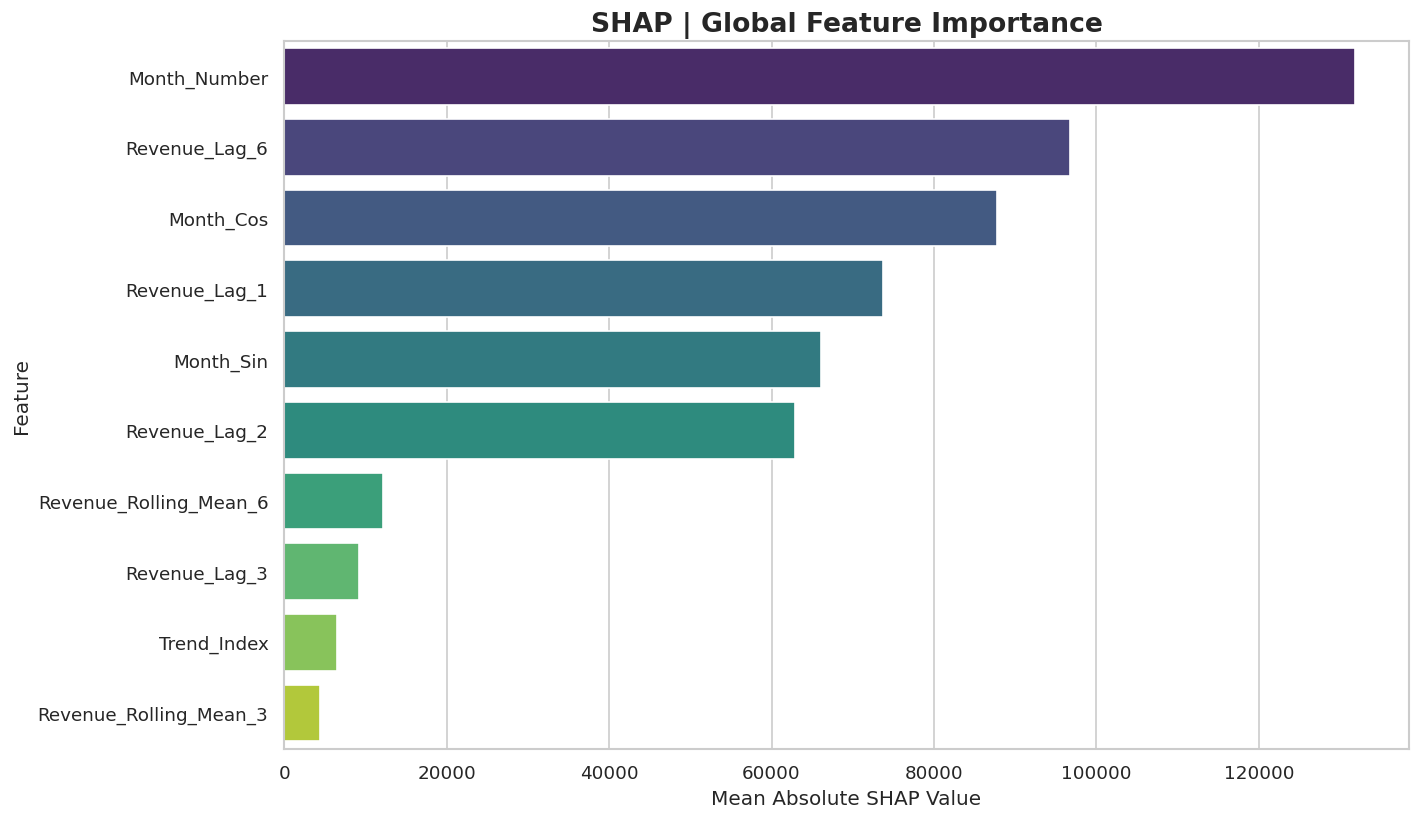


SHAP global importance report exported.


In [62]:
# Extract SHAP values 
shap_array = np.asarray(shap_values.values) 
# Global importance = mean absolute SHAP value 
mean_absolute_shap = np.abs(shap_array).mean(axis=0) 
shap_global_importance = pd.DataFrame({ 
"Feature": FEATURE_COLUMNS, 
"Mean_Absolute_SHAP": mean_absolute_shap 
}) 
shap_global_importance = ( 
shap_global_importance 
.sort_values("Mean_Absolute_SHAP", ascending=False) 
.reset_index(drop=True) 
) 
# Calculate relative contribution percentage 
total_shap = shap_global_importance[ 
    "Mean_Absolute_SHAP" 
].sum() 
 
if total_shap > 0: 
 
    shap_global_importance["Relative_Importance_Percent"] = ( 
        shap_global_importance["Mean_Absolute_SHAP"] 
        / total_shap 
    ) * 100 
 
else: 
 
    shap_global_importance["Relative_Importance_Percent"] = 0 
 
 
print("=" * 80) 
print("JALWEALTH AI | SHAP GLOBAL IMPORTANCE") 
print("=" * 80) 
 
display( 
    shap_global_importance.style.format({ 
        "Mean_Absolute_SHAP": "{:,.4f}", 
        "Relative_Importance_Percent": "{:.2f}%" 
    }) 
) 
 
# Visualization 
plt.figure(figsize=(12, 7)) 
 
sns.barplot( 
    data=shap_global_importance, 
    x="Mean_Absolute_SHAP", 
    y="Feature", 
    hue="Feature", 
    palette="viridis", 
    legend=False 
) 
 
plt.title( 
    "SHAP | Global Feature Importance", 
    fontsize=16, 
    fontweight="bold" 
) 
plt.xlabel("Mean Absolute SHAP Value") 
plt.ylabel("Feature") 
plt.tight_layout() 
plt.savefig( 
CHART_DIR / "shap_global_importance.png", 
dpi=300, 
bbox_inches="tight" 
) 
plt.show() 
# Export report 
shap_global_importance.to_csv( 
REPORT_DIR / "SHAP_Global_Importance.csv", 
index=False 
) 
print("\nSHAP global importance report exported.")

In [63]:
# SHAP SUMMARY PLOT 

JALWEALTH AI | SHAP SUMMARY ANALYSIS


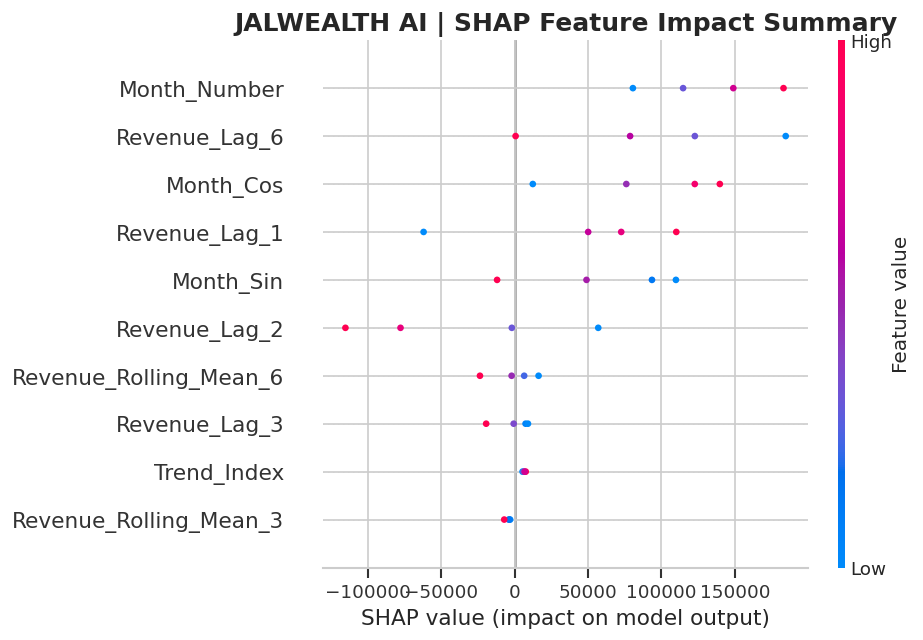

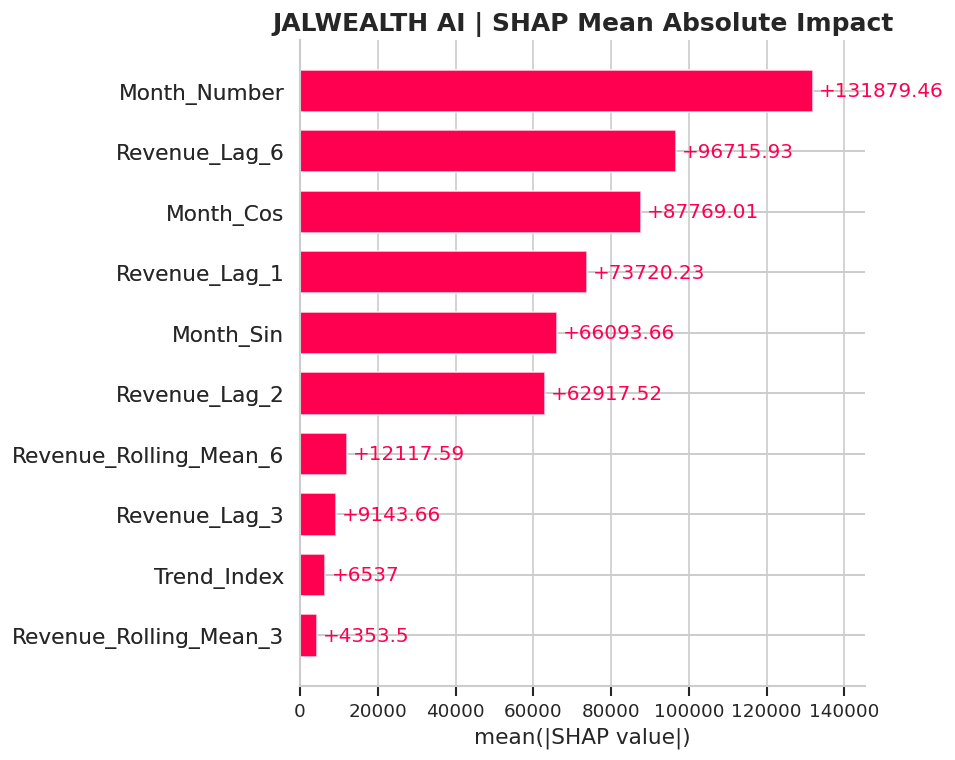


SHAP summary visualizations generated successfully.
Saved:
- shap_summary_beeswarm.png
- shap_summary_bar.png


In [64]:
print("=" * 80) 
print("JALWEALTH AI | SHAP SUMMARY ANALYSIS") 
print("=" * 80) 
# Convert SHAP values into a compatible Explanation object 
shap_explanation = shap.Explanation( 
values=shap_array, 
    base_values=np.asarray( 
        shap_values.base_values 
    ).reshape(-1), 
 
    data=X_test_transformed.to_numpy(), 
 
    feature_names=FEATURE_COLUMNS 
) 
 
# SHAP beeswarm summary plot 
plt.figure(figsize=(12, 8)) 
 
shap.plots.beeswarm( 
    shap_explanation, 
    max_display=len(FEATURE_COLUMNS), 
    show=False 
) 
 
plt.title( 
    "JALWEALTH AI | SHAP Feature Impact Summary", 
    fontsize=15, 
    fontweight="bold" 
) 
 
plt.tight_layout() 
 
plt.savefig( 
    CHART_DIR / "shap_summary_beeswarm.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show() 
 
 
# SHAP bar summary plot 
plt.figure(figsize=(12, 7)) 
 
shap.plots.bar( 
    shap_explanation, 
    max_display=len(FEATURE_COLUMNS), 
    show=False 
) 
 
plt.title( 
"JALWEALTH AI | SHAP Mean Absolute Impact", 
fontsize=15, 
fontweight="bold" 
) 
plt.tight_layout() 
plt.savefig( 
CHART_DIR / "shap_summary_bar.png", 
dpi=300, 
bbox_inches="tight" 
) 
plt.show() 
print("\nSHAP summary visualizations generated successfully.") 
print("Saved:") 
print("- shap_summary_beeswarm.png") 
print("- shap_summary_bar.png")

In [65]:
# INDIVIDUAL SHAP WATERFALL EXPLANATION 

JALWEALTH AI | INDIVIDUAL PREDICTION EXPLANATION
Selected Model: Ridge Regression
Observation Month: 2025-09-01 00:00:00

Actual Revenue: ₹4,206,898.08
Predicted Revenue: ₹5,282,333.18
SHAP Base Value: ₹4,954,405.12
Prediction Difference: ₹327,928.06


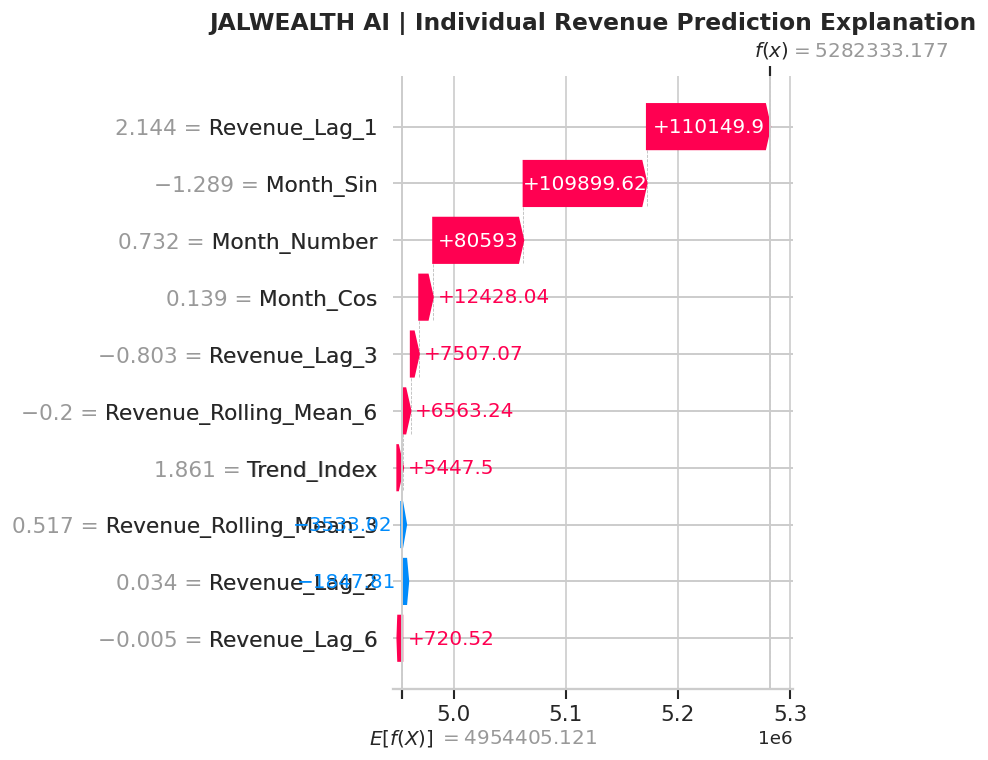

,Feature,Feature_Value,SHAP_Contribution,Impact_Direction
0,Revenue_Lag_1,2.1440,"₹110,149.9022",Increases Prediction
1,Month_Sin,-1.2886,"₹109,899.6182",Increases Prediction
2,Month_Number,0.7319,"₹80,593.0006",Increases Prediction
3,Month_Cos,0.1393,"₹12,428.0377",Increases Prediction
4,Revenue_Lag_3,-0.8030,"₹7,507.0723",Increases Prediction
5,Revenue_Rolling_Mean_6,-0.2001,"₹6,563.2361",Increases Prediction
6,Trend_Index,1.8605,"₹5,447.4984",Increases Prediction
7,Revenue_Rolling_Mean_3,0.5169,"₹-3,533.0207",Decreases Prediction
8,Revenue_Lag_2,0.0338,"₹-1,847.8142",Decreases Prediction
9,Revenue_Lag_6,-0.0052,₹720.5248,Increases Prediction



Individual SHAP explanation exported successfully.


In [66]:
print("=" * 80) 
print("JALWEALTH AI | INDIVIDUAL PREDICTION EXPLANATION") 
print("=" * 80) 
# Select the first holdout observation for explanation 
observation_index = 0 
# Retrieve its SHAP explanation 
individual_explanation = shap_explanation[ 
    observation_index 
] 
 
# Actual and predicted revenue 
actual_revenue = float( 
    y_test.iloc[observation_index] 
) 
 
predicted_revenue = float( 
    best_predictions[observation_index] 
) 
 
# Extract base value 
base_value = float( 
    np.asarray(individual_explanation.base_values) 
) 
 
print("Selected Model:", best_advanced_name) 
print("Observation Month:", test_dates.iloc[observation_index]) 
 
print(f"\nActual Revenue: ₹{actual_revenue:,.2f}") 
print(f"Predicted Revenue: ₹{predicted_revenue:,.2f}") 
print(f"SHAP Base Value: ₹{base_value:,.2f}") 
 
print( 
    f"Prediction Difference: " 
    f"₹{predicted_revenue - base_value:,.2f}" 
) 
 
 
# Generate waterfall visualization 
plt.figure(figsize=(12, 8)) 
 
shap.plots.waterfall( 
    individual_explanation, 
    max_display=len(FEATURE_COLUMNS), 
    show=False 
) 
 
plt.title( 
    "JALWEALTH AI | Individual Revenue Prediction Explanation", 
    fontsize=14, 
    fontweight="bold" 
) 
 
plt.tight_layout() 
 
plt.savefig( 
    CHART_DIR / "shap_individual_waterfall.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show() 
 
 
# Export individual feature contributions 
individual_shap_report = pd.DataFrame({ 
 
    "Feature": FEATURE_COLUMNS, 
 
    "Feature_Value": X_test_transformed.iloc[ 
        observation_index 
    ].to_numpy(), 
 
    "SHAP_Contribution": shap_array[ 
        observation_index 
    ] 
 
}) 
 
individual_shap_report["Impact_Direction"] = np.where( 
    individual_shap_report["SHAP_Contribution"] > 0, 
    "Increases Prediction", 
    np.where( 
        individual_shap_report["SHAP_Contribution"] < 0, 
        "Decreases Prediction", 
        "No Contribution" 
    ) 
) 
 
individual_shap_report = ( 
    individual_shap_report 
    .sort_values( 
        "SHAP_Contribution", 
        key=lambda values: values.abs(), 
        ascending=False 
    ) 
    .reset_index(drop=True) 
) 
 
display( 
    individual_shap_report.style.format({ 
        "Feature_Value": "{:,.4f}", 
        "SHAP_Contribution": "₹{:,.4f}" 
    }) 
) 
 
individual_shap_report.to_csv( 
    REPORT_DIR / "SHAP_Individual_Explanation.csv", 
    index=False 
) 
 
print("\nIndividual SHAP explanation exported successfully.")

In [67]:
# SHAP DEPENDENCE ANALYSIS 

JALWEALTH AI | SHAP DEPENDENCE ANALYSIS
Features selected for dependence analysis:
1. Month_Number
2. Revenue_Lag_6
3. Month_Cos
4. Revenue_Lag_1


<Figure size 1200x720 with 0 Axes>

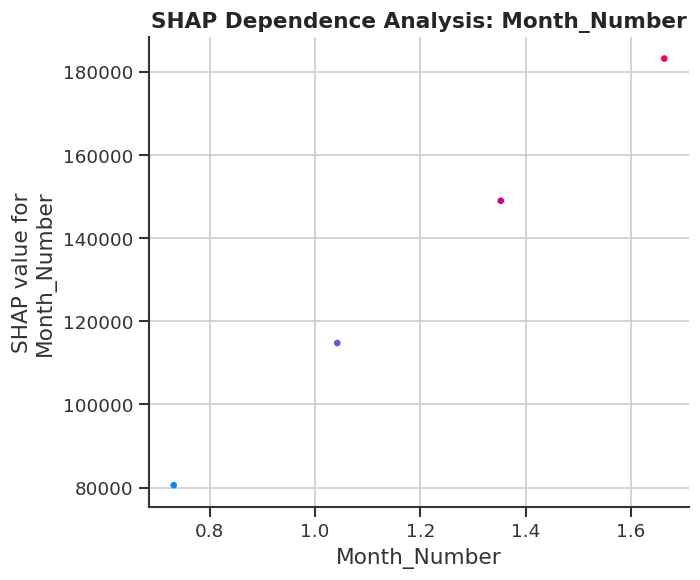

<Figure size 1200x720 with 0 Axes>

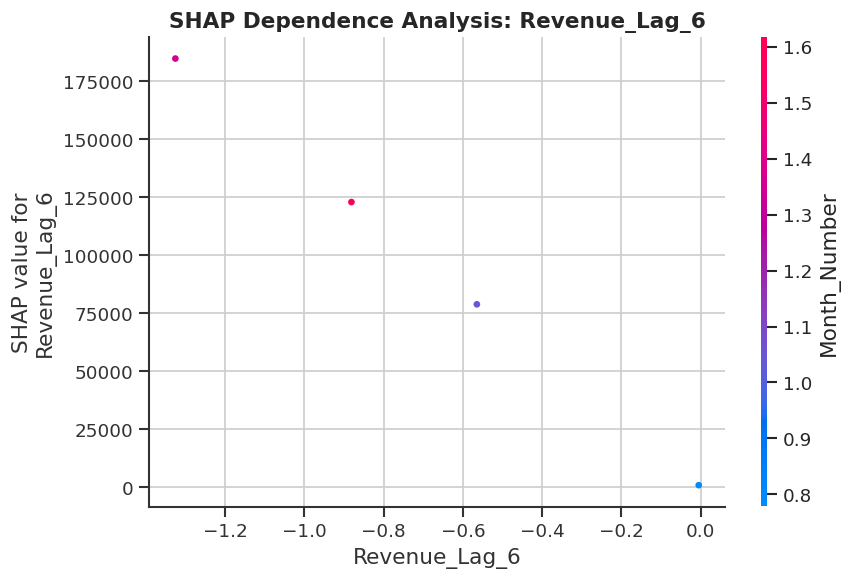

<Figure size 1200x720 with 0 Axes>

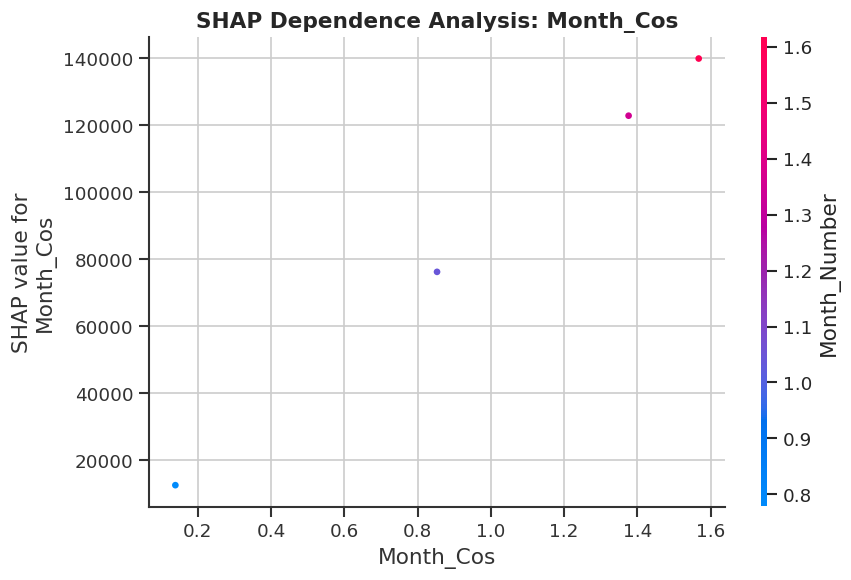

<Figure size 1200x720 with 0 Axes>

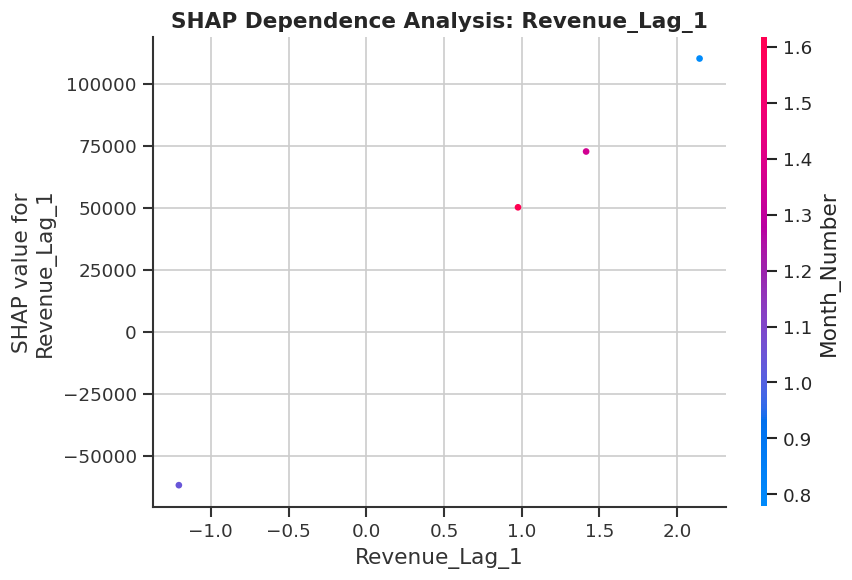

,Feature,Mean_Feature_Value,Mean_SHAP_Contribution,Mean_Absolute_SHAP,Minimum_SHAP,Maximum_SHAP
0,Month_Number,1.1976,"131,879.4556","131,879.4556","80,593.0006","183,165.9106"
1,Revenue_Lag_6,-0.6940,"96,715.9289","96,715.9289",720.5248,"184,665.7317"
2,Month_Cos,0.9839,"87,769.0119","87,769.0119","12,428.0377","139,799.4076"
3,Revenue_Lag_1,0.8322,"42,752.3531","73,720.2252","-61,935.7441","110,149.9022"



SHAP dependence analysis completed.
Charts saved in: C:\Users\User\JALWEALTH_AI_Outputs\Charts
Summary saved in: C:\Users\User\JALWEALTH_AI_Outputs\Reports


In [68]:
print("=" * 80) 
print("JALWEALTH AI | SHAP DEPENDENCE ANALYSIS") 
print("=" * 80) 
 
# Identify the most influential features 
top_features = ( 
    shap_global_importance 
    .sort_values("Mean_Absolute_SHAP", ascending=False) 
    ["Feature"] 
    .head(min(4, len(FEATURE_COLUMNS))) 
    .tolist() 
) 
 
print("Features selected for dependence analysis:") 
for rank, feature in enumerate(top_features, start=1): 
    print(f"{rank}. {feature}") 
 
 
# Generate individual dependence plots 
dependence_records = [] 
 
for feature in top_features: 
 
    feature_index = FEATURE_COLUMNS.index(feature) 
 
    feature_values = X_test_transformed[feature].to_numpy() 
 
    feature_shap_values = shap_array[:, feature_index] 
 
    dependence_records.append({ 
 
        "Feature": feature, 
 
        "Mean_Feature_Value": np.mean(feature_values), 
 
        "Mean_SHAP_Contribution": np.mean(feature_shap_values), 
 
        "Mean_Absolute_SHAP": np.mean( 
            np.abs(feature_shap_values) 
        ), 
 
        "Minimum_SHAP": np.min(feature_shap_values), 
 
        "Maximum_SHAP": np.max(feature_shap_values) 
 
    }) 
 
    plt.figure(figsize=(10, 6)) 
 
    shap.dependence_plot( 
        feature, 
        shap_array, 
        X_test_transformed, 
        interaction_index="auto", 
        show=False 
    ) 
 
    plt.title( 
        f"SHAP Dependence Analysis: {feature}", 
        fontsize=13, 
        fontweight="bold" 
    ) 
 
    plt.tight_layout() 
 
    safe_feature_name = ( 
        feature.replace("/", "_") 
        .replace(" ", "_") 
    ) 
 
    plt.savefig( 
        CHART_DIR / f"shap_dependence_{safe_feature_name}.png", 
        dpi=300, 
        bbox_inches="tight" 
    ) 
 
    plt.show() 
 
 
# Create dependence analysis summary 
dependence_summary = pd.DataFrame(dependence_records) 
 
display( 
    dependence_summary.style.format({ 
        "Mean_Feature_Value": "{:,.4f}", 
        "Mean_SHAP_Contribution": "{:,.4f}", 
        "Mean_Absolute_SHAP": "{:,.4f}", 
        "Minimum_SHAP": "{:,.4f}", 
        "Maximum_SHAP": "{:,.4f}" 
    }) 
) 
 
dependence_summary.to_csv( 
    REPORT_DIR / "SHAP_Dependence_Summary.csv", 
    index=False 
) 
 
print("\nSHAP dependence analysis completed.") 
print("Charts saved in:", CHART_DIR) 
print("Summary saved in:", REPORT_DIR)

# MODEL EXPLAINABILITY & BUSINESS INSIGHTS REPORT

In [69]:
print("=" * 85) 
print("JALWEALTH AI | MODEL EXPLAINABILITY & BUSINESS INSIGHTS") 
print("=" * 85) 

# ------------------------------------------------------------ 
# 1. Validate explainability results 
# ------------------------------------------------------------ 
if shap_global_importance.empty: 
    raise ValueError("SHAP global importance report is empty.") 
if "Feature" not in shap_global_importance.columns: 
    raise KeyError("Feature column is missing from SHAP importance.") 
if "Mean_Absolute_SHAP" not in shap_global_importance.columns: 
    raise KeyError("Mean_Absolute_SHAP column is missing.")
    
# ------------------------------------------------------------ 
# 2. Rank features by global importance 
# ------------------------------------------------------------ 
business_feature_ranking = ( 
shap_global_importance .sort_values( "Mean_Absolute_SHAP",ascending=False).reset_index(drop=True) ) 
 
business_feature_ranking["Importance_Rank"] = (np.arange(1, len(business_feature_ranking) + 1)) 
 
business_feature_ranking["Business_Interpretation"] = (business_feature_ranking["Feature"].map({ 
 
        "Revenue_Lag_1": 
            "Previous month's revenue may provide a useful short-term signal.", 
 
        "Revenue_Lag_2": 
            "Revenue from two months earlier may capture recent business momentum.", 
 
        "Revenue_Lag_3": 
            "Revenue from three months earlier may capture medium-term patterns.", 
 
        "Revenue_Lag_6": 
            "Revenue from six months earlier may reflect longer-term patterns.", 
 
        "Rolling_Mean_3": 
            "Three-month average revenue may help identify recent business trends.", 
 
        "Rolling_Mean_6": 
            "Six-month average revenue may help identify broader revenue trends.", 
 
        "Month_Number": 
            "Calendar month may capture recurring seasonal patterns.", 
 
        "Trend_Index": 
            "Time progression may capture long-term changes in revenue.", 
 
        "Month_Sin": 
            "Seasonal cyclical position may contribute to the prediction.", 
 
        "Month_Cos": 
            "Seasonal cyclical position may contribute to the prediction." 
 
    }).fillna( 
        "This feature contributes to the model's revenue prediction." 
    ) 
) 
 
# ------------------------------------------------------------ 
# 3. Identify the strongest model drivers 
# ------------------------------------------------------------ 
 
top_business_drivers = business_feature_ranking.head(5) 
 
print("\nTOP FIVE MODEL DRIVERS") 
print("-" * 85) 
 
for _, row in top_business_drivers.iterrows(): 
 
    print( 
        f"{int(row['Importance_Rank'])}. " 
        f"{row['Feature']} | " 
        f"Mean Absolute SHAP: " 
        f"{row['Mean_Absolute_SHAP']:.4f}" 
    ) 
 
    print( 
        "   Interpretation:", 
        row["Business_Interpretation"] 
    ) 
 
# ------------------------------------------------------------ 
# 4. Calculate positive and negative SHAP patterns 
# ------------------------------------------------------------ 
 
directional_insights = [] 
 
for feature in FEATURE_COLUMNS: 
 
    feature_index = FEATURE_COLUMNS.index(feature) 
 
    contributions = shap_array[:, feature_index] 
 
    directional_insights.append({ 
 
        "Feature": feature, 
 
        "Positive_Contribution_Count": int( 
            np.sum(contributions > 0) 
        ), 
 
        "Negative_Contribution_Count": int( 
            np.sum(contributions < 0) 
        ), 
 
        "Average_SHAP_Contribution": float( 
            np.mean(contributions) 
        ), 
 
        "Mean_Absolute_SHAP": float( 
            np.mean(np.abs(contributions)) 
        ) 
 
    }) 
 
directional_insights_df = ( 
    pd.DataFrame(directional_insights) 
    .sort_values( 
        "Mean_Absolute_SHAP", 
        ascending=False 
    ) 
    .reset_index(drop=True) 
) 
 
# ------------------------------------------------------------ 
# 5. Generate evidence-based business observations 
# ------------------------------------------------------------ 
 
print("\nBUSINESS OBSERVATIONS") 
print("-" * 85) 
 
for _, row in top_business_drivers.iterrows(): 
 
    print( 
        f"• {row['Feature']}: " 
        f"{row['Business_Interpretation']}" 
    ) 
 
# ------------------------------------------------------------ 
# 6. Export explainability reports 
# ------------------------------------------------------------ 
 
business_feature_ranking.to_csv( 
    REPORT_DIR / "SHAP_Business_Feature_Ranking.csv", 
    index=False 
) 
 
directional_insights_df.to_csv( 
    REPORT_DIR / "SHAP_Directional_Insights.csv", 
    index=False 
) 
 
# ------------------------------------------------------------ 
# 7. Final report summary 
# ------------------------------------------------------------ 
 
print("\n" + "=" * 85) 
print("EXPLAINABILITY REPORT SUMMARY") 
print("=" * 85) 
 
print("Selected Model:", best_advanced_name) 
 
print( 
    "Total Features Explained:", 
    len(FEATURE_COLUMNS) 
) 
 
print( 
    "Top Influential Feature:", 
    business_feature_ranking.iloc[0]["Feature"] 
) 
 
print( 
    "Reports saved in:", 
    REPORT_DIR 
) 
 
print("\nExplainability analysis completed successfully.")

JALWEALTH AI | MODEL EXPLAINABILITY & BUSINESS INSIGHTS

TOP FIVE MODEL DRIVERS
-------------------------------------------------------------------------------------
1. Month_Number | Mean Absolute SHAP: 131879.4556
   Interpretation: Calendar month may capture recurring seasonal patterns.
2. Revenue_Lag_6 | Mean Absolute SHAP: 96715.9289
   Interpretation: Revenue from six months earlier may reflect longer-term patterns.
3. Month_Cos | Mean Absolute SHAP: 87769.0119
   Interpretation: Seasonal cyclical position may contribute to the prediction.
4. Revenue_Lag_1 | Mean Absolute SHAP: 73720.2252
   Interpretation: Previous month's revenue may provide a useful short-term signal.
5. Month_Sin | Mean Absolute SHAP: 66093.6642
   Interpretation: Seasonal cyclical position may contribute to the prediction.

BUSINESS OBSERVATIONS
-------------------------------------------------------------------------------------
• Month_Number: Calendar month may capture recurring seasonal patterns.
• Reven

In [70]:
 # 2026 REVENUE FORECASTING & SCENARIO ANALYSIS

## 1. Phase Objective 
The objective of this phase is to develop a structured revenue forecasting framework for the 
year 2026 using historical monthly business performance. 
The selected machine learning model from Phase 5 will be used to generate future revenue 
estimates. 
    
## 2. Forecasting Scope 
The forecasting framework will focus on:
- Monthly revenue projections for January–December 2026.
- Historical revenue trend analysis.
- Seasonal pattern representation.
- Lag-based revenue signals.
- Rolling average indicators.
- Business growth and downside scenarios. 
    
## 3. Forecasting Methodology 
The forecasting workflow will follow these steps: 
1. Prepare the latest historical monthly revenue observations. 
2. Construct future calendar and trend features. 
3. Generate lag and rolling-average features. 
4. Apply the selected trained forecasting model. 
5. Forecast each future month sequentially. 
6. Update lag features using previously generated predictions. 
7. Build alternative business scenarios. 
8. Visualize and export the forecasting results. 
## 4. Scenario Analysis 
Three illustrative business scenarios will be evaluated: 
| Scenario | Assumption | 
|---|---| 
| Conservative | 5% lower than baseline forecast | 
| Baseline | Model-generated forecast | 
| Optimistic | 5% higher than baseline forecast | 
These scenario adjustments are planning assumptions, not statistically validated prediction 
intervals. 
    
## 5. Important Forecasting Considerations
- The historical dataset contains only 24 monthly observations.
- Forecasts beyond the observed period involve additional uncertainty.
- Recursive forecasting can accumulate prediction errors.
- Scenario adjustments are not substitutes for retraining with new business data.
- Forecasts should be treated as decision-support estimates rather than guaranteed revenue.
    
## 6. Expected Deliverables 
- Monthly 2026 revenue forecast.
- Forecasting comparison chart. 
- Conservative, baseline, and optimistic scenarios.
- Annual revenue projections.
- Forecast output CSV files.
- Business interpretation and limitations report. 
    
**Phase 7 Goal:** Transform historical business data into forward-looking revenue estimates 
that can support strategic planning and operational decisions.

In [71]:
 # HISTORICAL DATA PREPARATION & MODEL VALIDATION 

In [72]:
print("=" * 85) 
print("JALWEALTH AI | 2026 FORECASTING - DATA VALIDATION") 
print("=" * 85) 
# ------------------------------------------------------------ 
# 1. Validate required variables 
# ------------------------------------------------------------ 
required_variables = [ 
"eda_df", 
"final_model", 
"best_advanced_name", 
"FEATURE_COLUMNS", 
"FORECAST_FEATURES" 
] 
missing_variables = [ 
    variable 
    for variable in required_variables 
    if variable not in globals() 
] 
 
if missing_variables: 
    raise NameError( 
        f"Required variables are missing: {missing_variables}" 
    ) 
 
# ------------------------------------------------------------ 
# 2. Validate source columns 
# ------------------------------------------------------------ 
 
required_columns = [ 
    "Order Date", 
    "Revenue (INR)" 
] 
 
missing_columns = [ 
    column 
    for column in required_columns 
    if column not in eda_df.columns 
] 
 
if missing_columns: 
    raise KeyError( 
        f"Required source columns are missing: {missing_columns}" 
    ) 
 
# ------------------------------------------------------------ 
# 3. Reconstruct historical monthly revenue 
# ------------------------------------------------------------ 
 
forecast_history = eda_df[ 
    ["Order Date", "Revenue (INR)"] 
].copy() 
 
forecast_history["Order Date"] = pd.to_datetime( 
    forecast_history["Order Date"], 
    errors="coerce" 
) 
 
forecast_history["Revenue (INR)"] = pd.to_numeric( 
    forecast_history["Revenue (INR)"], 
    errors="coerce" 
) 
 
forecast_history = forecast_history.dropna( 
    subset=["Order Date", "Revenue (INR)"] 
) 
 
forecast_history["Month"] = ( 
    forecast_history["Order Date"] 
    .dt.to_period("M") 
    .dt.to_timestamp() 
) 
 
monthly_revenue_history = ( 
    forecast_history 
    .groupby("Month")["Revenue (INR)"] 
    .sum() 
    .sort_index() 
    .asfreq("MS") 
) 
 
# Validate continuous monthly history 
if monthly_revenue_history.isna().any(): 
    missing_months = monthly_revenue_history[ 
        monthly_revenue_history.isna() 
    ].index.strftime("%Y-%m").tolist() 
 
    raise ValueError( 
        "Missing monthly revenue observations detected: " 
        f"{missing_months}. Investigate the source data before forecasting." 
    ) 
 
if len(monthly_revenue_history) < 12: 
    raise ValueError( 
        "At least 12 complete monthly observations are required " 
        "for this forecasting workflow." 
    ) 
 
if not np.isfinite(monthly_revenue_history.to_numpy()).all(): 
    raise ValueError( 
        "Historical revenue contains non-finite values." 
    ) 
 
# ------------------------------------------------------------ 
# 4. Validate chronological coverage 
# ------------------------------------------------------------ 
 
history_start = monthly_revenue_history.index.min() 
history_end = monthly_revenue_history.index.max() 
 
print("\nHISTORICAL DATA COVERAGE") 
print("-" * 85) 
 
print("First Month:", history_start.strftime("%B %Y")) 
print("Last Month:", history_end.strftime("%B %Y")) 
print("Total Monthly Observations:", len(monthly_revenue_history)) 
 
print( 
    "Historical Revenue Total: " 
    f"₹{monthly_revenue_history.sum():,.2f}" 
) 
 
print( 
    "Average Monthly Revenue: " 
    f"₹{monthly_revenue_history.mean():,.2f}" 
) 
 
# ------------------------------------------------------------ 
# 5. Validate forecast horizon 
# ------------------------------------------------------------ 
 
forecast_start = pd.Timestamp("2026-01-01") 
forecast_end = pd.Timestamp("2026-12-01") 
 
if history_end >= forecast_start: 
    raise ValueError( 
        "Historical data already contains January 2026 or later. " 
        "Review the forecast horizon before proceeding." 
    ) 
 
forecast_dates = pd.date_range( 
    start=forecast_start, 
    end=forecast_end, 
    freq="MS" 
) 
 
print("\nFORECAST HORIZON") 
print("-" * 85) 
 
print("Forecast Start:", forecast_dates[0].strftime("%B %Y")) 
print("Forecast End:", forecast_dates[-1].strftime("%B %Y")) 
print("Forecast Months:", len(forecast_dates)) 
 
# ------------------------------------------------------------ 
# 6. Validate trained model and feature compatibility 
# ------------------------------------------------------------ 
 
if not hasattr(final_model, "predict"): 
    raise TypeError( 
        "The selected forecasting model does not support predict()." 
    ) 
 
if list(FEATURE_COLUMNS) != list(FORECAST_FEATURES): 
    raise ValueError( 
        "FEATURE_COLUMNS and FORECAST_FEATURES do not match. " 
        "The training and forecasting feature definitions must be identical." 
    ) 
 
if not hasattr(final_model, "feature_names_in_"): 
    print( 
        "\nNote: Model does not expose feature_names_in_. " 
        "Feature compatibility will be validated during prediction." 
    ) 
 
else: 
    trained_feature_names = list( 
        final_model.feature_names_in_ 
    ) 
 
    if trained_feature_names != list(FEATURE_COLUMNS): 
        raise ValueError( 
            "Forecasting feature order differs from model training order." 
        ) 
 
# ------------------------------------------------------------ 
# 7. Validate required lag and rolling history 
# ------------------------------------------------------------ 
 
required_history_length = max( 
    6, 
    len(monthly_revenue_history) 
) 
 
if len(monthly_revenue_history) < required_history_length: 
    raise ValueError( 
        "Insufficient history for the configured lag and rolling features." 
    ) 
 
# ------------------------------------------------------------ 
# 8. Create historical validation summary 
# ------------------------------------------------------------ 
 
forecast_validation_report = pd.DataFrame({ 
 
    "Validation_Check": [ 
        "Historical data available", 
        "Monthly frequency validated", 
        "Missing monthly observations", 
        "Revenue values are finite", 
        "Forecast horizon contains 12 months", 
        "Selected model supports prediction", 
        "Feature definitions are consistent" 
    ], 
 
    "Status": [ 
        "PASS", 
        "PASS", 
        "PASS", 
        "PASS", 
        "PASS", 
        "PASS", 
        "PASS" 
    ] 
 
}) 
 
display(forecast_validation_report) 
 
display( 
    monthly_revenue_history 
    .rename("Monthly_Revenue_INR") 
    .to_frame() 
    .tail(12) 
    .style.format("₹{:,.2f}") 
) 
 
forecast_validation_report.to_csv( 
    REPORT_DIR / "Forecast_Data_Validation_Report.csv", 
    index=False 
) 
 
print("\nSelected Forecasting Model:", best_advanced_name) 
print("Historical data preparation completed successfully.") 

JALWEALTH AI | 2026 FORECASTING - DATA VALIDATION

HISTORICAL DATA COVERAGE
-------------------------------------------------------------------------------------
First Month: January 2024
Last Month: December 2025
Total Monthly Observations: 24
Historical Revenue Total: ₹115,366,798.46
Average Monthly Revenue: ₹4,806,949.94

FORECAST HORIZON
-------------------------------------------------------------------------------------
Forecast Start: January 2026
Forecast End: December 2026
Forecast Months: 12


,Validation_Check,Status
0,Historical data available,PASS
1,Monthly frequency validated,PASS
2,Missing monthly observations,PASS
3,Revenue values are finite,PASS
4,Forecast horizon contains 12 months,PASS
5,Selected model supports prediction,PASS
6,Feature definitions are consistent,PASS


,Monthly_Revenue_INR
Month,
2025-01-01 00:00:00,"₹4,367,224.63"
2025-02-01 00:00:00,"₹4,553,968.57"
2025-03-01 00:00:00,"₹4,784,254.53"
2025-04-01 00:00:00,"₹4,478,877.26"
2025-05-01 00:00:00,"₹4,063,860.74"
2025-06-01 00:00:00,"₹4,306,219.23"
2025-07-01 00:00:00,"₹4,798,232.99"
2025-08-01 00:00:00,"₹5,936,973.07"
2025-09-01 00:00:00,"₹4,206,898.08"



Selected Forecasting Model: Ridge Regression
Historical data preparation completed successfully.


In [73]:
 # RECURSIVE FORECAST FEATURE ENGINEERING 

In [76]:
print("=" * 85) 
print("JALWEALTH AI | RECURSIVE FORECAST FEATURE ENGINEERING") 
print("=" * 85) 
 
# ------------------------------------------------------------ 
# 1. Define the forecasting feature structure 
# ------------------------------------------------------------ 
 
expected_feature_names = [ 
    "Month_Number", 
    "Trend_Index", 
    "Month_Sin", 
    "Month_Cos", 
    "Revenue_Lag_1", 
    "Revenue_Lag_2", 
    "Revenue_Lag_3", 
    "Revenue_Lag_6", 
    "Revenue_Rolling_Mean_3", 
    "Revenue_Rolling_Mean_6" 
] 
 
if set(FEATURE_COLUMNS) != set(expected_feature_names):
    raise ValueError("Unexpected forecasting feature definitions.\n" 
        f"Expected: {expected_feature_names}\n" 
        f"Received: {list(FEATURE_COLUMNS)}" ) 
 
# ------------------------------------------------------------ 
# 2. Establish the historical revenue sequence 
# ------------------------------------------------------------ 
 
recursive_revenue_history = ( 
    monthly_revenue_history 
    .astype(float) 
    .tolist() 
) 
 
# ------------------------------------------------------------ 
# 3. Determine the next trend index 
# ------------------------------------------------------------ 
 
if ("forecast_feature_store" in globals() 
    and "Trend_Index" in forecast_feature_store.columns 
): 
 
    historical_trend_index = int(forecast_feature_store["Trend_Index"].max() 
    ) 
 
else: 
 
    historical_trend_index = len(recursive_revenue_history) 
 
# ------------------------------------------------------------ 
# 4. Create recursive feature builder 
# ------------------------------------------------------------ 
 
def build_recursive_forecast_features( 
    forecast_month, 
    revenue_history, 
    trend_index 
): 
    """ 
    Construct one monthly forecasting feature row. 
 
    Revenue lag and rolling features are calculated from 
    the available historical observations and previous 
    recursive predictions. 
    """ 
 
    if len(revenue_history) < 6: 
        raise ValueError( 
            "At least six revenue observations are required." 
        ) 
 
    month_number = forecast_month.month 
 
    feature_row = { 
 
        "Month_Number": month_number, 
 
        "Trend_Index": trend_index, 
 
        "Month_Sin": np.sin( 
            2 * np.pi * month_number / 12 
        ), 
 
        "Month_Cos": np.cos( 
            2 * np.pi * month_number / 12 
        ), 
 
        "Revenue_Lag_1": revenue_history[-1], 
 
        "Revenue_Lag_2": revenue_history[-2], 
 
        "Revenue_Lag_3": revenue_history[-3], 
 
        "Revenue_Lag_6": revenue_history[-6], 
 
        "Revenue_Rolling_Mean_3": np.mean( 
            revenue_history[-3:] 
        ), 
 
        "Revenue_Rolling_Mean_6": np.mean( 
            revenue_history[-6:] 
        ) 
 
    } 
 
    feature_frame = pd.DataFrame( 
        [feature_row], 
        columns=FEATURE_COLUMNS 
    ) 
 
    if not np.isfinite( 
        feature_frame.to_numpy(dtype=float) 
    ).all(): 
 
        raise ValueError( 
            f"Non-finite feature value detected for " 
            f"{forecast_month:%B %Y}." 
        ) 
 
    return feature_frame 
 
 
# ------------------------------------------------------------ 
# 5. Preview January 2026 feature structure 
# ------------------------------------------------------------ 
 
january_2026_features = build_recursive_forecast_features( 
    forecast_month=pd.Timestamp("2026-01-01"), 
    revenue_history=recursive_revenue_history, 
    trend_index=historical_trend_index + 1 
) 
 
print("\nJANUARY 2026 FEATURE PREVIEW") 
print("-" * 85) 
 
display( 
    january_2026_features.T.rename( 
        columns={0: "January_2026"} 
    ) 
) 
 
# ------------------------------------------------------------ 
# 6. Validate feature order 
# ------------------------------------------------------------ 
 
if list(january_2026_features.columns) != list(FEATURE_COLUMNS): 
    raise ValueError( 
"Forecast feature order does not match training feature order." 
) 
print("\nFeature Count:", len(FEATURE_COLUMNS)) 
print("Historical Revenue Observations:", len(recursive_revenue_history)) 
print("Next Trend Index:", historical_trend_index + 1) 
print("\nRecursive feature builder created successfully.")

JALWEALTH AI | RECURSIVE FORECAST FEATURE ENGINEERING

JANUARY 2026 FEATURE PREVIEW
-------------------------------------------------------------------------------------


,January_2026
Month_Number,1.000000e+00
Trend_Index,2.500000e+01
Month_Sin,5.000000e-01
Month_Cos,8.660254e-01
Revenue_Lag_1,4.878736e+06
Revenue_Lag_2,5.333688e+06
Revenue_Lag_3,5.559989e+06
Revenue_Lag_6,4.798233e+06
Revenue_Rolling_Mean_3,5.257471e+06
Revenue_Rolling_Mean_6,5.119086e+06



Feature Count: 10
Historical Revenue Observations: 24
Next Trend Index: 25

Recursive feature builder created successfully.


In [77]:
# GENERATE RECURSIVE 2026 REVENUE FORECAST

In [78]:
print("=" * 85) 
print("JALWEALTH AI | 2026 MONTHLY REVENUE FORECAST") 
print("=" * 85) 
# ------------------------------------------------------------ 
# 1. Initialize recursive forecasting environment 
# ------------------------------------------------------------ 
forecasting_history = ( 
monthly_revenue_history 
.astype(float) 
.tolist() 
) 
forecast_records = [] 
current_trend_index = historical_trend_index 
# ------------------------------------------------------------ 
# 2. Generate monthly predictions 
# ------------------------------------------------------------ 
 
for forecast_month in forecast_dates: 
 
    current_trend_index += 1 
 
    # Build features using historical observations 
    # and predictions generated in previous iterations 
 
    monthly_features = build_recursive_forecast_features( 
        forecast_month=forecast_month, 
        revenue_history=forecasting_history, 
        trend_index=current_trend_index 
    ) 
 
    # Generate model prediction 
    predicted_revenue = float( 
        final_model.predict(monthly_features)[0] 
    ) 
 
    if not np.isfinite(predicted_revenue): 
        raise ValueError( 
            f"Invalid prediction for {forecast_month:%B %Y}." 
        ) 
 
    # Preserve raw model prediction. 
    # Do not silently replace negative predictions with zero. 
    forecast_records.append({ 
 
        "Forecast_Month": forecast_month, 
 
        "Year": forecast_month.year, 
 
        "Month_Number": forecast_month.month, 
 
        "Month_Name": forecast_month.strftime("%B"), 
 
        "Trend_Index": current_trend_index, 
 
        "Predicted_Revenue_INR": predicted_revenue 
 
    }) 
 
    # Add prediction to history for recursive forecasting 
    forecasting_history.append(predicted_revenue) 
 
    print( 
        f"{forecast_month.strftime('%B %Y')}: " 
        f"₹{predicted_revenue:,.2f}" 
    ) 
 
# ------------------------------------------------------------ 
# 3. Create final forecast dataframe 
# ------------------------------------------------------------ 
 
forecast_2026 = pd.DataFrame(forecast_records) 
 
forecast_2026 = forecast_2026.sort_values( 
    "Forecast_Month" 
).reset_index(drop=True) 
 
# ------------------------------------------------------------ 
# 4. Calculate annual and monthly statistics 
# ------------------------------------------------------------ 
 
annual_forecast_revenue = float( 
    forecast_2026["Predicted_Revenue_INR"].sum() 
) 
 
average_monthly_forecast = float( 
    forecast_2026["Predicted_Revenue_INR"].mean() 
) 
 
highest_forecast_month = forecast_2026.loc[ 
    forecast_2026["Predicted_Revenue_INR"].idxmax() 
] 
 
lowest_forecast_month = forecast_2026.loc[ 
    forecast_2026["Predicted_Revenue_INR"].idxmin() 
] 
 
# ------------------------------------------------------------ 
# 5. Display monthly forecast 
# ------------------------------------------------------------ 
 
print("\n" + "=" * 85) 
print("2026 MONTHLY REVENUE PROJECTION") 
print("=" * 85) 
 
display( 
    forecast_2026.style.format({ 
        "Predicted_Revenue_INR": "₹{:,.2f}" 
    }) 
) 
 
# ------------------------------------------------------------ 
# 6. Executive forecast summary 
# ------------------------------------------------------------ 
 
print("\nANNUAL FORECAST SUMMARY") 
print("-" * 85) 
 
print( 
    f"Projected Annual Revenue: " 
    f"₹{annual_forecast_revenue:,.2f}" 
) 
 
print( 
    f"Average Monthly Revenue: " 
    f"₹{average_monthly_forecast:,.2f}" 
) 
 
print( 
    "Highest Forecast Month:", 
    highest_forecast_month["Month_Name"], 
    f"(₹{highest_forecast_month['Predicted_Revenue_INR']:,.2f})" 
) 
 
print( 
    "Lowest Forecast Month:", 
    lowest_forecast_month["Month_Name"], 
    f"(₹{lowest_forecast_month['Predicted_Revenue_INR']:,.2f})" 
) 
 
# ------------------------------------------------------------ 
# 7. Export forecast output 
# ------------------------------------------------------------ 
 
forecast_2026.to_csv( 
    OUTPUT_DIR / "JALWEALTH_AI_2026_Monthly_Revenue_Forecast.csv", 
    index=False 
) 
forecast_2026.to_csv( 
REPORT_DIR / "2026_Revenue_Forecast_Report.csv", 
index=False 
) 
print("\n2026 recursive forecasting completed successfully.") 
print("Forecast files exported.")

JALWEALTH AI | 2026 MONTHLY REVENUE FORECAST
January 2026: ₹4,712,902.58
February 2026: ₹4,404,278.47
March 2026: ₹4,825,170.34
April 2026: ₹4,532,311.60
May 2026: ₹4,575,433.41
June 2026: ₹4,808,821.83
July 2026: ₹4,989,055.60
August 2026: ₹5,180,867.66
September 2026: ₹5,169,238.53
October 2026: ₹5,295,349.94
November 2026: ₹5,317,275.14
December 2026: ₹5,225,279.45

2026 MONTHLY REVENUE PROJECTION


,Forecast_Month,Year,Month_Number,Month_Name,Trend_Index,Predicted_Revenue_INR
0,2026-01-01 00:00:00,2026,1,January,25,"₹4,712,902.58"
1,2026-02-01 00:00:00,2026,2,February,26,"₹4,404,278.47"
2,2026-03-01 00:00:00,2026,3,March,27,"₹4,825,170.34"
3,2026-04-01 00:00:00,2026,4,April,28,"₹4,532,311.60"
4,2026-05-01 00:00:00,2026,5,May,29,"₹4,575,433.41"
5,2026-06-01 00:00:00,2026,6,June,30,"₹4,808,821.83"
6,2026-07-01 00:00:00,2026,7,July,31,"₹4,989,055.60"
7,2026-08-01 00:00:00,2026,8,August,32,"₹5,180,867.66"
8,2026-09-01 00:00:00,2026,9,September,33,"₹5,169,238.53"
9,2026-10-01 00:00:00,2026,10,October,34,"₹5,295,349.94"



ANNUAL FORECAST SUMMARY
-------------------------------------------------------------------------------------
Projected Annual Revenue: ₹59,035,984.54
Average Monthly Revenue: ₹4,919,665.38
Highest Forecast Month: November (₹5,317,275.14)
Lowest Forecast Month: February (₹4,404,278.47)

2026 recursive forecasting completed successfully.
Forecast files exported.


In [79]:
# HISTORICAL VS 2026 REVENUE FORECAST 

JALWEALTH AI | HISTORICAL VS FORECAST REVENUE


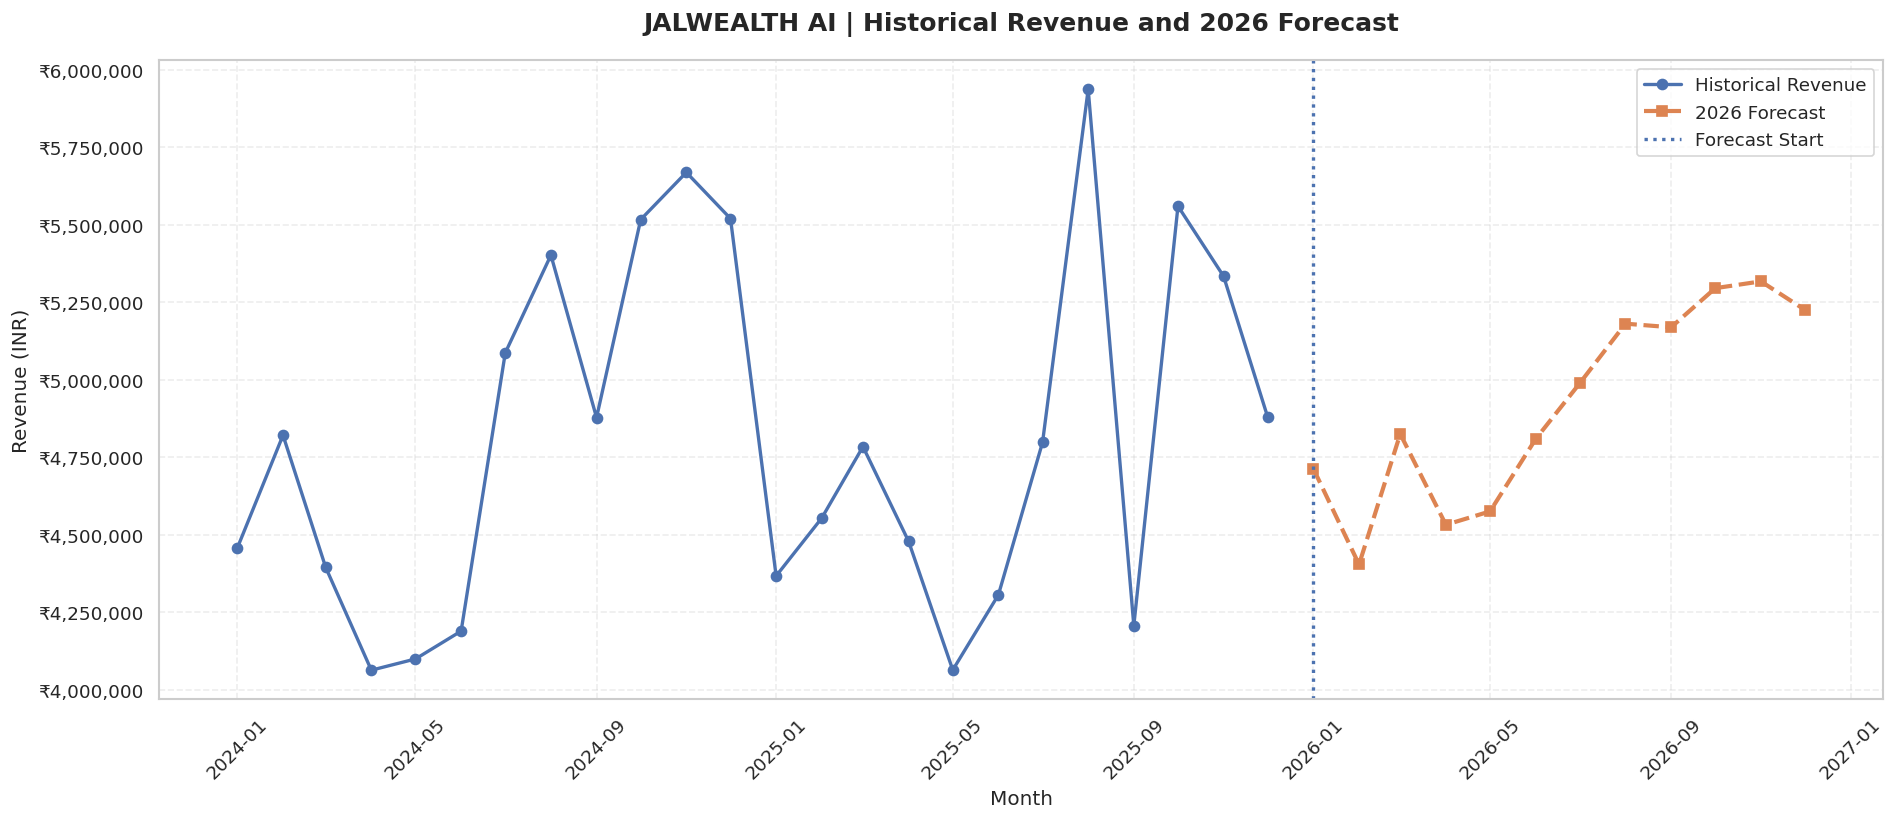


REVENUE COMPARISON SUMMARY
-------------------------------------------------------------------------------------


,Metric,Value
0,Historical Average Monthly Revenue,"₹4,806,949.94"
1,2026 Forecast Average Monthly Revenue,"₹4,919,665.38"
2,Average Monthly Revenue Difference (%),2.34%



Chart saved: C:\Users\User\JALWEALTH_AI_Outputs\Charts\historical_vs_2026_forecast.png
Historical vs forecast comparison completed.


In [80]:
print("=" * 85) 
print("JALWEALTH AI | HISTORICAL VS FORECAST REVENUE") 
print("=" * 85) 
# ------------------------------------------------------------ 
# 1. Prepare historical revenue data 
# ------------------------------------------------------------ 
historical_plot_data = monthly_revenue_history.copy() 
historical_plot_data.index = pd.to_datetime( 
historical_plot_data.index 
) 
forecast_plot_data = forecast_2026.set_index( 
"Forecast_Month" 
)["Predicted_Revenue_INR"] 
# ------------------------------------------------------------ 
# 2. Create combined visualization 
# ------------------------------------------------------------ 
 
fig, ax = plt.subplots(figsize=(16, 7)) 
 
# Historical revenue 
ax.plot( 
    historical_plot_data.index, 
    historical_plot_data.values, 
    marker="o", 
    linewidth=2, 
    label="Historical Revenue" 
) 
 
# Forecast revenue 
ax.plot( 
    forecast_plot_data.index, 
    forecast_plot_data.values, 
    marker="s", 
    linestyle="--", 
    linewidth=2.5, 
    label="2026 Forecast" 
) 
 
# Forecast boundary 
ax.axvline( 
    pd.Timestamp("2026-01-01"), 
    linestyle=":", 
    linewidth=2, 
    label="Forecast Start" 
) 
 
# Labels and formatting 
ax.set_title( 
    "JALWEALTH AI | Historical Revenue and 2026 Forecast", 
    fontsize=15, 
    fontweight="bold", 
    pad=18 
) 
 
ax.set_xlabel("Month", fontsize=12) 
ax.set_ylabel("Revenue (INR)", fontsize=12) 
 
ax.yaxis.set_major_formatter( 
    plt.FuncFormatter( 
        lambda value, position: f"₹{value:,.0f}" 
    ) 
) 
 
ax.grid( 
    True, 
    linestyle="--", 
    alpha=0.35 
) 
 
ax.legend( 
    loc="best", 
    frameon=True 
) 
 
plt.xticks(rotation=45) 
plt.tight_layout() 
 
# ------------------------------------------------------------ 
# 3. Save visualization 
# ------------------------------------------------------------ 
 
forecast_comparison_chart = ( 
    CHART_DIR / "historical_vs_2026_forecast.png" 
) 
 
plt.savefig( 
    forecast_comparison_chart, 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show() 
 
# ------------------------------------------------------------ 
# 4. Generate comparative statistics 
# ------------------------------------------------------------ 
 
historical_average = float( 
    historical_plot_data.mean() 
) 
 
forecast_average = float( 
    forecast_plot_data.mean() 
) 
 
average_change = ( 
    (forecast_average - historical_average) 
    / historical_average * 100 
    if historical_average != 0 
    else np.nan 
) 
 
comparison_summary = pd.DataFrame({ 
 
    "Metric": [ 
        "Historical Average Monthly Revenue", 
        "2026 Forecast Average Monthly Revenue", 
        "Average Monthly Revenue Difference (%)" 
    ], 
 
    "Value": [ 
        historical_average, 
        forecast_average, 
        average_change 
    ] 
 
}) 
 
print("\nREVENUE COMPARISON SUMMARY") 
print("-" * 85) 
 
display( 
    comparison_summary.style.format({ 
        "Value": lambda value: ( 
            f"{value:,.2f}%" 
            if pd.notna(value) 
            and abs(value) <= 10000 
            and comparison_summary.loc[ 
                comparison_summary["Value"] == value, 
                "Metric" 
            ].iloc[0].endswith("(%)") 
            else f"₹{value:,.2f}" 
            if pd.notna(value) 
            else "N/A" 
        ) 
    }) 
) 
# ------------------------------------------------------------ 
# 5. Export comparison summary 
# ------------------------------------------------------------ 
comparison_summary.to_csv( 
REPORT_DIR / "Historical_vs_Forecast_Comparison.csv", 
index=False 
) 
print("\nChart saved:", forecast_comparison_chart) 
print("Historical vs forecast comparison completed.")

In [81]:
 # MONTHLY FORECAST GROWTH & TREND ANALYSIS

JALWEALTH AI | MONTHLY FORECAST GROWTH ANALYSIS

MONTHLY GROWTH INSIGHTS
-------------------------------------------------------------------------------------
Highest Monthly Growth: March (9.56%)
Lowest Monthly Growth: February (-6.55%)


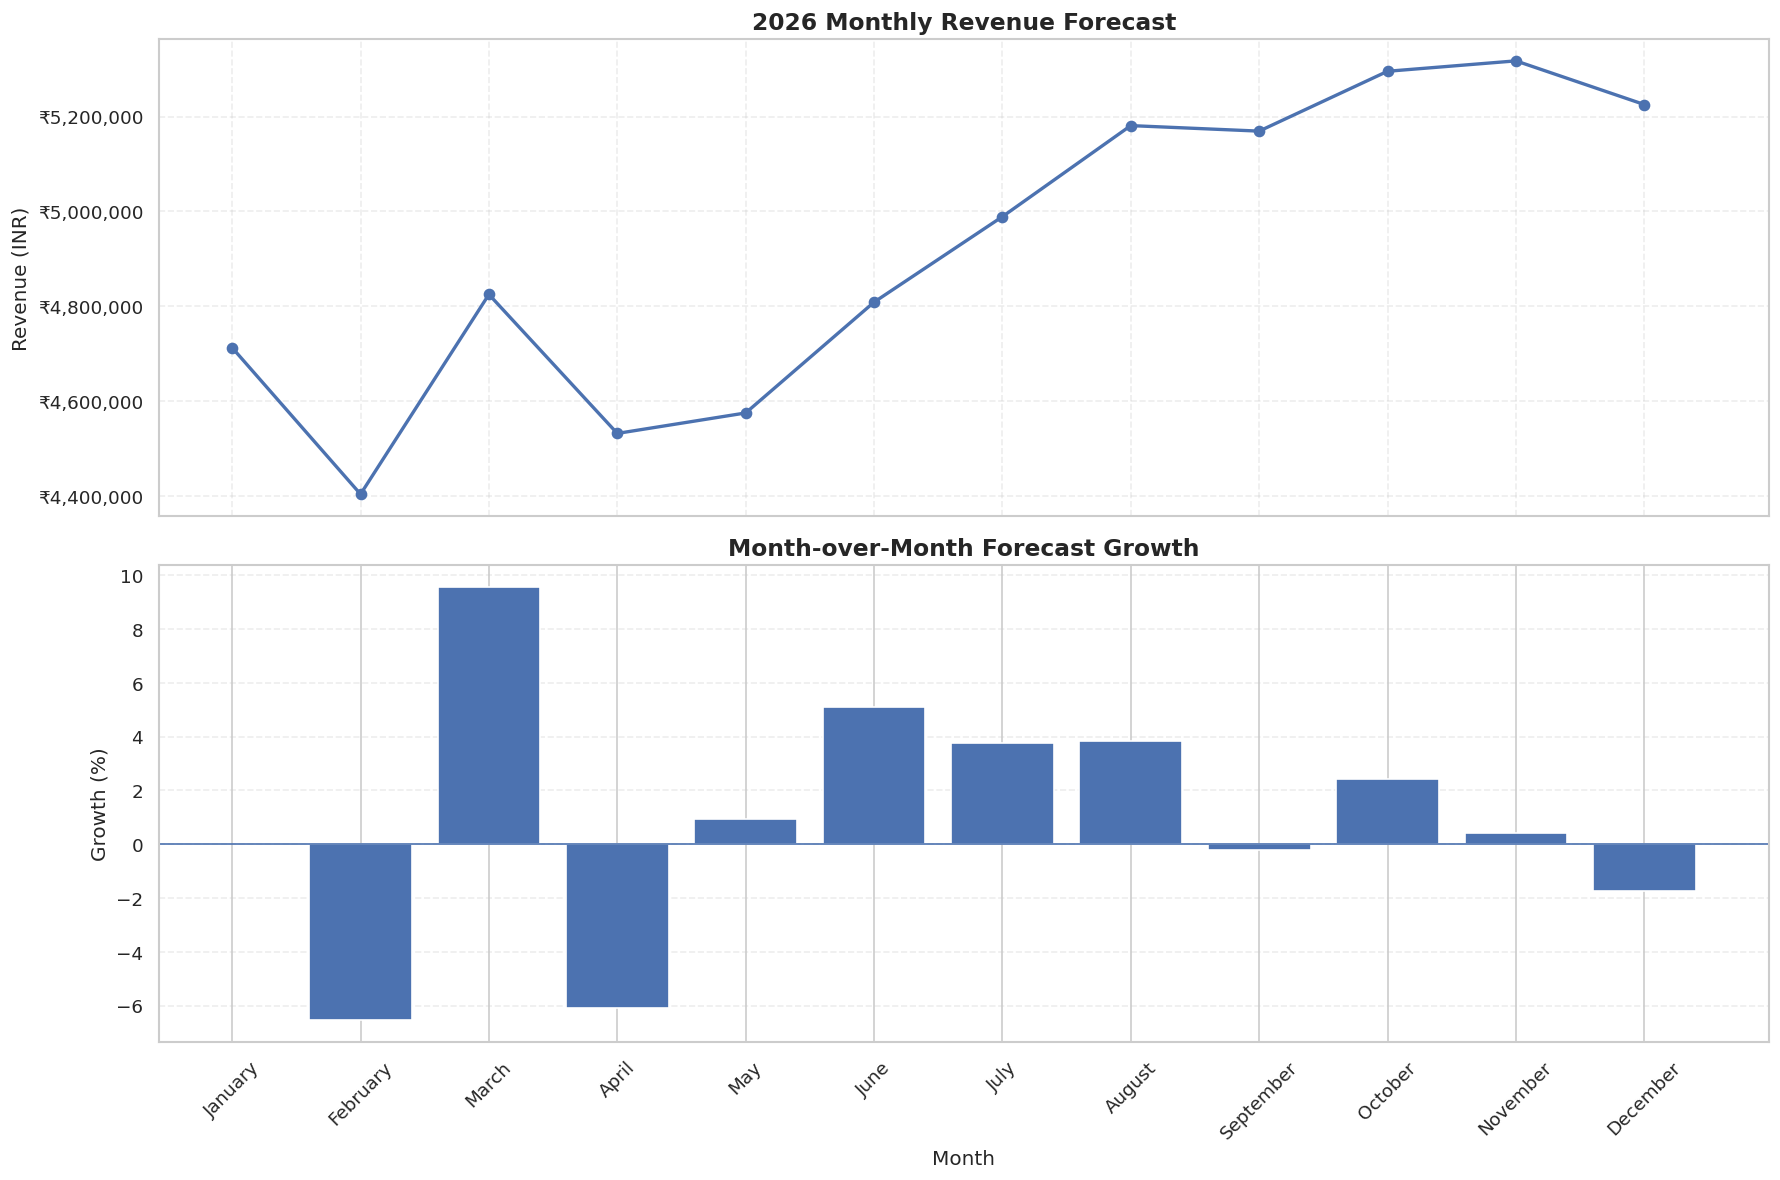


MONTHLY FORECAST GROWTH REPORT
-------------------------------------------------------------------------------------


,Month_Name,Predicted_Revenue_INR,MoM_Change_INR,MoM_Growth_Percent,Cumulative_Revenue_INR
0,January,"₹4,712,902.58",₹nan,nan%,"₹4,712,902.58"
1,February,"₹4,404,278.47","₹-308,624.11",-6.55%,"₹9,117,181.04"
2,March,"₹4,825,170.34","₹420,891.87",9.56%,"₹13,942,351.38"
3,April,"₹4,532,311.60","₹-292,858.74",-6.07%,"₹18,474,662.98"
4,May,"₹4,575,433.41","₹43,121.81",0.95%,"₹23,050,096.39"
5,June,"₹4,808,821.83","₹233,388.42",5.10%,"₹27,858,918.22"
6,July,"₹4,989,055.60","₹180,233.77",3.75%,"₹32,847,973.82"
7,August,"₹5,180,867.66","₹191,812.06",3.84%,"₹38,028,841.48"
8,September,"₹5,169,238.53","₹-11,629.13",-0.22%,"₹43,198,080.01"
9,October,"₹5,295,349.94","₹126,111.41",2.44%,"₹48,493,429.95"



QUARTERLY FORECAST SUMMARY
-------------------------------------------------------------------------------------


,Quarter,Quarterly_Revenue_INR,Average_Monthly_Revenue_INR
0,Q1,"₹13,942,351.38","₹4,647,450.46"
1,Q2,"₹13,916,566.84","₹4,638,855.61"
2,Q3,"₹15,339,161.79","₹5,113,053.93"
3,Q4,"₹15,837,904.53","₹5,279,301.51"



Monthly growth and trend analysis completed.


In [82]:
print("=" * 85) 
print("JALWEALTH AI | MONTHLY FORECAST GROWTH ANALYSIS") 
print("=" * 85) 
# ------------------------------------------------------------ 
# 1. Prepare forecast analysis dataset 
# ------------------------------------------------------------ 
forecast_growth_analysis = forecast_2026.copy() 
forecast_growth_analysis = ( 
forecast_growth_analysis 
.sort_values("Forecast_Month") 
.reset_index(drop=True) 
) 
 
revenue_column = "Predicted_Revenue_INR" 
 
# ------------------------------------------------------------ 
# 2. Calculate month-over-month revenue change 
# ------------------------------------------------------------ 
 
forecast_growth_analysis["Previous_Month_Forecast"] = ( 
    forecast_growth_analysis[revenue_column].shift(1) 
) 
 
forecast_growth_analysis["MoM_Change_INR"] = ( 
    forecast_growth_analysis[revenue_column] 
    - forecast_growth_analysis["Previous_Month_Forecast"] 
) 
 
forecast_growth_analysis["MoM_Growth_Percent"] = ( 
    forecast_growth_analysis["MoM_Change_INR"] 
    .div( 
        forecast_growth_analysis["Previous_Month_Forecast"] 
        .replace(0, np.nan) 
    ) 
    * 100 
) 
 
# First month has no previous forecast month. 
forecast_growth_analysis.loc[ 
    0, 
    "MoM_Change_INR" 
] = np.nan 
 
forecast_growth_analysis.loc[ 
    0, 
    "MoM_Growth_Percent" 
] = np.nan 
 
# ------------------------------------------------------------ 
# 3. Calculate cumulative revenue 
# ------------------------------------------------------------ 
 
forecast_growth_analysis["Cumulative_Revenue_INR"] = ( 
    forecast_growth_analysis[revenue_column].cumsum() 
) 
 
# ------------------------------------------------------------ 
# 4. Calculate quarterly forecast revenue 
# ------------------------------------------------------------ 
 
forecast_growth_analysis["Quarter"] = ( 
    forecast_growth_analysis["Forecast_Month"] 
    .dt.quarter 
    .map(lambda value: f"Q{value}") 
) 
 
quarterly_forecast_growth = ( 
    forecast_growth_analysis 
    .groupby("Quarter", sort=True) 
    .agg( 
        Quarterly_Revenue_INR=( 
            revenue_column, 
            "sum" 
        ), 
        Average_Monthly_Revenue_INR=( 
            revenue_column, 
            "mean" 
        ) 
    ) 
    .reset_index() 
) 
 
# ------------------------------------------------------------ 
# 5. Identify strongest and weakest growth months 
# ------------------------------------------------------------ 
 
valid_growth = forecast_growth_analysis.dropna( 
    subset=["MoM_Growth_Percent"] 
) 
 
if not valid_growth.empty: 
 
    strongest_growth_month = valid_growth.loc[ 
        valid_growth["MoM_Growth_Percent"].idxmax() 
    ] 
 
    weakest_growth_month = valid_growth.loc[ 
        valid_growth["MoM_Growth_Percent"].idxmin() 
    ] 
 
    print("\nMONTHLY GROWTH INSIGHTS") 
    print("-" * 85) 
 
    print( 
        f"Highest Monthly Growth: " 
        f"{strongest_growth_month['Month_Name']} " 
        f"({strongest_growth_month['MoM_Growth_Percent']:.2f}%)" 
    ) 
 
    print( 
        f"Lowest Monthly Growth: " 
        f"{weakest_growth_month['Month_Name']} " 
        f"({weakest_growth_month['MoM_Growth_Percent']:.2f}%)" 
    ) 
 
# ------------------------------------------------------------ 
# 6. Plot monthly revenue and growth 
# ------------------------------------------------------------ 
 
fig, axes = plt.subplots( 
    2, 
    1, 
    figsize=(15, 10), 
    sharex=True 
) 
 
# Monthly revenue 
axes[0].plot( 
    forecast_growth_analysis["Month_Name"], 
    forecast_growth_analysis[revenue_column], 
    marker="o", 
    linewidth=2 
) 
 
axes[0].set_title( 
    "2026 Monthly Revenue Forecast", 
    fontsize=14, 
    fontweight="bold" 
) 
 
axes[0].set_ylabel("Revenue (INR)") 
 
axes[0].yaxis.set_major_formatter( 
    plt.FuncFormatter( 
        lambda value, position: f"₹{value:,.0f}" 
    ) 
) 
 
axes[0].grid( 
    True, 
    linestyle="--", 
    alpha=0.35 
) 
 
# Monthly growth 
axes[1].bar( 
    forecast_growth_analysis["Month_Name"], 
    forecast_growth_analysis["MoM_Growth_Percent"] 
) 
 
axes[1].axhline( 
    0, 
    linewidth=1 
) 
 
axes[1].set_title( 
    "Month-over-Month Forecast Growth", 
    fontsize=14, 
    fontweight="bold" 
) 
 
axes[1].set_ylabel("Growth (%)") 
axes[1].set_xlabel("Month") 
 
axes[1].grid( 
    axis="y", 
    linestyle="--", 
    alpha=0.35 
) 
 
plt.xticks(rotation=45) 
plt.tight_layout() 
 
plt.savefig( 
    CHART_DIR / "2026_monthly_growth_analysis.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show() 
 
# ------------------------------------------------------------ 
# 7. Display detailed reports 
# ------------------------------------------------------------ 
 
print("\nMONTHLY FORECAST GROWTH REPORT") 
print("-" * 85) 
 
display( 
    forecast_growth_analysis[ 
        [ 
            "Month_Name", 
            "Predicted_Revenue_INR", 
            "MoM_Change_INR", 
            "MoM_Growth_Percent", 
            "Cumulative_Revenue_INR" 
        ] 
    ].style.format({ 
        "Predicted_Revenue_INR": "₹{:,.2f}", 
        "MoM_Change_INR": "₹{:,.2f}", 
        "MoM_Growth_Percent": "{:,.2f}%", 
        "Cumulative_Revenue_INR": "₹{:,.2f}" 
    }) 
) 
 
print("\nQUARTERLY FORECAST SUMMARY") 
print("-" * 85) 
 
display( 
    quarterly_forecast_growth.style.format({ 
        "Quarterly_Revenue_INR": "₹{:,.2f}", 
        "Average_Monthly_Revenue_INR": "₹{:,.2f}" 
    }) 
) 
 
# ------------------------------------------------------------ 
# 8. Export growth reports 
# ------------------------------------------------------------ 
 
forecast_growth_analysis.to_csv( 
    REPORT_DIR / "2026_Monthly_Growth_Analysis.csv", 
index=False 
) 
quarterly_forecast_growth.to_csv( 
REPORT_DIR / "2026_Quarterly_Forecast_Summary.csv", 
index=False 
) 
print("\nMonthly growth and trend analysis completed.") 

In [83]:
# 2026 REVENUE SCENARIO ANALYSIS 

JALWEALTH AI | 2026 REVENUE SCENARIO ANALYSIS


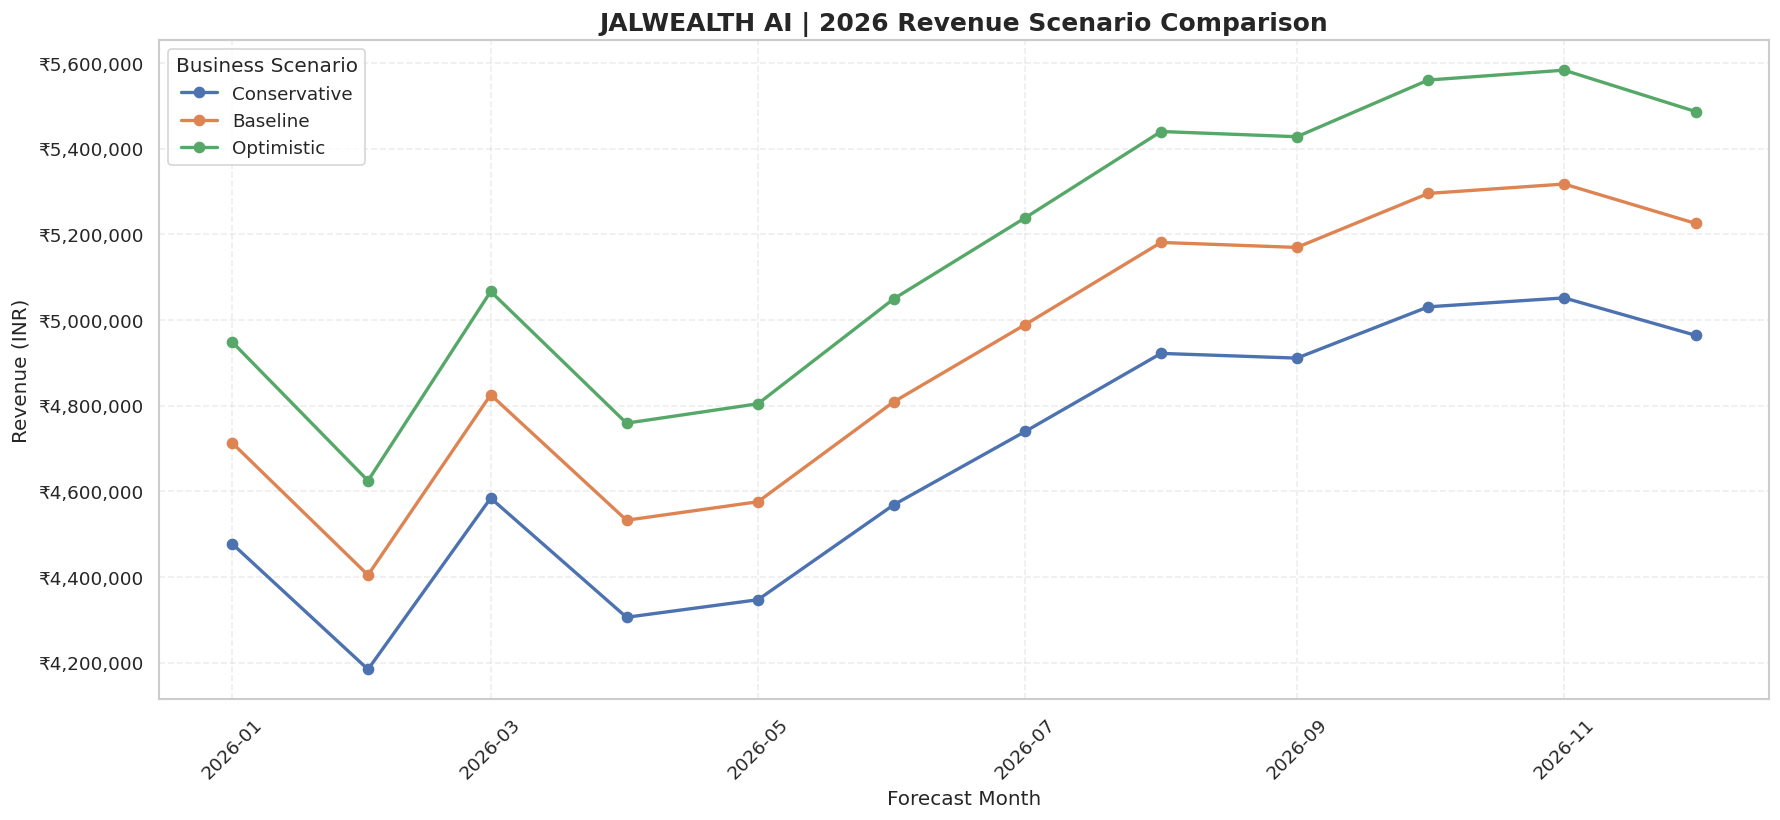


ANNUAL SCENARIO COMPARISON
-------------------------------------------------------------------------------------


,Scenario,Annual_Revenue_INR,Average_Monthly_Revenue_INR,Minimum_Monthly_Revenue_INR,Maximum_Monthly_Revenue_INR,Difference_From_Baseline_INR,Difference_From_Baseline_Percent
0,Conservative,"₹56,084,185.31","₹4,673,682.11","₹4,184,064.54","₹5,051,411.38","₹-2,951,799.23",-5.00%
1,Baseline,"₹59,035,984.54","₹4,919,665.38","₹4,404,278.47","₹5,317,275.14",₹0.00,0.00%
2,Optimistic,"₹61,987,783.77","₹5,165,648.65","₹4,624,492.39","₹5,583,138.90","₹2,951,799.23",5.00%



Scenario analysis completed successfully.
Scenario reports exported.


In [84]:
print("=" * 85) 
print("JALWEALTH AI | 2026 REVENUE SCENARIO ANALYSIS") 
print("=" * 85) 
# ------------------------------------------------------------ 
# 1. Validate baseline forecast 
# ------------------------------------------------------------ 
if forecast_2026.empty: 
    raise ValueError("Baseline forecast is empty.") 
if forecast_2026["Predicted_Revenue_INR"].isna().any(): 
    raise ValueError("Baseline forecast contains missing values.") 
# ------------------------------------------------------------ 
# 2. Define business scenario assumptions 
# ------------------------------------------------------------ 
SCENARIO_ASSUMPTIONS = { 
"Conservative": -0.05, 
    "Baseline": 0.00, 
    "Optimistic": 0.05 
} 
 
# These percentages are illustrative planning assumptions. 
# They are NOT statistical confidence intervals. 
 
# ------------------------------------------------------------ 
# 3. Build scenario forecast 
# ------------------------------------------------------------ 
 
scenario_records = [] 
 
for scenario_name, adjustment in SCENARIO_ASSUMPTIONS.items(): 
 
    for _, row in forecast_2026.iterrows(): 
 
        baseline_revenue = float( 
            row["Predicted_Revenue_INR"] 
        ) 
 
        scenario_revenue = ( 
            baseline_revenue * (1 + adjustment) 
        ) 
 
        scenario_records.append({ 
 
            "Forecast_Month": row["Forecast_Month"], 
 
            "Month_Name": row["Month_Name"], 
 
            "Scenario": scenario_name, 
 
            "Adjustment_Percent": adjustment * 100, 
 
            "Baseline_Revenue_INR": baseline_revenue, 
 
            "Scenario_Revenue_INR": scenario_revenue 
 
        }) 
 
scenario_forecast_df = pd.DataFrame( 
    scenario_records 
) 
 
# ------------------------------------------------------------ 
# 4. Generate annual scenario summary 
# ------------------------------------------------------------ 
 
scenario_summary = ( 
    scenario_forecast_df 
    .groupby("Scenario", sort=False) 
    .agg( 
        Annual_Revenue_INR=( 
            "Scenario_Revenue_INR", 
            "sum" 
        ), 
        Average_Monthly_Revenue_INR=( 
            "Scenario_Revenue_INR", 
            "mean" 
        ), 
        Minimum_Monthly_Revenue_INR=( 
            "Scenario_Revenue_INR", 
            "min" 
        ), 
        Maximum_Monthly_Revenue_INR=( 
            "Scenario_Revenue_INR", 
            "max" 
        ) 
    ) 
    .reset_index() 
) 
 
# ------------------------------------------------------------ 
# 5. Calculate differences against baseline 
# ------------------------------------------------------------ 
 
baseline_annual_revenue = float( 
    scenario_summary.loc[ 
        scenario_summary["Scenario"] == "Baseline", 
        "Annual_Revenue_INR" 
    ].iloc[0] 
) 
 
scenario_summary["Difference_From_Baseline_INR"] = ( 
    scenario_summary["Annual_Revenue_INR"] 
    - baseline_annual_revenue 
) 
 
scenario_summary["Difference_From_Baseline_Percent"] = ( 
    scenario_summary["Difference_From_Baseline_INR"] 
    / baseline_annual_revenue * 100 
    if baseline_annual_revenue != 0 
    else np.nan 
) 
 
# ------------------------------------------------------------ 
# 6. Visualize revenue scenarios 
# ------------------------------------------------------------ 
 
scenario_pivot = scenario_forecast_df.pivot( 
    index="Forecast_Month", 
    columns="Scenario", 
    values="Scenario_Revenue_INR" 
) 
 
fig, ax = plt.subplots(figsize=(15, 7)) 
 
for scenario_name in SCENARIO_ASSUMPTIONS: 
 
    ax.plot( 
        scenario_pivot.index, 
        scenario_pivot[scenario_name], 
        marker="o", 
        linewidth=2, 
        label=scenario_name 
    ) 
 
ax.set_title( 
    "JALWEALTH AI | 2026 Revenue Scenario Comparison", 
    fontsize=15, 
    fontweight="bold" 
) 
 
ax.set_xlabel("Forecast Month") 
ax.set_ylabel("Revenue (INR)") 
 
ax.yaxis.set_major_formatter( 
    plt.FuncFormatter( 
        lambda value, position: f"₹{value:,.0f}" 
    ) 
) 
 
ax.grid( 
    True, 
    linestyle="--", 
    alpha=0.35 
) 
 
ax.legend(title="Business Scenario") 
 
plt.xticks(rotation=45) 
plt.tight_layout() 
 
plt.savefig( 
    CHART_DIR / "2026_revenue_scenario_comparison.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show() 
 
# ------------------------------------------------------------ 
# 7. Display scenario comparison 
# ------------------------------------------------------------ 
 
print("\nANNUAL SCENARIO COMPARISON") 
print("-" * 85) 
 
display( 
    scenario_summary.style.format({ 
        "Annual_Revenue_INR": "₹{:,.2f}", 
        "Average_Monthly_Revenue_INR": "₹{:,.2f}", 
        "Minimum_Monthly_Revenue_INR": "₹{:,.2f}", 
        "Maximum_Monthly_Revenue_INR": "₹{:,.2f}", 
        "Difference_From_Baseline_INR": "₹{:,.2f}", 
        "Difference_From_Baseline_Percent": "{:,.2f}%" 
    }) 
) 
 
# ------------------------------------------------------------ 
# 8. Export scenario reports 
# ------------------------------------------------------------ 
 
scenario_forecast_df.to_csv( 
    REPORT_DIR / "2026_Revenue_Scenario_Details.csv", 
index=False 
) 
scenario_summary.to_csv( 
REPORT_DIR / "2026_Annual_Scenario_Comparison.csv", 
index=False 
) 
print("\nScenario analysis completed successfully.") 
print("Scenario reports exported.") 

In [85]:
# QUARTERLY SCENARIO ANALYSIS 

JALWEALTH AI | QUARTERLY SCENARIO ANALYSIS

QUARTERLY REVENUE COMPARISON
-------------------------------------------------------------------------------------


Scenario,Conservative,Baseline,Optimistic
Quarter,,,
Q1,"₹13,245,233.81","₹13,942,351.38","₹14,639,468.95"
Q2,"₹13,220,738.50","₹13,916,566.84","₹14,612,395.18"
Q3,"₹14,572,203.70","₹15,339,161.79","₹16,106,119.88"
Q4,"₹15,046,009.30","₹15,837,904.53","₹16,629,799.76"


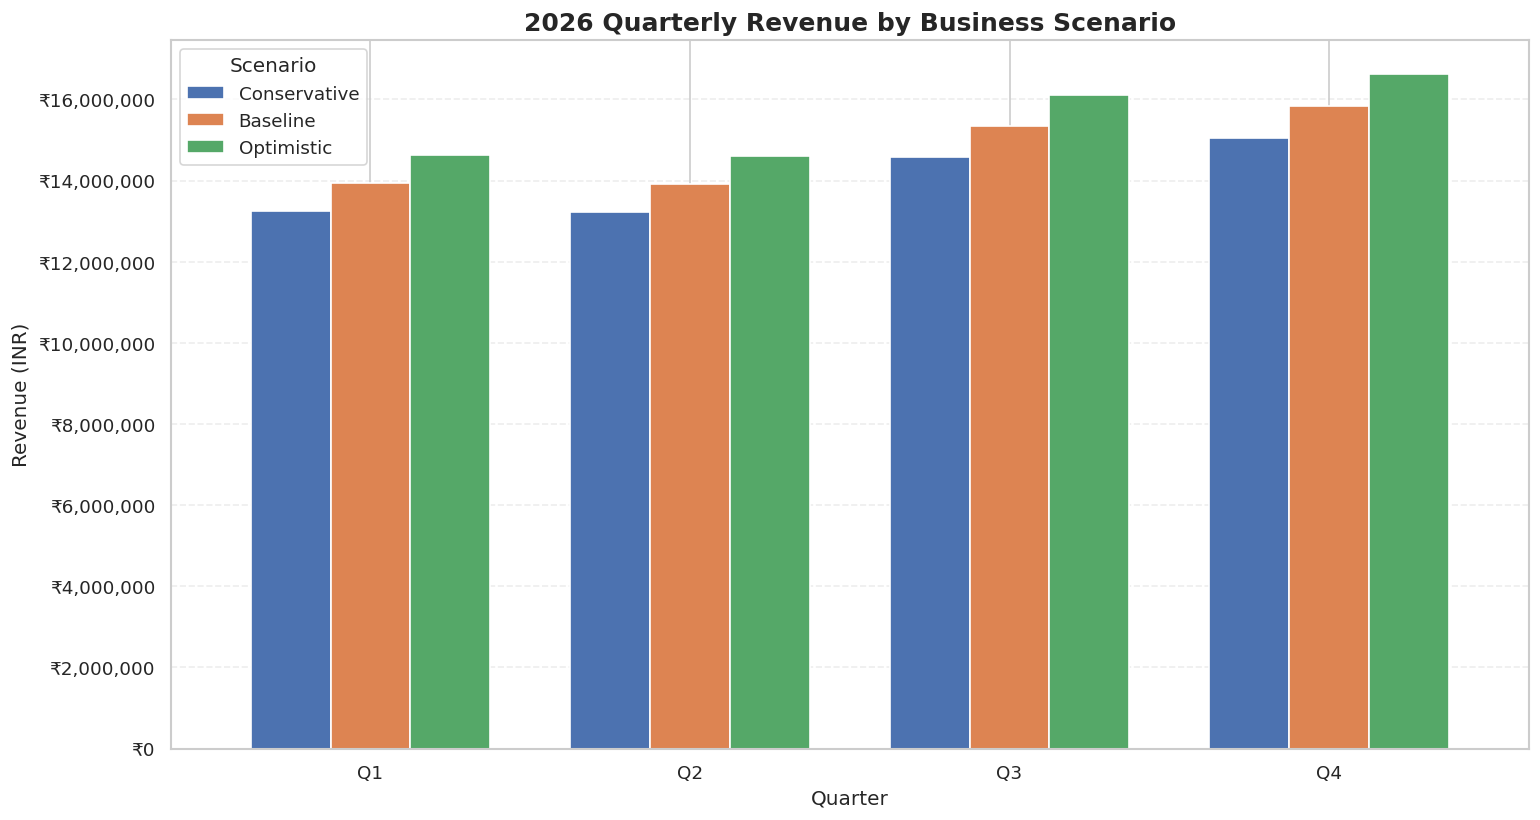


QUARTERLY BUSINESS INSIGHTS
-------------------------------------------------------------------------------------
Highest Revenue Quarter: Q4 (₹15,837,904.53)
Lowest Revenue Quarter: Q2 (₹13,916,566.84)

Quarterly scenario analysis completed.


In [86]:
print("=" * 85) 
print("JALWEALTH AI | QUARTERLY SCENARIO ANALYSIS") 
print("=" * 85) 
# ------------------------------------------------------------ 
# 1. Prepare scenario data 
# ------------------------------------------------------------ 
quarterly_scenario_data = scenario_forecast_df.copy() 
quarterly_scenario_data["Quarter"] = ( 
quarterly_scenario_data["Forecast_Month"] 
.dt.quarter 
.map(lambda quarter: f"Q{quarter}") 
) 
# ------------------------------------------------------------ 
# 2. Aggregate quarterly revenue 
# ------------------------------------------------------------ 
quarterly_scenario_summary = ( 
    quarterly_scenario_data 
    .groupby( 
        ["Quarter", "Scenario"], 
        sort=True 
    ) 
    .agg( 
        Quarterly_Revenue_INR=( 
            "Scenario_Revenue_INR", 
            "sum" 
        ) 
    ) 
    .reset_index() 
) 
 
# ------------------------------------------------------------ 
# 3. Create quarterly comparison matrix 
# ------------------------------------------------------------ 
 
quarterly_scenario_pivot = ( 
    quarterly_scenario_summary 
    .pivot( 
        index="Quarter", 
        columns="Scenario", 
        values="Quarterly_Revenue_INR" 
    ) 
) 
 
quarterly_scenario_pivot = quarterly_scenario_pivot[ 
    list(SCENARIO_ASSUMPTIONS.keys()) 
] 
 
print("\nQUARTERLY REVENUE COMPARISON") 
print("-" * 85) 
 
display( 
    quarterly_scenario_pivot.style.format( 
        "₹{:,.2f}" 
    ) 
) 
 
# ------------------------------------------------------------ 
# 4. Visualize quarterly scenario comparison 
# ------------------------------------------------------------ 
 
ax = quarterly_scenario_pivot.plot( 
    kind="bar", 
    figsize=(13, 7), 
    width=0.75 
) 
 
ax.set_title( 
    "2026 Quarterly Revenue by Business Scenario", 
    fontsize=15, 
    fontweight="bold" 
) 
 
ax.set_xlabel("Quarter") 
ax.set_ylabel("Revenue (INR)") 
 
ax.yaxis.set_major_formatter( 
    plt.FuncFormatter( 
        lambda value, position: f"₹{value:,.0f}" 
    ) 
) 
 
ax.grid( 
    axis="y", 
    linestyle="--", 
    alpha=0.35 
) 
 
ax.legend(title="Scenario") 
 
plt.xticks(rotation=0) 
plt.tight_layout() 
 
plt.savefig( 
    CHART_DIR / "2026_quarterly_scenario_analysis.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show() 
 
# ------------------------------------------------------------ 
# 5. Identify strongest baseline quarter 
# ------------------------------------------------------------ 
 
baseline_quarterly = quarterly_scenario_summary[ 
    quarterly_scenario_summary["Scenario"] == "Baseline" 
] 
 
strongest_quarter = baseline_quarterly.loc[ 
    baseline_quarterly["Quarterly_Revenue_INR"].idxmax() 
] 
 
weakest_quarter = baseline_quarterly.loc[ 
    baseline_quarterly["Quarterly_Revenue_INR"].idxmin() 
] 
 
print("\nQUARTERLY BUSINESS INSIGHTS") 
print("-" * 85) 
 
print( 
    "Highest Revenue Quarter:", 
    strongest_quarter["Quarter"], 
    f"(₹{strongest_quarter['Quarterly_Revenue_INR']:,.2f})" 
) 
 
print( 
    "Lowest Revenue Quarter:", 
    weakest_quarter["Quarter"], 
    f"(₹{weakest_quarter['Quarterly_Revenue_INR']:,.2f})" 
) 
 
# ------------------------------------------------------------ 
# 6. Export quarterly report 
# ------------------------------------------------------------ 
 
quarterly_scenario_summary.to_csv( 
    REPORT_DIR / "2026_Quarterly_Scenario_Analysis.csv", 
    index=False 
) 
 
print("\nQuarterly scenario analysis completed.") 

 # ENVIRONMENTAL IMPACT INTELLIGENCE & BIOMASS UTILIZATION

## 1. Phase Objective 
The objective of this phase is to evaluate the environmental performance of the JALWEALTH 
business model through quantitative analysis of water hyacinth collection, processing, waste 
diversion and finished product manufacturing. 
The analysis connects environmental resource utilization with business operations. 
    
## 2. Environmental Performance Indicators 
The following indicators will be evaluated:
- Total water hyacinth collected (kg).
- Total water hyacinth processed (kg).
- Total waste diverted (kg). 
- Finished products manufactured.
- Artisan employment days. 
- Biomass processing utilization rate. 
- Waste diversion efficiency.
- Monthly environmental performance.
- Relationship between production and biomass utilization.
    
## 3. Analytical Methodology 
The phase will include: 
1. Environmental data validation. 
2. Biomass collection and processing analysis. 
3. Waste diversion assessment. 
4. Monthly environmental trend analysis. 
5. Product manufacturing and resource utilization analysis. 
6. Environmental performance visualization. 
7. Operational efficiency indicators. 
8. Management recommendations. 
    
## 4. Business and Environmental Value 
The analysis aims to help management understand: 
- How efficiently collected water hyacinth is utilized.
- Whether biomass processing keeps pace with collection.
- How waste diversion changes over time. 
- Whether production activity is associated with environmental outcomes.
- Where operational improvements may be possible. 
    
## 5. Important Analytical Limitations 
- Environmental indicators are based on the supplied business dataset.
- Waste diversion should not automatically be interpreted as verified ecological restoration.
- No carbon reduction, biodiversity improvement or water-quality benefit will be claimed without suitable measurement data.
- Collection, processing and waste diversion are different operational measurements and must not be treated as interchangeable. 

## 6. Expected Deliverables 
- Environmental KPI report.
- Biomass utilization analysis. 
- Waste diversion efficiency indicators. 
- Monthly environmental performance charts.
- Production and resource utilization insights.
- Exportable environmental impact reports. 
 
**Goal:** Establish a measurable, transparent environmental performance framework 
that connects water hyacinth utilization with JALWEALTH's business operations. 

In [87]:
 # ENVIRONMENTAL DATA PREPARATION & VALIDATION 

In [88]:
print("=" * 85) 
print("JALWEALTH AI | ENVIRONMENTAL DATA VALIDATION") 
print("=" * 85) 
 
# ------------------------------------------------------------ 
# 1. Define environmental source columns 
# ------------------------------------------------------------ 
 
ENVIRONMENTAL_COLUMNS = [ 
    "Water hyacinth collected (kg)", 
    "Water hyacinth processed (kg)", 
    "Waste diverted (kg)", 
    "Finished products manufactured", 
    "Artisan employment days" 
] 
 
required_environmental_columns = [ 
    "Order Date", 
    *ENVIRONMENTAL_COLUMNS 
] 
 
missing_environmental_columns = [ 
    column 
    for column in required_environmental_columns 
    if column not in eda_df.columns 
] 
 
if missing_environmental_columns: 
    raise KeyError( 
        "Missing environmental columns: " 
        f"{missing_environmental_columns}" 
    ) 
 
# ------------------------------------------------------------ 
# 2. Prepare environmental dataset 
# ------------------------------------------------------------ 
 
environmental_df = eda_df[ 
    required_environmental_columns 
].copy() 
 
environmental_df["Order Date"] = pd.to_datetime( 
    environmental_df["Order Date"], 
    errors="coerce" 
) 
 
for column in ENVIRONMENTAL_COLUMNS: 
 
    environmental_df[column] = pd.to_numeric( 
        environmental_df[column], 
        errors="coerce" 
    ) 
 
# ------------------------------------------------------------ 
# 3. Create data quality report 
# ------------------------------------------------------------ 
 
environmental_quality_report = pd.DataFrame({ 
 
    "Column": ENVIRONMENTAL_COLUMNS, 
 
    "Missing_Values": [ 
        environmental_df[column].isna().sum() 
        for column in ENVIRONMENTAL_COLUMNS 
    ], 
 
    "Negative_Values": [ 
        (environmental_df[column] < 0).sum() 
        for column in ENVIRONMENTAL_COLUMNS 
    ], 
 
    "Zero_Values": [ 
        (environmental_df[column] == 0).sum() 
        for column in ENVIRONMENTAL_COLUMNS 
    ], 
 
    "Total_Values": [ 
        environmental_df[column].count() 
        for column in ENVIRONMENTAL_COLUMNS 
    ] 
 
}) 
 
print("\nENVIRONMENTAL DATA QUALITY") 
print("-" * 85) 
 
display(environmental_quality_report) 
 
# ------------------------------------------------------------ 
# 4. Validate non-negative environmental quantities 
# ------------------------------------------------------------ 
 
negative_environmental_records = {} 
 
for column in ENVIRONMENTAL_COLUMNS: 
 
    negative_rows = environmental_df[ 
        environmental_df[column] < 0 
    ] 
 
    negative_environmental_records[column] = len( 
        negative_rows 
    ) 
 
    if len(negative_rows) > 0: 
 
        print( 
            f"WARNING: {column} contains " 
            f"{len(negative_rows)} negative values." 
        ) 
 
# ------------------------------------------------------------ 
# 5. Create analysis-ready environmental dataset 
# ------------------------------------------------------------ 
 
environmental_analysis_df = environmental_df.dropna( 
    subset=["Order Date", *ENVIRONMENTAL_COLUMNS] 
).copy() 
 
if environmental_analysis_df.empty: 
    raise ValueError( 
        "No complete environmental records are available." 
    ) 
 
if ( 
    environmental_analysis_df[ENVIRONMENTAL_COLUMNS] 
    .lt(0) 
    .any() 
    .any() 
): 
 
    raise ValueError( 
        "Negative environmental measurements detected. " 
        "Investigate source records before calculating KPIs." 
    ) 
 
# ------------------------------------------------------------ 
# 6. Add monthly aggregation key 
# ------------------------------------------------------------ 
 
environmental_analysis_df["Month"] = ( 
    environmental_analysis_df["Order Date"] 
    .dt.to_period("M") 
    .dt.to_timestamp() 
) 
 
# ------------------------------------------------------------ 
# 7. Display data coverage 
# ------------------------------------------------------------ 
 
print("\nENVIRONMENTAL DATA COVERAGE") 
print("-" * 85) 
 
print( 
    "First Recorded Date:", 
    environmental_analysis_df["Order Date"].min() 
) 
 
print( 
    "Last Recorded Date:", 
    environmental_analysis_df["Order Date"].max() 
) 
 
print( 
    "Valid Environmental Records:", 
    len(environmental_analysis_df) 
) 
 
print( 
    "Monthly Periods:", 
    environmental_analysis_df["Month"].nunique() 
) 
 
print( 
    "Rows Excluded During Cleaning:", 
    len(environmental_df) - len(environmental_analysis_df) 
) 
 
# ------------------------------------------------------------ 
# 8. Export validation report 
# ------------------------------------------------------------ 
 
environmental_quality_report.to_csv( 
    REPORT_DIR / "Environmental_Data_Quality_Report.csv", 
    index=False 
) 
 
environmental_analysis_df.to_csv( 
    OUTPUT_DIR / "Environmental_Analysis_Ready_Data.csv", 
    index=False 
) 
 
print("\nEnvironmental data preparation completed.")

JALWEALTH AI | ENVIRONMENTAL DATA VALIDATION

ENVIRONMENTAL DATA QUALITY
-------------------------------------------------------------------------------------


,Column,Missing_Values,Negative_Values,Zero_Values,Total_Values
0,Water hyacinth collected (kg),0,0,0,9976
1,Water hyacinth processed (kg),0,0,0,9976
2,Waste diverted (kg),0,0,0,9976
3,Finished products manufactured,0,0,0,9976
4,Artisan employment days,0,0,0,9976



ENVIRONMENTAL DATA COVERAGE
-------------------------------------------------------------------------------------
First Recorded Date: 2024-01-01 00:00:00
Last Recorded Date: 2025-12-31 00:00:00
Valid Environmental Records: 9976
Monthly Periods: 24
Rows Excluded During Cleaning: 0

Environmental data preparation completed.


In [89]:
 # ENVIRONMENTAL PERFORMANCE KPI CALCULATION 

In [90]:
print("=" * 85) 
print("JALWEALTH AI | ENVIRONMENTAL PERFORMANCE DASHBOARD") 
print("=" * 85) 
 
# ------------------------------------------------------------ 
# 1. Calculate aggregate environmental indicators 
# ------------------------------------------------------------ 
 
environmental_kpis = { 
 
    "Total_Biomass_Collected_KG": 
        environmental_analysis_df[ 
            "Water hyacinth collected (kg)" 
        ].sum(), 
 
    "Total_Biomass_Processed_KG": 
        environmental_analysis_df[ 
            "Water hyacinth processed (kg)" 
        ].sum(), 
 
    "Total_Waste_Diverted_KG": 
        environmental_analysis_df[ 
            "Waste diverted (kg)" 
        ].sum(), 
 
    "Total_Finished_Products": 
        environmental_analysis_df[ 
            "Finished products manufactured" 
        ].sum(), 
 
    "Total_Artisan_Employment_Days": 
        environmental_analysis_df[ 
            "Artisan employment days" 
        ].sum() 
 
} 
 
# ------------------------------------------------------------ 
# 2. Calculate biomass processing utilization 
# ------------------------------------------------------------ 
 
total_collected = environmental_kpis[ 
    "Total_Biomass_Collected_KG" 
] 
 
total_processed = environmental_kpis[ 
    "Total_Biomass_Processed_KG" 
] 
 
total_diverted = environmental_kpis[ 
    "Total_Waste_Diverted_KG" 
] 
 
processing_utilization_rate = ( 
    total_processed / total_collected * 100 
    if total_collected > 0 
    else np.nan 
) 
 
# ------------------------------------------------------------ 
# 3. Calculate waste diversion ratio 
# ------------------------------------------------------------ 
 
waste_diversion_ratio = ( 
    total_diverted / total_collected * 100 
    if total_collected > 0 
    else np.nan 
) 
 
# ------------------------------------------------------------ 
# 4. Calculate processing-to-diversion ratio 
# ------------------------------------------------------------ 
 
processing_to_diversion_ratio = ( 
    total_diverted / total_processed * 100 
    if total_processed > 0 
    else np.nan 
) 
 
# ------------------------------------------------------------ 
# 5. Calculate manufacturing productivity indicators 
# ------------------------------------------------------------ 
 
total_products = environmental_kpis[ 
    "Total_Finished_Products" 
] 
 
total_artisan_days = environmental_kpis[ 
    "Total_Artisan_Employment_Days" 
] 
 
biomass_per_product = ( 
    total_processed / total_products 
    if total_products > 0 
    else np.nan 
) 
 
products_per_artisan_day = ( 
    total_products / total_artisan_days 
    if total_artisan_days > 0 
    else np.nan 
) 
 
# ------------------------------------------------------------ 
# 6. Create comprehensive KPI report 
# ------------------------------------------------------------ 
 
environmental_kpi_report = pd.DataFrame({ 
 
    "KPI": [ 
        "Total Biomass Collected", 
        "Total Biomass Processed", 
        "Total Waste Diverted", 
        "Processing Utilization Rate", 
        "Waste Diversion Ratio", 
        "Diversion-to-Processing Ratio", 
        "Finished Products Manufactured", 
        "Artisan Employment Days", 
        "Biomass Processed per Finished Product", 
        "Products per Artisan Employment Day" 
    ], 
 
    "Value": [ 
        total_collected, 
        total_processed, 
        total_diverted, 
        processing_utilization_rate, 
        waste_diversion_ratio, 
        processing_to_diversion_ratio, 
        total_products, 
        total_artisan_days, 
        biomass_per_product, 
        products_per_artisan_day 
    ], 
 
    "Unit": [ 
        "kg", 
        "kg", 
        "kg", 
        "%", 
        "%", 
        "%", 
        "units", 
        "days", 
        "kg/product", 
        "products/day" 
    ] 
 
}) 
 
# ------------------------------------------------------------ 
# 7. Display environmental dashboard 
# ------------------------------------------------------------ 
 
print("\nENVIRONMENTAL PERFORMANCE KPIs") 
print("-" * 85) 
 
display( 
    environmental_kpi_report.style.format({ 
        "Value": "{:,.2f}" 
    }) 
) 
 
# ------------------------------------------------------------ 
# 8. Generate operational observations 
# ------------------------------------------------------------ 
 
print("\nKEY ENVIRONMENTAL OBSERVATIONS") 
print("-" * 85) 
 
print( 
    f"Biomass Collected: {total_collected:,.2f} kg" 
) 
 
print( 
    f"Biomass Processed: {total_processed:,.2f} kg" 
) 
 
print( 
    f"Waste Diverted: {total_diverted:,.2f} kg" 
) 
 
print( 
    f"Processing Utilization Rate: " 
    f"{processing_utilization_rate:.2f}%" 
    if pd.notna(processing_utilization_rate) 
    else "Processing Utilization Rate: N/A" 
) 
 
print( 
    f"Finished Products Manufactured: " 
    f"{total_products:,.0f}" 
) 
 
print( 
    f"Artisan Employment Days: " 
    f"{total_artisan_days:,.0f}" 
) 
 
# ------------------------------------------------------------ 
# 9. Export KPI report 
# ------------------------------------------------------------ 
 
environmental_kpi_report.to_csv( 
    REPORT_DIR / "Environmental_Performance_KPI_Report.csv", 
    index=False 
) 
 
print("\nEnvironmental KPI report exported successfully.")

JALWEALTH AI | ENVIRONMENTAL PERFORMANCE DASHBOARD

ENVIRONMENTAL PERFORMANCE KPIs
-------------------------------------------------------------------------------------


,KPI,Value,Unit
0,Total Biomass Collected,"355,404.77",kg
1,Total Biomass Processed,"318,127.87",kg
2,Total Waste Diverted,"337,640.54",kg
3,Processing Utilization Rate,89.51,%
4,Waste Diversion Ratio,95.00,%
5,Diversion-to-Processing Ratio,106.13,%
6,Finished Products Manufactured,"131,024.00",units
7,Artisan Employment Days,"81,384.94",days
8,Biomass Processed per Finished Product,2.43,kg/product
9,Products per Artisan Employment Day,1.61,products/day



KEY ENVIRONMENTAL OBSERVATIONS
-------------------------------------------------------------------------------------
Biomass Collected: 355,404.77 kg
Biomass Processed: 318,127.87 kg
Waste Diverted: 337,640.54 kg
Processing Utilization Rate: 89.51%
Finished Products Manufactured: 131,024
Artisan Employment Days: 81,385

Environmental KPI report exported successfully.


In [91]:
# Biomass Collection vs Processing Analysis 

JALWEALTH AI | BIOMASS COLLECTION AND PROCESSING ANALYSIS


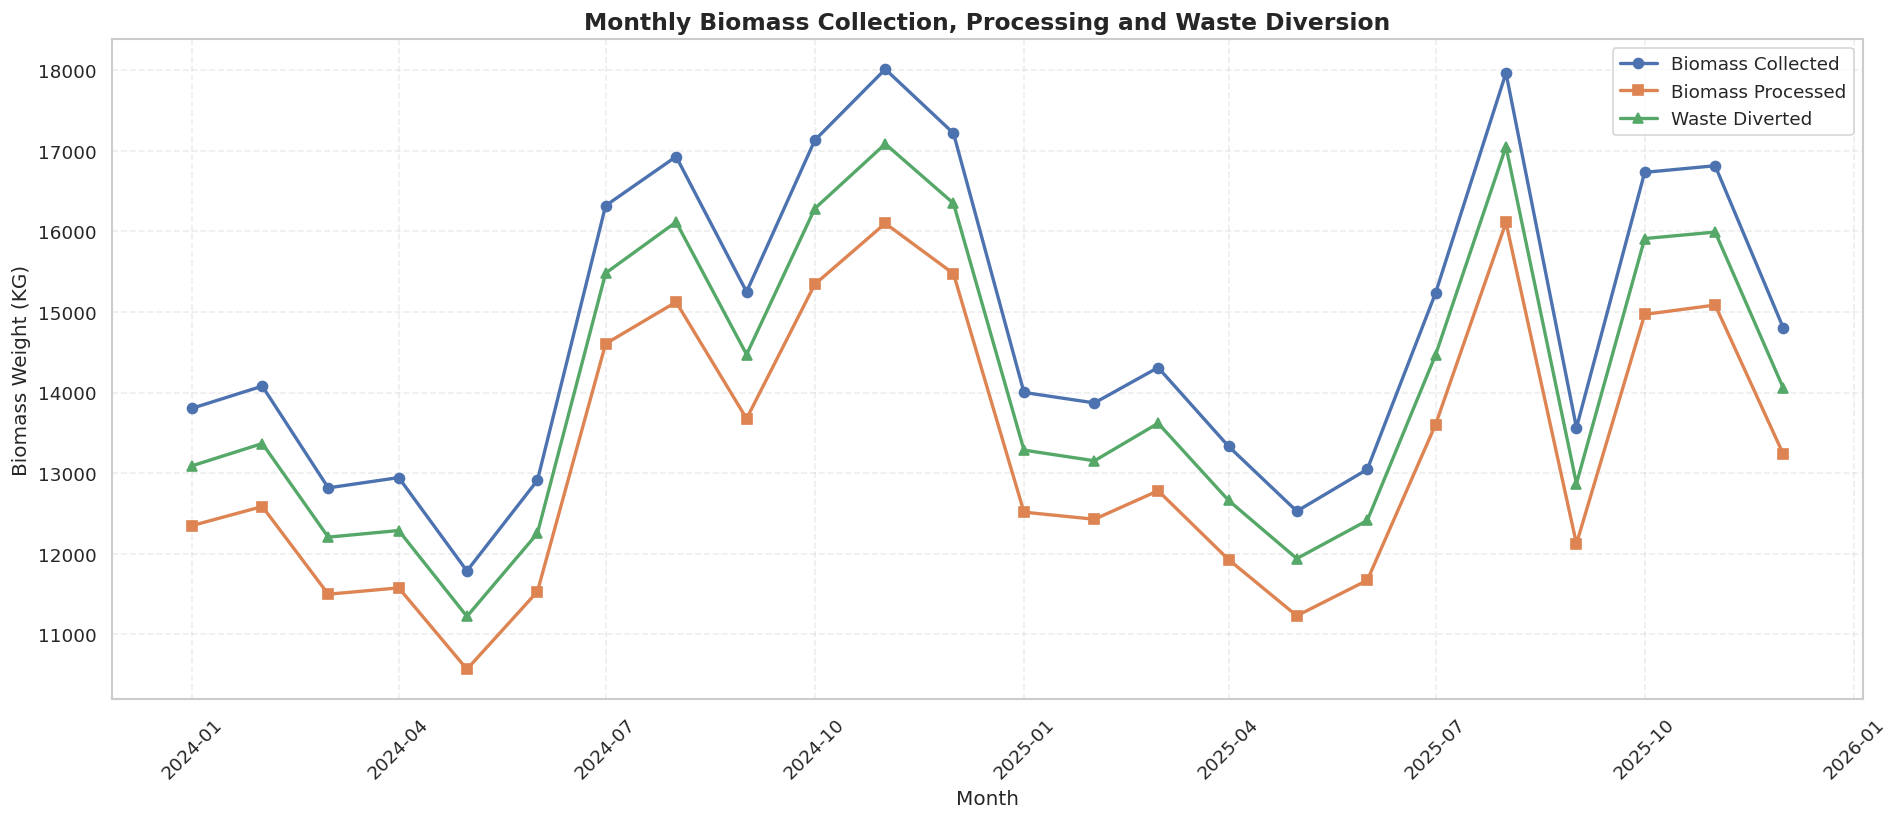


MONTHLY BIOMASS OPERATIONS
-------------------------------------------------------------------------------------


,Month,Biomass_Collected_KG,Biomass_Processed_KG,Waste_Diverted_KG,Processing_Utilization_Percent,Collection_Processing_Gap_KG,Processing_Exceeds_Collection
0,2024-01-01 00:00:00,"13,804.53","12,349.79","13,091.20",89.46%,"1,454.74",False
1,2024-02-01 00:00:00,"14,080.24","12,587.23","13,368.58",89.40%,"1,493.01",False
2,2024-03-01 00:00:00,"12,818.46","11,499.23","12,207.41",89.71%,"1,319.23",False
3,2024-04-01 00:00:00,"12,945.77","11,578.20","12,289.33",89.44%,"1,367.57",False
4,2024-05-01 00:00:00,"11,787.96","10,568.80","11,223.73",89.66%,"1,219.16",False
5,2024-06-01 00:00:00,"12,911.55","11,532.01","12,254.44",89.32%,"1,379.54",False
6,2024-07-01 00:00:00,"16,318.57","14,605.78","15,481.88",89.50%,"1,712.79",False
7,2024-08-01 00:00:00,"16,927.38","15,123.71","16,115.56",89.34%,"1,803.67",False
8,2024-09-01 00:00:00,"15,249.70","13,676.63","14,472.48",89.68%,"1,573.07",False
9,2024-10-01 00:00:00,"17,130.21","15,343.62","16,283.01",89.57%,"1,786.59",False



OPERATIONAL FINDINGS
-------------------------------------------------------------------------------------
Months Analyzed: 24
Months Where Processing Exceeded Collection: 0
Total Collection-Processing Gap: 37,276.90 kg

Biomass analysis completed successfully.


In [92]:
print("=" * 85) 
print("JALWEALTH AI | BIOMASS COLLECTION AND PROCESSING ANALYSIS") 
print("=" * 85) 
 
# ------------------------------------------------------------ 
# 1. Aggregate biomass indicators 
# ------------------------------------------------------------ 
 
biomass_analysis = ( 
    environmental_analysis_df 
    .groupby("Month") 
    .agg( 
 
        Biomass_Collected_KG=( 
            "Water hyacinth collected (kg)", 
            "sum" 
        ), 
 
        Biomass_Processed_KG=( 
            "Water hyacinth processed (kg)", 
            "sum" 
        ), 
 
        Waste_Diverted_KG=( 
            "Waste diverted (kg)", 
            "sum" 
        ) 
 
    ) 
    .sort_index() 
    .reset_index() 
) 
 
# ------------------------------------------------------------ 
# 2. Calculate monthly processing utilization 
# ------------------------------------------------------------ 
 
biomass_analysis["Processing_Utilization_Percent"] = ( 
    biomass_analysis["Biomass_Processed_KG"] 
    .div( 
        biomass_analysis["Biomass_Collected_KG"] 
        .replace(0, np.nan) 
    ) 
    * 100 
) 
 
# ------------------------------------------------------------ 
# 3. Calculate collection-processing gap 
# ------------------------------------------------------------ 
 
biomass_analysis["Collection_Processing_Gap_KG"] = ( 
    biomass_analysis["Biomass_Collected_KG"] 
    - biomass_analysis["Biomass_Processed_KG"] 
) 
 
# ------------------------------------------------------------ 
# 4. Flag months with processing greater than collection 
# ------------------------------------------------------------ 
 
biomass_analysis["Processing_Exceeds_Collection"] = ( 
    biomass_analysis["Biomass_Processed_KG"] 
    > biomass_analysis["Biomass_Collected_KG"] 
) 
 
# ------------------------------------------------------------ 
# 5. Create biomass comparison chart 
# ------------------------------------------------------------ 
 
fig, ax = plt.subplots(figsize=(16, 7)) 
 
ax.plot( 
    biomass_analysis["Month"], 
    biomass_analysis["Biomass_Collected_KG"], 
    marker="o", 
    linewidth=2, 
    label="Biomass Collected" 
) 
 
ax.plot( 
    biomass_analysis["Month"], 
    biomass_analysis["Biomass_Processed_KG"], 
    marker="s", 
    linewidth=2, 
    label="Biomass Processed" 
) 
 
ax.plot( 
    biomass_analysis["Month"], 
    biomass_analysis["Waste_Diverted_KG"], 
    marker="^", 
    linewidth=2, 
    label="Waste Diverted" 
) 
 
ax.set_title( 
    "Monthly Biomass Collection, Processing and Waste Diversion", 
    fontsize=14, 
    fontweight="bold" 
) 
 
ax.set_xlabel("Month") 
ax.set_ylabel("Biomass Weight (KG)") 
 
ax.grid( 
    True, 
    linestyle="--", 
    alpha=0.35 
) 
 
ax.legend() 
 
plt.xticks(rotation=45) 
plt.tight_layout() 
 
plt.savefig( 
    CHART_DIR / "monthly_biomass_operations.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show() 
 
# ------------------------------------------------------------ 
# 6. Display biomass operational report 
# ------------------------------------------------------------ 
 
print("\nMONTHLY BIOMASS OPERATIONS") 
print("-" * 85) 
 
display( 
    biomass_analysis.style.format({ 
        "Biomass_Collected_KG": "{:,.2f}", 
        "Biomass_Processed_KG": "{:,.2f}", 
        "Waste_Diverted_KG": "{:,.2f}", 
        "Processing_Utilization_Percent": "{:,.2f}%", 
        "Collection_Processing_Gap_KG": "{:,.2f}" 
    }) 
) 
 
# ------------------------------------------------------------ 
# 7. Generate operational findings 
# ------------------------------------------------------------ 
 
excess_processing_months = biomass_analysis[ 
    biomass_analysis["Processing_Exceeds_Collection"] 
] 
 
print("\nOPERATIONAL FINDINGS") 
print("-" * 85) 
 
print( 
    "Months Analyzed:", 
    len(biomass_analysis) 
) 
 
print( 
    "Months Where Processing Exceeded Collection:", 
    len(excess_processing_months) 
) 
 
print( 
    "Total Collection-Processing Gap:", 
    f"{biomass_analysis['Collection_Processing_Gap_KG'].sum():,.2f} kg" 
) 
 
if not excess_processing_months.empty: 
 
    print( 
        "\nWARNING: Some months show processing greater than collection." 
    ) 
 
    print( 
        excess_processing_months[ 
            ["Month", "Biomass_Collected_KG", "Biomass_Processed_KG"] 
        ].to_string(index=False) 
    ) 
 
    print( 
        "\nInvestigate inventory carried forward, " 
        "measurement timing and source data definitions." 
    ) 
 
# ------------------------------------------------------------ 
# 8. Export biomass analysis 
# ------------------------------------------------------------ 
 
biomass_analysis.to_csv( 
    REPORT_DIR / "Monthly_Biomass_Operations_Analysis.csv", 
    index=False 
) 
 
print("\nBiomass analysis completed successfully.") 

In [93]:
 # MONTHLY WASTE DIVERSION PERFORMANCE 

JALWEALTH AI | MONTHLY WASTE DIVERSION PERFORMANCE


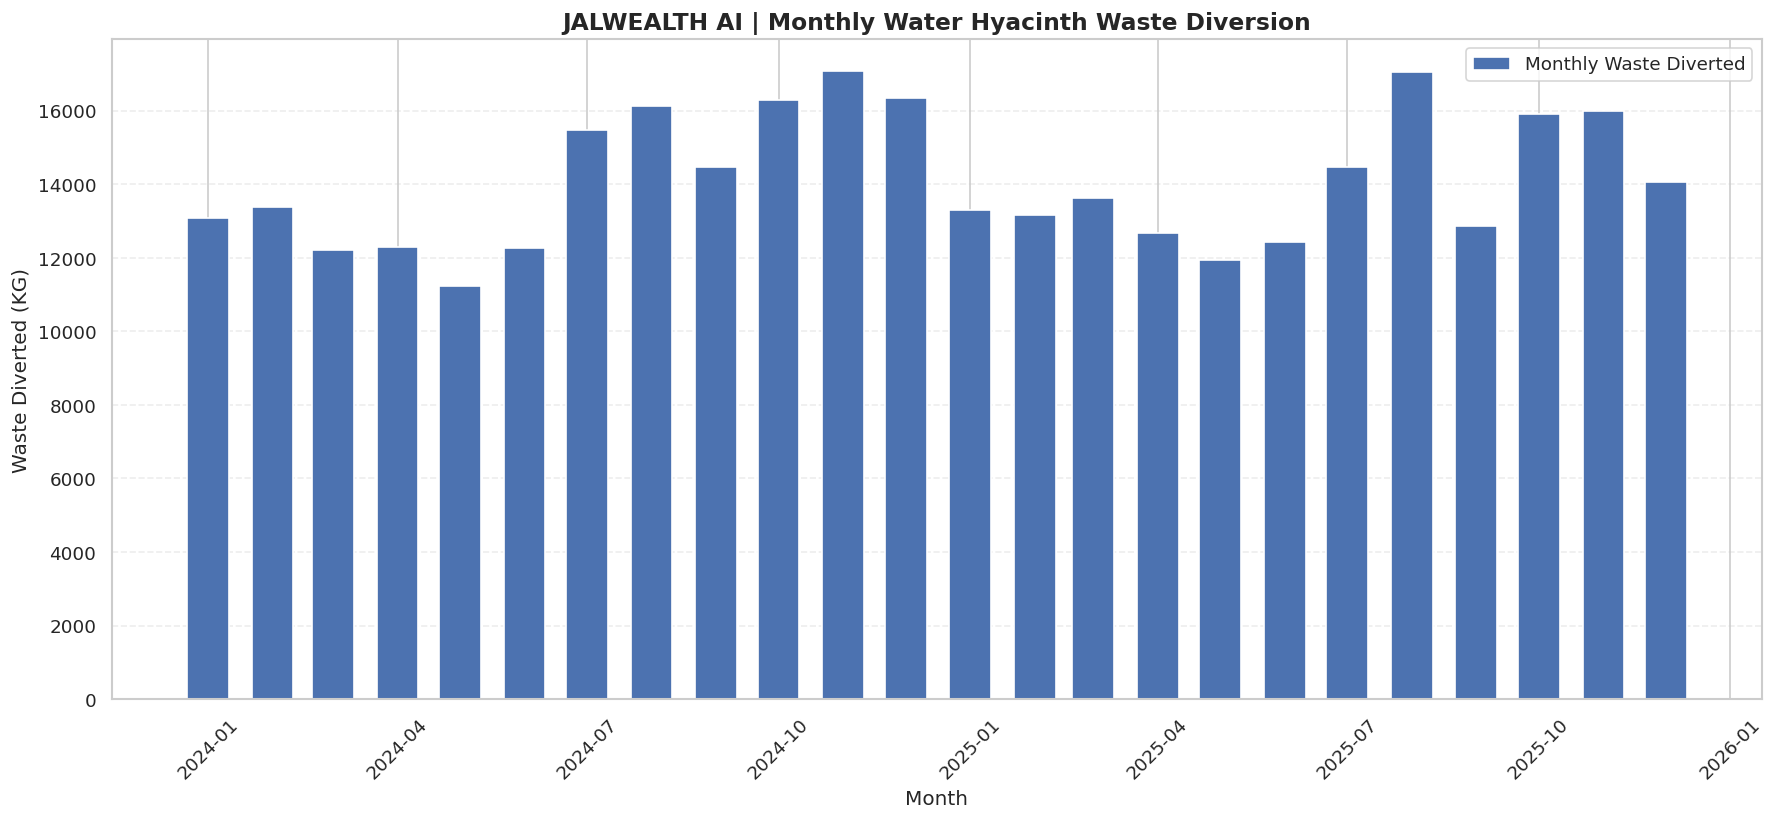


WASTE DIVERSION SUMMARY
-------------------------------------------------------------------------------------
Total Waste Diverted: 337,640.54 kg
Average Monthly Diversion: 14,068.36 kg
Peak Diversion Month: November 2024
Peak Monthly Diversion: 17,084.90 kg

Waste diversion analysis completed.


In [94]:
print("=" * 85) 
print("JALWEALTH AI | MONTHLY WASTE DIVERSION PERFORMANCE") 
print("=" * 85) 
 
# ------------------------------------------------------------ 
# 1. Aggregate monthly waste diversion 
# ------------------------------------------------------------ 
 
waste_diversion_analysis = ( 
    environmental_analysis_df 
    .groupby("Month") 
    .agg( 
 
        Waste_Diverted_KG=( 
            "Waste diverted (kg)", 
            "sum" 
        ), 
 
        Biomass_Collected_KG=( 
            "Water hyacinth collected (kg)", 
            "sum" 
        ), 
 
        Biomass_Processed_KG=( 
            "Water hyacinth processed (kg)", 
            "sum" 
        ) 
 
    ) 
    .sort_index() 
    .reset_index() 
) 
 
# ------------------------------------------------------------ 
# 2. Calculate diversion ratios 
# ------------------------------------------------------------ 
 
waste_diversion_analysis["Diversion_vs_Collected_Percent"] = ( 
    waste_diversion_analysis["Waste_Diverted_KG"] 
    .div( 
        waste_diversion_analysis["Biomass_Collected_KG"] 
        .replace(0, np.nan) 
    ) 
    * 100 
) 
 
waste_diversion_analysis["Diversion_vs_Processed_Percent"] = ( 
    waste_diversion_analysis["Waste_Diverted_KG"] 
    .div( 
        waste_diversion_analysis["Biomass_Processed_KG"] 
        .replace(0, np.nan) 
    ) 
    * 100 
) 
 
# ------------------------------------------------------------ 
# 3. Calculate cumulative waste diversion 
# ------------------------------------------------------------ 
 
waste_diversion_analysis["Cumulative_Waste_Diverted_KG"] = ( 
    waste_diversion_analysis["Waste_Diverted_KG"].cumsum() 
) 
 
# ------------------------------------------------------------ 
# 4. Visualize monthly waste diversion 
# ------------------------------------------------------------ 
 
fig, ax = plt.subplots(figsize=(15, 7)) 
 
ax.bar( 
    waste_diversion_analysis["Month"], 
    waste_diversion_analysis["Waste_Diverted_KG"], 
    width=20, 
    label="Monthly Waste Diverted" 
) 
 
ax.set_title( 
    "JALWEALTH AI | Monthly Water Hyacinth Waste Diversion", 
    fontsize=14, 
    fontweight="bold" 
) 
 
ax.set_xlabel("Month") 
ax.set_ylabel("Waste Diverted (KG)") 
 
ax.grid( 
    axis="y", 
    linestyle="--", 
    alpha=0.35 
) 
 
ax.legend() 
 
plt.xticks(rotation=45) 
plt.tight_layout() 
 
plt.savefig( 
    CHART_DIR / "monthly_waste_diversion.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show() 
 
# ------------------------------------------------------------ 
# 5. Calculate total diversion statistics 
# ------------------------------------------------------------ 
 
total_monthly_diversion = float( 
    waste_diversion_analysis["Waste_Diverted_KG"].sum() 
) 
 
average_monthly_diversion = float( 
    waste_diversion_analysis["Waste_Diverted_KG"].mean() 
) 
 
peak_diversion_month = waste_diversion_analysis.loc[ 
    waste_diversion_analysis["Waste_Diverted_KG"].idxmax() 
] 
 
# ------------------------------------------------------------ 
# 6. Display waste diversion insights 
# ------------------------------------------------------------ 
 
print("\nWASTE DIVERSION SUMMARY") 
print("-" * 85) 
 
print( 
    f"Total Waste Diverted: " 
    f"{total_monthly_diversion:,.2f} kg" 
) 
 
print( 
    f"Average Monthly Diversion: " 
    f"{average_monthly_diversion:,.2f} kg" 
) 
 
print( 
    "Peak Diversion Month:", 
    peak_diversion_month["Month"].strftime("%B %Y") 
) 
print( 
f"Peak Monthly Diversion: " 
f"{peak_diversion_month['Waste_Diverted_KG']:,.2f} kg" 
) 
# ------------------------------------------------------------ 
# 7. Export report 
# ------------------------------------------------------------ 
waste_diversion_analysis.to_csv( 
REPORT_DIR / "Monthly_Waste_Diversion_Report.csv", 
index=False 
) 
print("\nWaste diversion analysis completed.")

In [95]:
# MANUFACTURING PRODUCTIVITY & BIOMASS UTILIZATION 

JALWEALTH AI | MANUFACTURING PRODUCTIVITY ANALYSIS

MONTHLY MANUFACTURING PRODUCTIVITY
-------------------------------------------------------------------------------------


,Month,Biomass_Processed_KG,Finished_Products,Artisan_Employment_Days,Products_Per_KG_Processed,KG_Processed_Per_Product,Products_Per_Artisan_Day,Artisan_Days_Per_1000_KG
0,2024-01-01 00:00:00,"12,349.79","5,049","3,136",0.4088,2.4460,1.6103,253.89
1,2024-02-01 00:00:00,"12,587.23","5,243","3,250",0.4165,2.4008,1.6132,258.20
2,2024-03-01 00:00:00,"11,499.23","5,039","3,022",0.4382,2.2820,1.6674,262.80
3,2024-04-01 00:00:00,"11,578.20","4,863","2,932",0.4200,2.3809,1.6586,253.24
4,2024-05-01 00:00:00,"10,568.80","5,001","2,784",0.4732,2.1133,1.7965,263.39
5,2024-06-01 00:00:00,"11,532.01","4,833","2,999",0.4191,2.3861,1.6116,260.05
6,2024-07-01 00:00:00,"14,605.78","5,720","3,628",0.3916,2.5535,1.5766,248.39
7,2024-08-01 00:00:00,"15,123.71","5,977","3,794",0.3952,2.5303,1.5755,250.85
8,2024-09-01 00:00:00,"13,676.63","5,705","3,565",0.4171,2.3973,1.6001,260.70
9,2024-10-01 00:00:00,"15,343.62","6,505","3,906",0.4240,2.3587,1.6654,254.56


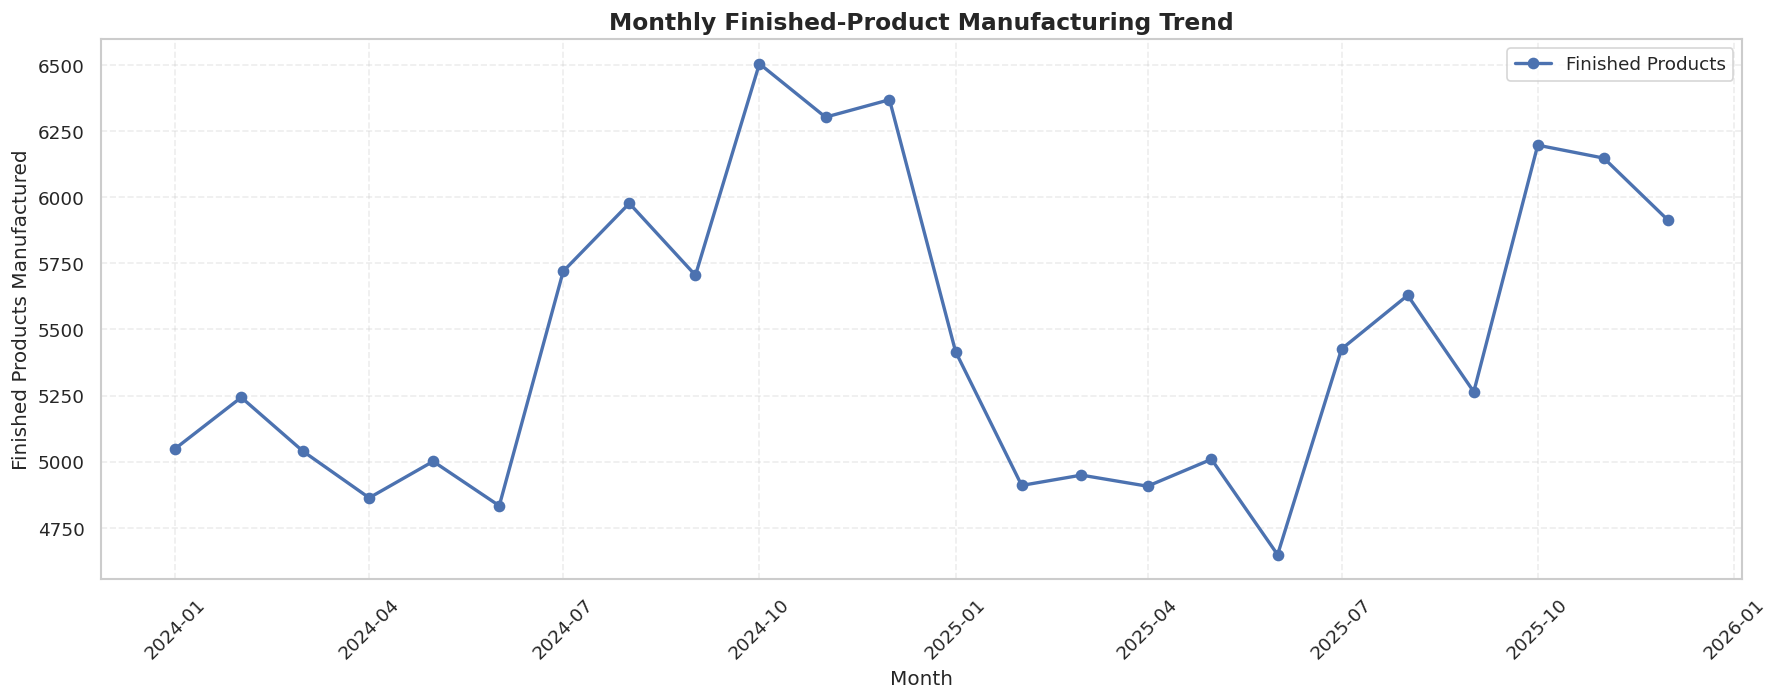

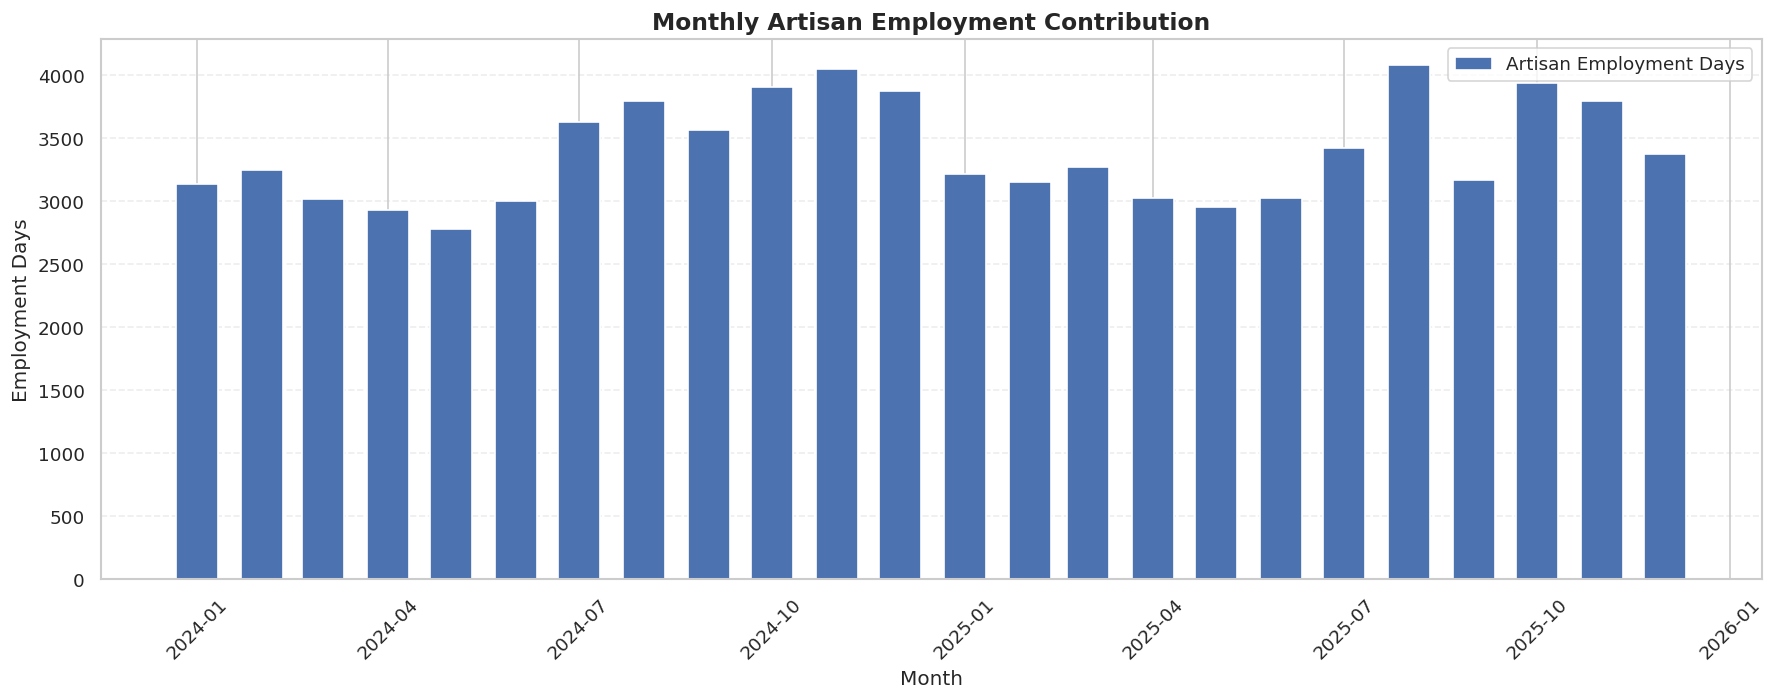


Manufacturing productivity analysis completed.


In [96]:
print("=" * 85) 
print("JALWEALTH AI | MANUFACTURING PRODUCTIVITY ANALYSIS") 
print("=" * 85) 
# ------------------------------------------------------------ 
# 1. Aggregate monthly manufacturing indicators 
# ------------------------------------------------------------ 
manufacturing_analysis = ( 
environmental_analysis_df 
.groupby("Month") 
.agg( 
        Biomass_Processed_KG=( 
            "Water hyacinth processed (kg)", 
            "sum" 
        ), 
 
        Finished_Products=( 
            "Finished products manufactured", 
            "sum" 
        ), 
 
        Artisan_Employment_Days=( 
            "Artisan employment days", 
            "sum" 
        ) 
 
    ) 
    .sort_index() 
    .reset_index() 
) 
 
# ------------------------------------------------------------ 
# 2. Calculate manufacturing productivity 
# ------------------------------------------------------------ 
 
manufacturing_analysis["Products_Per_KG_Processed"] = ( 
    manufacturing_analysis["Finished_Products"] 
    .div( 
        manufacturing_analysis["Biomass_Processed_KG"] 
        .replace(0, np.nan) 
    ) 
) 
 
manufacturing_analysis["KG_Processed_Per_Product"] = ( 
    manufacturing_analysis["Biomass_Processed_KG"] 
    .div( 
        manufacturing_analysis["Finished_Products"] 
        .replace(0, np.nan) 
    ) 
) 
 
# ------------------------------------------------------------ 
# 3. Calculate artisan productivity indicators 
# ------------------------------------------------------------ 
 
manufacturing_analysis["Products_Per_Artisan_Day"] = ( 
    manufacturing_analysis["Finished_Products"] 
    .div( 
        manufacturing_analysis["Artisan_Employment_Days"] 
        .replace(0, np.nan) 
    ) 
) 
 
manufacturing_analysis["Artisan_Days_Per_1000_KG"] = ( 
    manufacturing_analysis["Artisan_Employment_Days"] 
    .div( 
        manufacturing_analysis["Biomass_Processed_KG"] 
        .replace(0, np.nan) 
    ) 
    * 1000 
) 
 
# ------------------------------------------------------------ 
# 4. Display manufacturing analysis 
# ------------------------------------------------------------ 
 
print("\nMONTHLY MANUFACTURING PRODUCTIVITY") 
print("-" * 85) 
 
display( 
    manufacturing_analysis.style.format({ 
        "Biomass_Processed_KG": "{:,.2f}", 
        "Finished_Products": "{:,.0f}", 
        "Artisan_Employment_Days": "{:,.0f}", 
        "Products_Per_KG_Processed": "{:,.4f}", 
        "KG_Processed_Per_Product": "{:,.4f}", 
        "Products_Per_Artisan_Day": "{:,.4f}", 
        "Artisan_Days_Per_1000_KG": "{:,.2f}" 
    }) 
) 
 
# ------------------------------------------------------------ 
# 5. Visualize finished-product manufacturing 
# ------------------------------------------------------------ 
 
fig, ax = plt.subplots(figsize=(15, 6)) 
 
ax.plot( 
    manufacturing_analysis["Month"], 
    manufacturing_analysis["Finished_Products"], 
    marker="o", 
    linewidth=2, 
    label="Finished Products" 
) 
 
ax.set_title( 
    "Monthly Finished-Product Manufacturing Trend", 
    fontsize=14, 
    fontweight="bold" 
) 
 
ax.set_xlabel("Month") 
ax.set_ylabel("Finished Products Manufactured") 
 
ax.grid( 
    True, 
    linestyle="--", 
    alpha=0.35 
) 
 
ax.legend() 
 
plt.xticks(rotation=45) 
plt.tight_layout() 
 
plt.savefig( 
    CHART_DIR / "monthly_manufacturing_trend.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show() 
 
# ------------------------------------------------------------ 
# 6. Visualize artisan employment trend 
# ------------------------------------------------------------ 
 
fig, ax = plt.subplots(figsize=(15, 6)) 
 
ax.bar( 
    manufacturing_analysis["Month"], 
    manufacturing_analysis["Artisan_Employment_Days"], 
    width=20, 
    label="Artisan Employment Days" 
) 
 
ax.set_title( 
    "Monthly Artisan Employment Contribution", 
    fontsize=14, 
    fontweight="bold" 
) 
 
ax.set_xlabel("Month") 
ax.set_ylabel("Employment Days") 
 
ax.grid( 
    axis="y", 
    linestyle="--", 
    alpha=0.35 
) 
 
ax.legend() 
 
plt.xticks(rotation=45) 
plt.tight_layout() 
 
plt.savefig( 
    CHART_DIR / "monthly_artisan_employment.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show() 
 
# ------------------------------------------------------------ 
# 7. Export manufacturing report 
# ------------------------------------------------------------ 
 
manufacturing_analysis.to_csv( 
    REPORT_DIR / "Manufacturing_Productivity_Analysis.csv", 
    index=False 
) 
 
print("\nManufacturing productivity analysis completed.")

In [97]:
 # ENVIRONMENTAL & MANUFACTURING PERFORMANCE DASHBOARD

JALWEALTH AI | INTEGRATED ENVIRONMENTAL PERFORMANCE DASHBOARD


,Performance Indicator,Value
0,Biomass Collected (KG),"355,404.77"
1,Biomass Processed (KG),"318,127.87"
2,Waste Diverted (KG),"337,640.54"
3,Finished Products,"131,024.00"
4,Artisan Employment Days,"81,384.94"
5,Processing Utilization (%),89.51
6,Waste Diversion Ratio (%),95.00


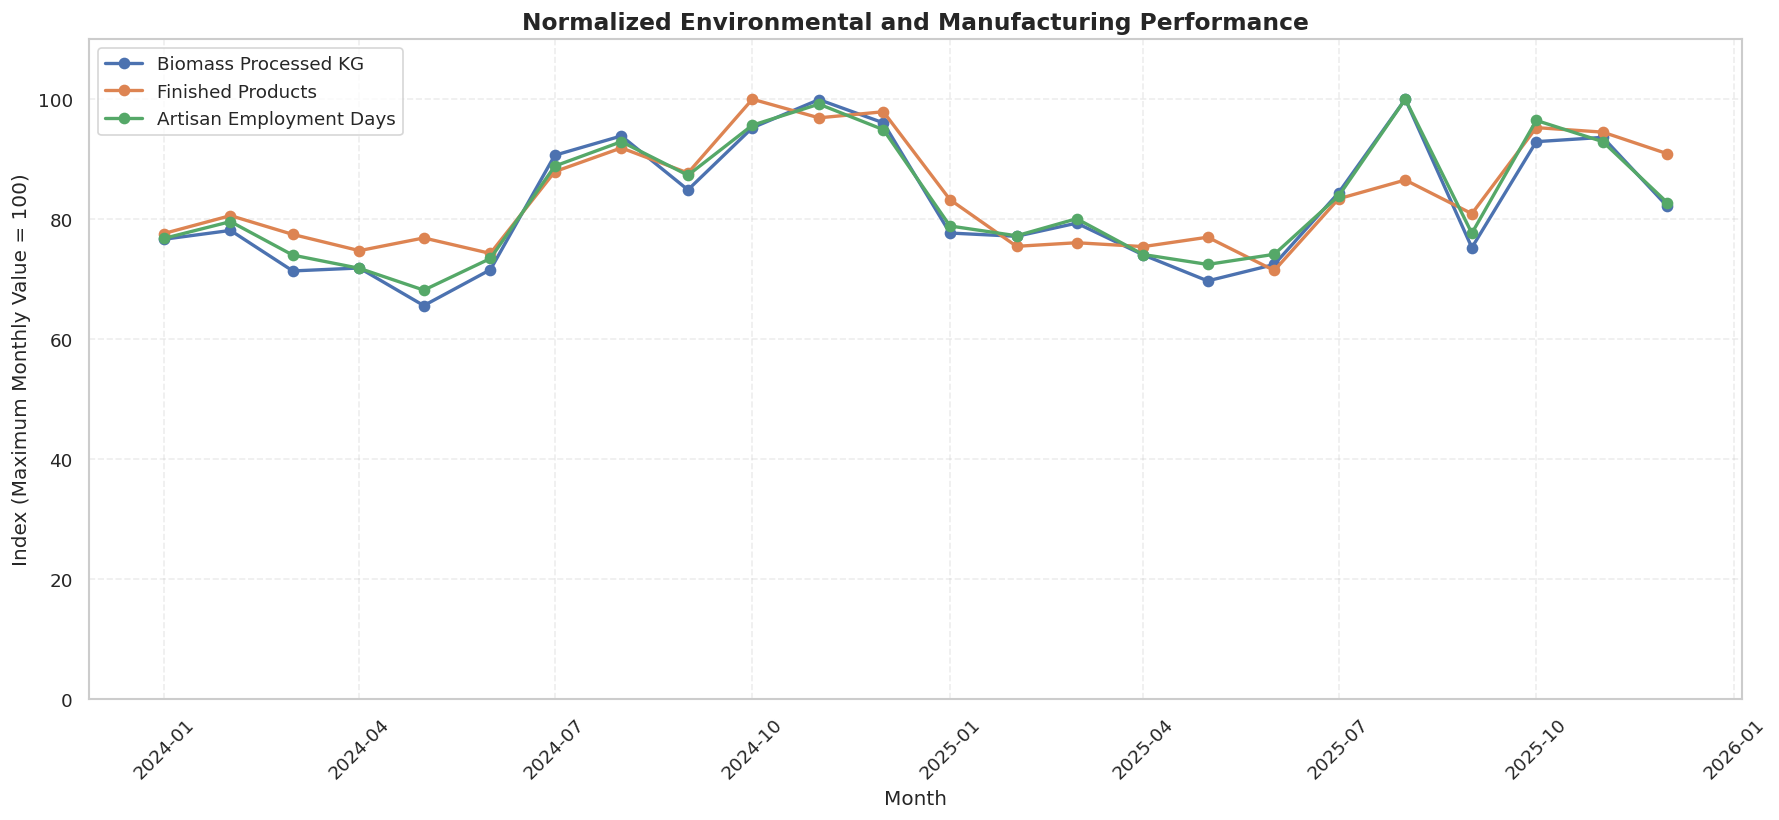


Dashboard datasets exported successfully.


In [98]:
print("=" * 85) 
print("JALWEALTH AI | INTEGRATED ENVIRONMENTAL PERFORMANCE DASHBOARD") 
print("=" * 85) 
 
# ------------------------------------------------------------ 
# 1. Prepare dashboard metrics 
# ------------------------------------------------------------ 
 
dashboard_metrics = { 
 
    "Biomass Collected (KG)": total_collected, 
 
    "Biomass Processed (KG)": total_processed, 
 
    "Waste Diverted (KG)": total_diverted, 
 
    "Finished Products": total_products, 
 
    "Artisan Employment Days": total_artisan_days, 
 
    "Processing Utilization (%)": processing_utilization_rate, 
 
    "Waste Diversion Ratio (%)": waste_diversion_ratio 
 
} 
 
dashboard_df = pd.DataFrame( 
    list(dashboard_metrics.items()), 
    columns=["Performance Indicator", "Value"] 
) 
 
# ------------------------------------------------------------ 
# 2. Display dashboard metrics 
# ------------------------------------------------------------ 
 
display( 
    dashboard_df.style.format({ 
        "Value": "{:,.2f}" 
    }) 
) 
 
# ------------------------------------------------------------ 
# 3. Create normalized performance comparison 
# ------------------------------------------------------------ 
 
comparison_metrics = [ 
    "Biomass_Processed_KG", 
    "Finished_Products", 
    "Artisan_Employment_Days" 
] 
 
comparison_df = manufacturing_analysis[ 
    ["Month"] + comparison_metrics 
].copy() 
 
for column in comparison_metrics: 
 
    maximum_value = comparison_df[column].max() 
 
    if maximum_value > 0: 
 
        comparison_df[column + "_Index"] = ( 
            comparison_df[column] / maximum_value * 100 
        ) 
 
    else: 
 
        comparison_df[column + "_Index"] = 0 
 
# ------------------------------------------------------------ 
# 4. Plot normalized monthly operational indicators 
# ------------------------------------------------------------ 
 
fig, ax = plt.subplots(figsize=(15, 7)) 
 
for column in comparison_metrics: 
 
    ax.plot( 
        comparison_df["Month"], 
        comparison_df[column + "_Index"], 
        marker="o", 
        linewidth=2, 
        label=column.replace("_", " ") 
    ) 
 
ax.set_title( 
    "Normalized Environmental and Manufacturing Performance", 
    fontsize=14, 
    fontweight="bold" 
) 
 
ax.set_xlabel("Month") 
ax.set_ylabel("Index (Maximum Monthly Value = 100)") 
 
ax.set_ylim(0, 110) 
 
ax.grid( 
    True, 
    linestyle="--", 
    alpha=0.35 
) 
 
ax.legend() 
 
plt.xticks(rotation=45) 
plt.tight_layout() 
 
plt.savefig( 
    CHART_DIR / "normalized_environmental_performance.png", 
    dpi=300, 
    bbox_inches="tight" 
) 
 
plt.show() 
 
# ------------------------------------------------------------ 
# 5. Export dashboard datasets 
# ------------------------------------------------------------ 
 
dashboard_df.to_csv( 
    REPORT_DIR / "Environmental_Executive_Dashboard_Metrics.csv", 
index=False 
) 
comparison_df.to_csv( 
REPORT_DIR / "Normalized_Operational_Performance.csv", 
index=False 
) 
print("\nDashboard datasets exported successfully.")

# Environmental Performance Insights

## 1. Biomass Utilization 
The analysis evaluates the relationship between water hyacinth collection and processing. The 
collection-processing gap can help identify potential operational bottlenecks and the need for 
better inventory planning. 
    
## 2. Waste Diversion 
Monthly waste diversion measurements provide an overview of the quantity recorded as 
diverted through the business process.
    
## 3. Manufacturing Productivity 
Finished-product manufacturing is compared with biomass processing to understand 
operational output. 
    
## 4. Artisan Employment Contribution 
Artisan employment days are analyzed as an indicator of recorded labour participation and 
operational activity. 
    
## 5. Management Applications 
The findings can support: 
- Biomass procurement planning. 
- Processing-capacity assessment.
- Inventory and storage management.
- Manufacturing productivity monitoring.
- Artisan workday planning. 
- Environmental performance reporting. 
    
## 6. Data Limitations 
- Environmental indicators are based on the supplied dataset.
- Additive aggregation assumes each row records an incremental quantity rather than a repeated cumulative total. 
- Monthly processing gaps are not equivalent to verified inventory changes.
- Product weights and composition are not available for calculating physical manufacturing yield. 
- Employment days cannot establish the number of unique artisans.
- Carbon reduction, biodiversity recovery and water-quality improvement cannot be quantified from these indicators alone. 

**Conclusion:** The environmental analysis creates a measurable operational framework for 
monitoring biomass utilization, waste diversion, manufacturing output and artisan employment.

 # Conclusion: Environmental Impact Intelligence 

This phase developed an environmental and manufacturing performance analysis framework for JALWEALTH AI. 
The framework evaluates: 
1. Total water hyacinth collected. 
2. Total biomass processed. 
3. Recorded waste diversion. 
4. Biomass processing utilization. 
5. Finished-product manufacturing. 
6. Artisan employment days. 
7. Monthly operational performance. 
8. Manufacturing productivity indicators.
    
## Business Value 
The results can help management understand the relationship between raw-material collection, 
processing capacity, manufacturing activity and employment contribution. 
    
## Key Deliverables
- Environmental data quality report. 
- Environmental KPI summary.
- Monthly biomass operations analysis.
- Waste diversion report.
- Manufacturing productivity analysis. 
- Environmental performance dashboard.
- Monthly operational visualizations. 
    
## Final Assessment 
Environmental performance should be evaluated using transparent, traceable and clearly 
defined indicators. 
The model does not claim independently verified ecological restoration or carbon reduction. 
Such claims require additional measurement data and appropriate scientific assessment.